# Phase 3 – Deep Learning, Foundation Models, TimeGPT & AutoGluon
### M5 Forecasting Project — Time Series Forecasting in Retail (Walmart M5 Dataset)

## Group Members
- Beatriz Teixeira
- João Coelho

## Selected Series
- **Category / Department:** Foods → **FOODS_1**
- **State / Store:** Texas → **TX_1**
- **Panel:** FOODS_1 / TX_1 (216 product-level series)
- **Forecasting horizon:** 28 days (matching the M5 Competition setup)
- **Main evaluation metric:** RMSSE

## Goal of Phase 3
This notebook extends the M5 forecasting project from the statistical baselines (Phase 1)
and machine learning models (Phase 2) to advanced forecasting approaches: deep learning
(NHITS, LSTM and their automatically tuned variants AutoNHITS / AutoLSTM), pre-trained
foundation models (Chronos and TimeGPT), and automated modelling with ensembling
(AutoGluon-TimeSeries). The same FOODS_1 / TX_1 panel, the same 28-day horizon and the
same RMSSE metric are reused throughout, so that all three phases can be compared fairly.
Both point forecasts and probabilistic forecasts are produced for the final 28-day horizon.

## Environment Setup

This section prepares the Colab environment for Phase 3.

The notebook uses:

- **NeuralForecast** for deep learning forecasting models such as NHITS and LSTM.
- **Chronos** as an open-source pre-trained / foundation time series model.
- **TimeGPT** through the Nixtla API as an optional API-based foundation model.
- **AutoGluon-TimeSeries** for automated time series modelling and ensembling.
- **StatsForecast**, **PyArrow**, **Pandas** and **NumPy** for data preparation and evaluation.

In [ ]:
import subprocess
import sys
import os

def run_pip(command):
    """Run pip commands inside the current notebook environment."""
    subprocess.check_call([sys.executable, "-m", "pip"] + command)

print("Removing potentially conflicting packages...")
run_pip(["uninstall", "-y", "torchvision", "torchmetrics", "pytorch-lightning", "lightning", "neuralforecast"])

print("Installing stable deep learning dependencies...")
run_pip(["install", "-q", "torch==2.5.1", "torchaudio==2.5.1"])
run_pip(["install", "-q", "torchmetrics==1.4.3", "pytorch-lightning==2.4.0", "lightning==2.4.0"])
run_pip(["install", "-q", "neuralforecast==1.7.7", "optuna"])

print("Installing forecasting, foundation-model and AutoML packages...")
run_pip(["install", "-q", "statsforecast", "pyarrow", "nixtla"])
run_pip(["install", "-q", "chronos-forecasting"])
run_pip(["install", "-q", "autogluon.timeseries"])
run_pip(["uninstall", "-y", "torchvision"])

print("\nEnvironment setup completed.")
print("If this is the first time running the setup in this runtime, restart the runtime and run all cells again.")
print("In Colab: Runtime → Restart runtime, then Runtime → Run all.")

Removing potentially conflicting packages...
Installing stable deep learning dependencies...
Installing forecasting, foundation-model and AutoML packages...

Environment setup completed.
If this is the first time running the setup in this runtime, restart the runtime and run all cells again.
In Colab: Runtime → Restart runtime, then Runtime → Run all.


In [ ]:
import torch
import importlib.util

print("torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("torchvision installed:", importlib.util.find_spec("torchvision") is not None)

try:
    import torchmetrics
    import neuralforecast
    print("torchmetrics:", torchmetrics.__version__)
    print("neuralforecast:", neuralforecast.__version__)
    print("Environment validation completed successfully.")
except RuntimeError as e:
    if "torchvision::nms" in str(e):
        raise RuntimeError(
            "PyTorch/TorchVision conflict detected. Run the environment setup cell above, "
            "restart the Colab runtime, and then run all cells again."
        ) from e
    raise


torch: 2.9.1+cu128
CUDA available: True
torchvision installed: False
torchmetrics: 1.4.3
neuralforecast: 1.7.7
Environment validation completed successfully.


## Imports and General Configuration

All libraries used throughout this notebook are imported here.
Warnings are suppressed to keep the output clean and readable.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import torch

from sklearn.metrics import mean_absolute_error, mean_squared_error

try:
    from neuralforecast import NeuralForecast
    from neuralforecast.models import NHITS, LSTM
    from neuralforecast.auto import AutoNHITS, AutoLSTM
    from neuralforecast.losses.pytorch import MAE
except RuntimeError as e:
    if "torchvision::nms" in str(e):
        raise RuntimeError(
            "The NeuralForecast import failed because of a PyTorch/TorchVision conflict. "
            "Run the Environment Setup cell, restart the Colab runtime, and run the notebook again."
        ) from e
    raise

try:
    from chronos import ChronosPipeline
except Exception as e:
    ChronosPipeline = None
    print("Chronos import warning:", e)

try:
    from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor
except Exception as e:
    TimeSeriesDataFrame = None
    TimeSeriesPredictor = None
    print("AutoGluon import warning:", e)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
pd.set_option("display.max_columns", 50)

print("Libraries loaded successfully.")
print("GPU available:", torch.cuda.is_available())

Libraries loaded successfully.
GPU available: True


## Execution Flags

This section controls the advanced components required by the Phase 3 statement. In the final version, both **Chronos** and **AutoGluon-TimeSeries** are activated because the assignment explicitly asks to explore foundation models and automated time series modelling with ensembling.

The runtime may be high, especially when using Google Colab without GPU. The values below can be reduced during testing, but the final run should keep the required sections active.

In [ ]:
RUN_CHRONOS = True
RUN_AUTOGLUON = True
RUN_TIMEGPT = True

N_DL_STEPS = 500
N_AUTO_DL_TRIALS = 3
N_AUTO_DL_STEPS = 150

AUTOGLUON_TIME_LIMIT = 600
TIMEGPT_MODEL = "timegpt-1-long-horizon"

if 'ChronosPipeline' in globals() and ChronosPipeline is None:
    RUN_CHRONOS = False
    print("Chronos was not imported successfully, so RUN_CHRONOS was set to False.")

if ('TimeSeriesDataFrame' in globals() and TimeSeriesDataFrame is None) or ('TimeSeriesPredictor' in globals() and TimeSeriesPredictor is None):
    RUN_AUTOGLUON = False
    print("AutoGluon was not imported successfully, so RUN_AUTOGLUON was set to False.")

print(f"RUN_CHRONOS          = {RUN_CHRONOS}")
print(f"RUN_AUTOGLUON        = {RUN_AUTOGLUON}")
print(f"RUN_TIMEGPT          = {RUN_TIMEGPT}")
print(f"N_DL_STEPS           = {N_DL_STEPS}")
print(f"N_AUTO_DL_TRIALS     = {N_AUTO_DL_TRIALS}")
print(f"N_AUTO_DL_STEPS      = {N_AUTO_DL_STEPS}")
print(f"AUTOGLUON_TIME_LIMIT = {AUTOGLUON_TIME_LIMIT} seconds per AutoGluon version")
print(f"TIMEGPT_MODEL        = {TIMEGPT_MODEL}")

RUN_CHRONOS          = True
RUN_AUTOGLUON        = True
RUN_TIMEGPT          = True
N_DL_STEPS           = 500
N_AUTO_DL_TRIALS     = 3
N_AUTO_DL_STEPS      = 150
AUTOGLUON_TIME_LIMIT = 600 seconds per AutoGluon version
TIMEGPT_MODEL        = timegpt-1-long-horizon


## Google Drive Configuration

The same path logic used in Phases 1 and 2 is maintained.
When running in Google Colab, outputs are saved to Google Drive for persistence between sessions.

In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_PATH = "/content/drive/MyDrive/M5_Forecasting_Project"
    os.makedirs(BASE_PATH, exist_ok=True)
    print(f"Google Drive connected. Files will be saved to: {BASE_PATH}")
except Exception:
    BASE_PATH = "."
    print("Google Drive not available. Using current working directory.")


Mounted at /content/drive
Google Drive connected. Files will be saved to: /content/drive/MyDrive/M5_Forecasting_Project


## Load the M5 Dataset

The target panel (`Y_df`) and exogenous variables (`X_df`) are reloaded from the Nixtla repository,
following the same approach used in Phases 1 and 2.

The same **FOODS_1 / TX_1** department–store selection is applied to ensure full comparability across phases.

In [ ]:
base_url = "https://datasets-nixtla.s3.amazonaws.com"

Y_df = pd.read_parquet(f"{base_url}/m5_y.parquet")
X_df = pd.read_parquet(f"{base_url}/m5_x.parquet")

Y_df["ds"] = pd.to_datetime(Y_df["ds"])
X_df["ds"] = pd.to_datetime(X_df["ds"])

department = "FOODS_1"
store      = "TX_1"
h          = 28

Y_sel = Y_df[
    Y_df["unique_id"].str.contains(department) &
    Y_df["unique_id"].str.contains(store)
].copy()

X_sel = X_df[
    X_df["unique_id"].str.contains(department) &
    X_df["unique_id"].str.contains(store)
].copy()

Y_sel = Y_sel.sort_values(["unique_id", "ds"]).reset_index(drop=True)
X_sel = X_sel.sort_values(["unique_id", "ds"]).reset_index(drop=True)

print(f"Number of series  : {Y_sel['unique_id'].nunique()}")
print(f"Date range        : {Y_sel['ds'].min().date()} to {Y_sel['ds'].max().date()}")
print(f"Y_sel shape       : {Y_sel.shape}")


Number of series  : 216
Date range        : 2011-01-29 to 2016-06-19
Y_sel shape       : (370418, 3)


## Chronological Train / Validation / Test Split

The exact same chronological split used in Phases 1 and 2 is reproduced here.
This is essential to ensure that model comparisons across all phases are fair and directly comparable.

| Set | Period | Purpose |
|---|---|---|
| Train | Before 25 Apr 2016 | Model training |
| Validation | 25 Apr – 22 May 2016 | Model selection and comparison (28 days) |
| Test | 23 May – 19 Jun 2016 | Final evaluation (28 days) |

In [ ]:
test_start = pd.Timestamp("2016-05-23")
val_start  = pd.Timestamp("2016-04-25")
val_end    = pd.Timestamp("2016-05-22")

train_main = Y_sel[Y_sel["ds"] < val_start].copy()
val        = Y_sel[(Y_sel["ds"] >= val_start) & (Y_sel["ds"] <= val_end)].copy()
test       = Y_sel[Y_sel["ds"] >= test_start].copy()

print(f"Train      : {train_main['ds'].min().date()} → {train_main['ds'].max().date()}  ({train_main['ds'].nunique()} days)")
print(f"Validation : {val['ds'].min().date()} → {val['ds'].max().date()}  ({val['ds'].nunique()} days)")
print(f"Test       : {test['ds'].min().date()} → {test['ds'].max().date()}  ({test['ds'].nunique()} days)")


Train      : 2011-01-29 → 2016-04-24  (1913 days)
Validation : 2016-04-25 → 2016-05-22  (28 days)
Test       : 2016-05-23 → 2016-06-19  (28 days)


## Prepare Exogenous Variables

The same exogenous feature set used in Phase 1 (ARIMAX) and Phase 2 is reused here.
It includes calendar features, SNAP indicators and sell price information.

These features will be used by AutoGluon.
NeuralForecast models (NHITS, LSTM) are trained in their univariate version here,
consistent with the global deep learning approach.
Chronos is a univariate zero-shot model and does not use exogenous variables.

In [ ]:
def prepare_exogenous_features(X, store_name="TX_1"):
    X = X.copy()
    X["ds"] = pd.to_datetime(X["ds"])

    X["day_of_week"]  = X["ds"].dt.dayofweek
    X["day_of_month"] = X["ds"].dt.day
    X["month"]        = X["ds"].dt.month
    X["is_weekend"]   = X["day_of_week"].isin([5, 6]).astype(int)

    state_code = store_name.split("_")[0]
    snap_col   = f"snap_{state_code}"
    if snap_col in X.columns:
        X["snap_active"] = X[snap_col].astype(float)

    if "sell_price" in X.columns:
        X["sell_price"] = X["sell_price"].fillna(method="ffill")
        X["log_price"]  = np.log1p(X["sell_price"])

    keep = ["unique_id", "ds", "day_of_week", "day_of_month", "month", "is_weekend"]
    if "snap_active" in X.columns:
        keep.append("snap_active")
    if "log_price" in X.columns:
        keep.append("log_price")

    return X[keep].copy()

X_ml = prepare_exogenous_features(X_sel, store_name="TX_1")
exog_cols = [c for c in X_ml.columns if c not in ["unique_id", "ds"]]

print("Exogenous features:", exog_cols)


Exogenous features: ['day_of_week', 'day_of_month', 'month', 'is_weekend', 'snap_active', 'log_price']


## Evaluation Metrics and Plotting Utilities

The same evaluation functions used across Phases 1 and 2 are maintained here for consistency.

- **MAE** measures the average absolute forecasting error.
- **RMSE** penalises larger errors more strongly than MAE.
- **RMSSE** is the main metric because it is scale-independent and aligned with the M5 evaluation protocol.

This section also defines plotting utilities used later in the notebook. The previous visualisations used a fixed representative product series. That can be misleading when a product has many recent zero-sales days and then a sudden validation spike. To avoid this, the notebook now selects a better visualisation series dynamically and also plots aggregate forecasts across all FOODS_1 / TX_1 products.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def mae_metric(actual, pred):
    return mean_absolute_error(actual, pred)

def rmse_metric(actual, pred):
    return np.sqrt(mean_squared_error(actual, pred))

def rmsse_per_series(train_series, actual, pred):
    """Compute RMSSE for one time series."""
    train_series = np.asarray(train_series, dtype=float)
    actual = np.asarray(actual, dtype=float)
    pred = np.asarray(pred, dtype=float)

    denom = np.mean(np.diff(train_series) ** 2)
    if denom == 0 or np.isnan(denom):
        return np.nan

    return np.sqrt(np.mean((actual - pred) ** 2) / denom)

def evaluate_panel(train_df, actual_df, forecast_df, model_col):
    """Evaluate one model over all product series in the panel."""
    maes, rmses, rmsses = [], [], []
    by_series = []

    for uid in actual_df["unique_id"].unique():
        tr = train_df[train_df["unique_id"] == uid]["y"].values
        ac = actual_df[actual_df["unique_id"] == uid].sort_values("ds")["y"].values
        fc_row = forecast_df[forecast_df["unique_id"] == uid].sort_values("ds")

        if model_col not in fc_row.columns or fc_row.empty:
            continue

        pr = fc_row[model_col].values
        min_len = min(len(ac), len(pr))
        ac, pr = ac[:min_len], pr[:min_len]
        pr = np.clip(pr, 0, None)

        maes.append(mae_metric(ac, pr))
        rmses.append(rmse_metric(ac, pr))
        r = rmsse_per_series(tr, ac, pr)
        rmsses.append(r)

        by_series.append({
            "unique_id": uid,
            "MAE": maes[-1],
            "RMSE": rmses[-1],
            "RMSSE": r,
        })

    return (
        np.nanmean(maes),
        np.nanmean(rmses),
        np.nanmean(rmsses),
        pd.DataFrame(by_series),
    )

def choose_plot_series(train_df, actual_df, forecast_df=None, model_col=None, lookback=90):
    """Choose a stable and readable product series for forecast plots.

    The first notebook selected the product with the highest average sales across the
    whole training period. In this dataset that can select a product whose most recent
    training window is mostly zero, creating misleading plots. This function prefers a
    series with:
    - positive recent training sales;
    - positive validation/test sales;
    - a reasonably non-zero forecast when a forecast dataframe is available;
    - not too large a jump between recent history and validation.
    """
    rows = []
    forecast_df = forecast_df.copy() if forecast_df is not None else None

    for uid in actual_df["unique_id"].unique():
        recent = train_df[train_df["unique_id"] == uid].sort_values("ds").tail(lookback)
        actual = actual_df[actual_df["unique_id"] == uid].sort_values("ds")

        if recent.empty or actual.empty:
            continue

        recent_mean = recent["y"].mean()
        actual_mean = actual["y"].mean()
        recent_nonzero = (recent["y"] > 0).mean()
        actual_nonzero = (actual["y"] > 0).mean()
        jump_penalty = abs(actual_mean - recent_mean)

        forecast_mean = np.nan
        forecast_nonzero = 0.0
        if forecast_df is not None and model_col in forecast_df.columns:
            fc = forecast_df[forecast_df["unique_id"] == uid].sort_values("ds")
            if not fc.empty:
                forecast_values = fc[model_col].clip(lower=0)
                forecast_mean = forecast_values.mean()
                forecast_nonzero = (forecast_values > 0.05).mean()

        score = (
            1.2 * recent_mean
            + 1.2 * actual_mean
            + 8.0 * recent_nonzero
            + 8.0 * actual_nonzero
            - 0.15 * jump_penalty
        )

        if forecast_df is not None and model_col in forecast_df.columns:
            score += 0.6 * np.nan_to_num(forecast_mean, nan=0.0) + 5.0 * forecast_nonzero

        rows.append({
            "unique_id": uid,
            "recent_mean": recent_mean,
            "actual_mean": actual_mean,
            "recent_nonzero": recent_nonzero,
            "actual_nonzero": actual_nonzero,
            "forecast_mean": forecast_mean,
            "forecast_nonzero": forecast_nonzero,
            "score": score,
        })

    candidates = pd.DataFrame(rows)
    if candidates.empty:
        return actual_df["unique_id"].iloc[0], candidates

    readable = candidates[
        (candidates["recent_nonzero"] >= 0.25)
        & (candidates["actual_nonzero"] >= 0.25)
        & (candidates["recent_mean"] > 0.2)
        & (candidates["actual_mean"] > 0.2)
    ].copy()

    if forecast_df is not None and model_col in forecast_df.columns:
        readable_with_forecast = readable[readable["forecast_nonzero"] >= 0.25].copy()
        if not readable_with_forecast.empty:
            readable = readable_with_forecast

    selected_df = readable if not readable.empty else candidates
    selected = selected_df.sort_values("score", ascending=False).iloc[0]["unique_id"]

    return selected, candidates.sort_values("score", ascending=False)

def plot_single_series_forecast(
    train_df,
    actual_df,
    forecast_df,
    model_col,
    title,
    file_name,
    boundary_date,
    sample=None,
    interval_cols=None,
    lookback=120,
):
    """Plot one selected product series with optional prediction intervals."""
    if forecast_df is None or forecast_df.empty or model_col not in forecast_df.columns:
        print(f"Plot skipped: forecast column '{model_col}' not available.")
        return None

    if sample is None:
        sample, candidates = choose_plot_series(
            train_df=train_df,
            actual_df=actual_df,
            forecast_df=forecast_df,
            model_col=model_col,
            lookback=min(lookback, 120),
        )
        print(f"Selected representative series for this plot: {sample}")
        print("Top candidate series for visualisation:")
        display(candidates.head(5))
    else:
        print(f"Using selected series for visualisation: {sample}")

    train_plot = train_df[train_df["unique_id"] == sample].sort_values("ds").tail(lookback).copy()
    actual_plot = actual_df[actual_df["unique_id"] == sample].sort_values("ds").copy()
    fcst_plot = forecast_df[forecast_df["unique_id"] == sample].sort_values("ds").copy()

    if train_plot.empty or actual_plot.empty or fcst_plot.empty:
        print(f"Plot skipped for {sample}: missing train, actual or forecast values.")
        return sample

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(train_plot["ds"], train_plot["y"], label="Recent training history", linewidth=1.8)
    ax.plot(actual_plot["ds"], actual_plot["y"], label="Actual", color="black", linewidth=1.8)
    ax.plot(
        fcst_plot["ds"],
        fcst_plot[model_col].clip(lower=0),
        label=f"{model_col} forecast",
        linestyle="--",
        linewidth=2.2,
    )

    if interval_cols is not None:
        lo80, hi80, lo95, hi95 = interval_cols
        if lo95 in fcst_plot.columns and hi95 in fcst_plot.columns:
            ax.fill_between(
                fcst_plot["ds"],
                fcst_plot[lo95].clip(lower=0),
                fcst_plot[hi95].clip(lower=0),
                alpha=0.12,
                label="95% interval",
            )
        if lo80 in fcst_plot.columns and hi80 in fcst_plot.columns:
            ax.fill_between(
                fcst_plot["ds"],
                fcst_plot[lo80].clip(lower=0),
                fcst_plot[hi80].clip(lower=0),
                alpha=0.25,
                label="80% interval",
            )

    ax.axvline(pd.to_datetime(boundary_date), color="gray", linestyle=":", alpha=0.8, label="Forecast start")
    ax.set_title(f"{title} — {sample}", fontsize=13)
    ax.set_xlabel("Date")
    ax.set_ylabel("Units sold")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.tight_layout()

    os.makedirs(BASE_PATH, exist_ok=True)
    plt.savefig(f"{BASE_PATH}/{file_name}", dpi=120, bbox_inches="tight")
    plt.show()

    return sample

def plot_aggregate_forecast(
    train_df,
    actual_df,
    forecast_df,
    model_col,
    title,
    file_name,
    boundary_date,
    train_lookback=120,
):
    """Plot aggregate sales across all selected product series.

    This is often more informative than a single SKU plot because the M5 product-level
    series are sparse and some individual products have long zero-sales stretches.
    """
    if forecast_df is None or forecast_df.empty or model_col not in forecast_df.columns:
        print(f"Aggregate plot skipped: forecast column '{model_col}' not available.")
        return

    train_agg = train_df.groupby("ds", as_index=False)["y"].sum().sort_values("ds").tail(train_lookback)
    actual_agg = actual_df.groupby("ds", as_index=False)["y"].sum().sort_values("ds")
    fcst_agg = (
        forecast_df.groupby("ds", as_index=False)[model_col]
        .sum()
        .sort_values("ds")
    )
    fcst_agg[model_col] = fcst_agg[model_col].clip(lower=0)

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(train_agg["ds"], train_agg["y"], label="Aggregate recent training", linewidth=1.8)
    ax.plot(actual_agg["ds"], actual_agg["y"], label="Aggregate actual", color="black", linewidth=1.8)
    ax.plot(fcst_agg["ds"], fcst_agg[model_col], label=f"Aggregate {model_col} forecast", linestyle="--", linewidth=2.2)
    ax.axvline(pd.to_datetime(boundary_date), color="gray", linestyle=":", alpha=0.8, label="Forecast start")
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Date")
    ax.set_ylabel("Total units sold across FOODS_1 / TX_1")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.tight_layout()

    os.makedirs(BASE_PATH, exist_ok=True)
    plt.savefig(f"{BASE_PATH}/{file_name}", dpi=120, bbox_inches="tight")
    plt.show()

def add_validation_intervals_from_residuals(actual_df, forecast_df, model_col, output_col="Forecast"):
    """Create simple empirical prediction intervals from validation residuals.

    This is used for NeuralForecast point forecasts when native intervals are not
    configured. It keeps the notebook running and still provides uncertainty bands,
    but the intervals should be interpreted as empirical residual-based intervals.
    """
    merged = actual_df[["unique_id", "ds", "y"]].merge(
        forecast_df[["unique_id", "ds", model_col]],
        on=["unique_id", "ds"],
        how="inner",
    ).copy()

    merged[output_col] = merged[model_col].clip(lower=0)
    residuals = merged["y"] - merged[output_col]
    q025, q10, q90, q975 = residuals.quantile([0.025, 0.10, 0.90, 0.975]).values

    merged["lo_80"] = (merged[output_col] + q10).clip(lower=0)
    merged["hi_80"] = (merged[output_col] + q90).clip(lower=0)
    merged["lo_95"] = (merged[output_col] + q025).clip(lower=0)
    merged["hi_95"] = (merged[output_col] + q975).clip(lower=0)

    return merged[["unique_id", "ds", "y", output_col, "lo_80", "hi_80", "lo_95", "hi_95"]]

sample_id, initial_candidates = choose_plot_series(train_main, val, forecast_df=None, model_col=None)
print(f"Initial representative series for visualisation: {sample_id}")
print("Evaluation and plotting functions defined successfully.")


Initial representative series for visualisation: FOODS_1_218_TX_1
Evaluation and plotting functions defined successfully.


## Manual Deep Learning Models — NHITS and LSTM

The first deep learning block uses manually configured NeuralForecast models. This is kept as the main neural benchmark because the manual NHITS/LSTM version produced slightly stronger neural results than the automatic version in this execution.

Both models are trained as global models over the full FOODS_1 / TX_1 panel. This means that one model learns from all 216 product series at the same time instead of fitting a separate model per SKU.

## NHITS — Neural Hierarchical Interpolation for Time Series

NHITS is used as the first deep learning model in Phase 3. It is a neural forecasting architecture designed for multi-step forecasting and can learn patterns across several related time series.

In this project, NHITS is trained as a global model over all FOODS_1 / TX_1 series. This means the model can share information across products instead of fitting one isolated model per product.

The model is evaluated on the same 28-day validation window used in the previous phases.

In [ ]:
train_nf = train_main[["unique_id", "ds", "y"]].copy()

nhits_model = NHITS(
    h=h,
    input_size=3 * h,
    n_freq_downsample=[7, 1, 1],
    max_steps=N_DL_STEPS,
    learning_rate=1e-3,
    batch_size=32,
    scaler_type="robust",
    random_seed=42,
    val_check_steps=50,
    early_stop_patience_steps=5,
)

nf_nhits = NeuralForecast(models=[nhits_model], freq="D")

print(f"Training NHITS on {train_nf['unique_id'].nunique()} series...")

nf_nhits.fit(df=train_nf, val_size=h)

print("NHITS training complete.")


INFO:lightning_fabric.utilities.seed:Seed set to 42
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs


Training NHITS on 216 series...


INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.callbacks.model_summary:
  | Name         | Type          | Params | Mode 
-------------------------------------------------------
0 | loss         | MAE           | 0      | train
1 | padder_train | ConstantPad1d | 0      | train
2 | scaler       | TemporalNorm  | 0      | train
3 | blocks       | ModuleList    | 2.6 M  | train
-------------------------------------------------------
2.6 M     Trainable params
0         Non-trainable params
2.6 M     Total params
10.446    Total estimated model params size (MB)
34        Modules in train mode
0         Modules in eval mode


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (7 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

INFO: `Trainer.fit` stopped: `max_steps=500` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_steps=500` reached.


NHITS training complete.


### NHITS — Validation Forecast

The trained NHITS model forecasts the 28-day validation period.
Negative forecasts are clipped to zero since sales quantities cannot be negative.

In [ ]:
fcst_nhits_val = nf_nhits.predict().reset_index()
fcst_nhits_val = fcst_nhits_val[fcst_nhits_val["ds"].isin(val["ds"].unique())].copy()
fcst_nhits_val["NHITS"] = fcst_nhits_val["NHITS"].clip(lower=0)

print("NHITS validation forecasts shape:", fcst_nhits_val.shape)
fcst_nhits_val.head()


INFO: Trainer already configured with model summary callbacks: [<class 'pytorch_lightning.callbacks.model_summary.ModelSummary'>]. Skipping setting a default `ModelSummary` callback.
INFO:lightning.pytorch.utilities.rank_zero:Trainer already configured with model summary callbacks: [<class 'pytorch_lightning.callbacks.model_summary.ModelSummary'>]. Skipping setting a default `ModelSummary` callback.
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

NHITS validation forecasts shape: (6048, 3)


,unique_id,ds,NHITS
0,FOODS_1_001_TX_1,2016-04-25,0.000398
1,FOODS_1_001_TX_1,2016-04-26,0.000000
2,FOODS_1_001_TX_1,2016-04-27,0.000209
3,FOODS_1_001_TX_1,2016-04-28,0.000761
4,FOODS_1_001_TX_1,2016-04-29,0.000052


### NHITS — Cross-Validation Diagnostics

This cell runs a NeuralForecast cross-validation for NHITS using **point forecasts only**. Prediction intervals are not requested here because the current NeuralForecast version requires additional `prediction_intervals` configuration when using the `level` argument.

For this project, validation metrics only require point forecasts. Probabilistic intervals are produced later using models with native probabilistic output, such as Chronos, AutoGluon and TimeGPT, and with empirical residual intervals for the best NeuralForecast model.

In [ ]:
cv_nhits = nf_nhits.cross_validation(
    df=train_nf,
    n_windows=3,
    val_size=h
).reset_index()

print("Cross-validation output columns:", cv_nhits.columns.tolist())
display(cv_nhits.head())

INFO: Trainer already configured with model summary callbacks: [<class 'pytorch_lightning.callbacks.model_summary.ModelSummary'>]. Skipping setting a default `ModelSummary` callback.
INFO:lightning.pytorch.utilities.rank_zero:Trainer already configured with model summary callbacks: [<class 'pytorch_lightning.callbacks.model_summary.ModelSummary'>]. Skipping setting a default `ModelSummary` callback.
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.callbacks.model_summary:
  | Name         | Type          | Params | Mode 
-------------------------------------

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (2 outputs left out)

INFO: Trainer already configured with model summary callbacks: [<class 'pytorch_lightning.callbacks.model_summary.ModelSummary'>]. Skipping setting a default `ModelSummary` callback.
INFO:lightning.pytorch.utilities.rank_zero:Trainer already configured with model summary callbacks: [<class 'pytorch_lightning.callbacks.model_summary.ModelSummary'>]. Skipping setting a default `ModelSummary` callback.
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

Cross-validation output columns: ['unique_id', 'ds', 'cutoff', 'NHITS', 'y']


,unique_id,ds,cutoff,NHITS,y
0,FOODS_1_001_TX_1,2016-03-26,2016-03-25,0.379929,0.0
1,FOODS_1_001_TX_1,2016-03-27,2016-03-25,0.355601,0.0
2,FOODS_1_001_TX_1,2016-03-28,2016-03-25,0.316248,0.0
3,FOODS_1_001_TX_1,2016-03-29,2016-03-25,0.302225,0.0
4,FOODS_1_001_TX_1,2016-03-30,2016-03-25,0.269091,0.0


### NHITS — Evaluation

In [ ]:
mae_nhits, rmse_nhits, rmsse_nhits, nhits_by_series = evaluate_panel(
    train_main, val, fcst_nhits_val, "NHITS"
)

nhits_results = pd.DataFrame([{
    "Model": "NHITS",
    "MAE":   round(mae_nhits,   4),
    "RMSE":  round(rmse_nhits,  4),
    "RMSSE": round(rmsse_nhits, 4),
    "Phase": "Phase 3 – Deep Learning"
}])

print("NHITS Validation Results:")
display(nhits_results)


NHITS Validation Results:


,Model,MAE,RMSE,RMSSE,Phase
0,NHITS,0.9855,1.5329,0.8166,Phase 3 – Deep Learning


#### Analytical interpretation — NHITS validation

NHITS achieved a validation **MAE of 0.9855**, **RMSE of 1.5329** and **RMSSE of 0.8166**. Since the RMSSE is below 1.0, the model improves over the naïve benchmark used as scale reference. However, the result is still weaker than the best models from Phases 1 and 2, which indicates that increasing model complexity did not automatically improve forecasting accuracy for this specific M5 subset.

The validation plots should be interpreted carefully. At the single-product level, several M5 series are intermittent and can contain many zero-sales periods. For this reason, the notebook uses both a dynamically selected representative product and an aggregate FOODS_1 / TX_1 plot. The aggregate view is generally more reliable for assessing whether the model captures the overall level of demand.

Overall, NHITS provides a strong deep learning benchmark and is computationally feasible in Colab, but its forecasts remain conservative compared with the actual validation demand. This suggests that, for this data subset, the model may require additional tuning, longer training, or exogenous information to compete with the best statistical and machine learning models.

### NHITS — Forecast Visualisation

Two plots are generated:

1. A dynamically selected product series with readable recent activity.
2. An aggregate FOODS_1 / TX_1 forecast across all 216 series.

The aggregate plot is especially important because individual M5 product series can be sparse and may contain long stretches of zero sales, which can make a single-SKU plot look misleading.

Selected representative series for this plot: FOODS_1_218_TX_1
Top candidate series for visualisation:


,unique_id,recent_mean,actual_mean,recent_nonzero,actual_nonzero,forecast_mean,forecast_nonzero,score
214,FOODS_1_218_TX_1,10.500000,10.642858,0.975000,1.000000,6.227539,1.0,49.886524
10,FOODS_1_012_TX_1,6.141667,9.107142,0.983333,1.000000,6.002225,1.0,42.321753
126,FOODS_1_129_TX_1,7.491667,7.000000,0.933333,0.964286,6.244519,1.0,41.243915
196,FOODS_1_200_TX_1,7.683333,5.928571,0.975000,1.000000,5.147346,1.0,39.959479
16,FOODS_1_018_TX_1,6.241667,7.107143,0.958333,1.000000,4.285388,1.0,39.126650


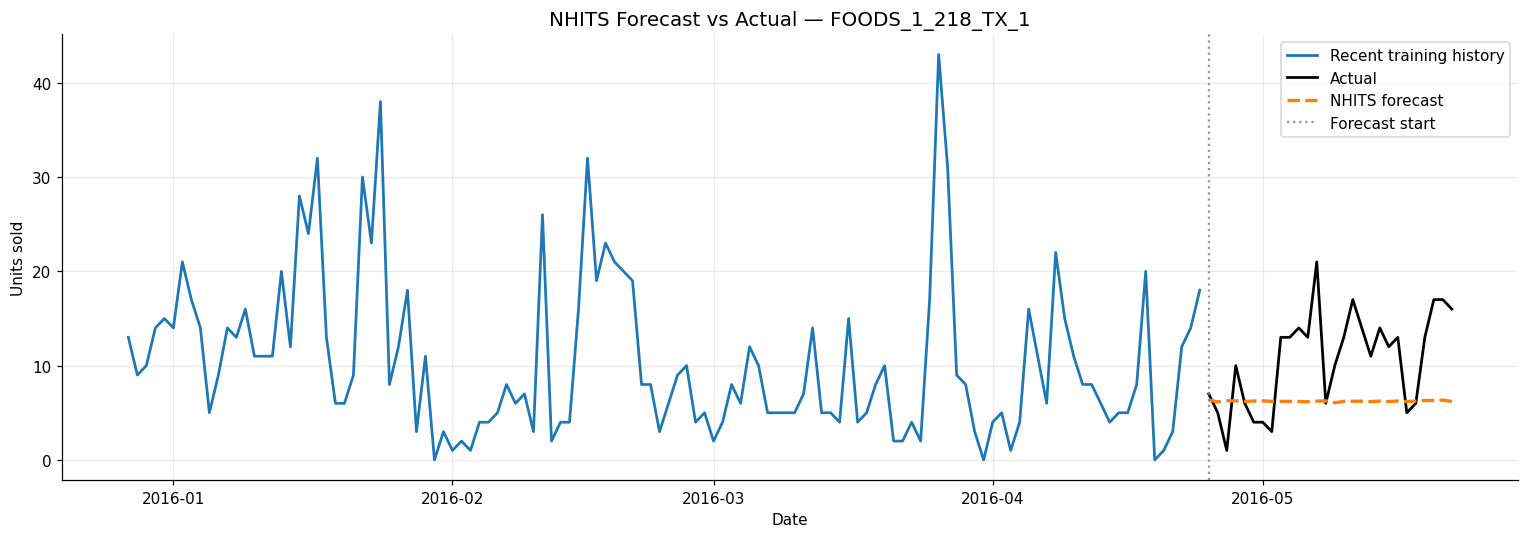

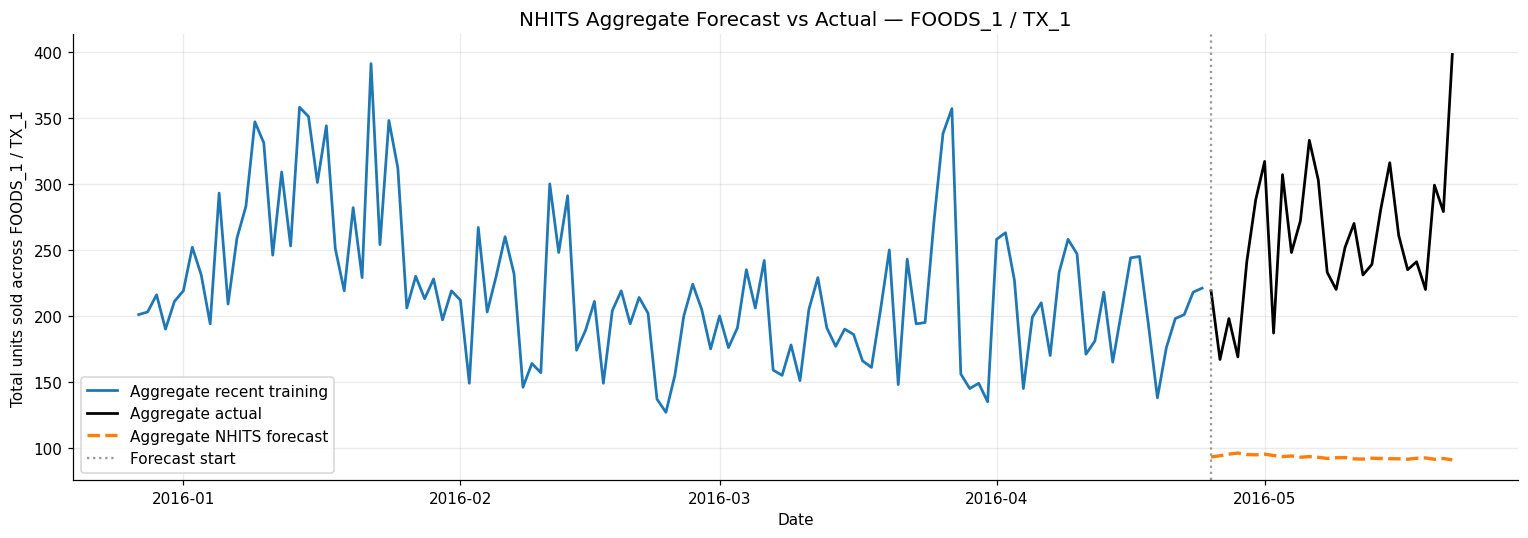

In [ ]:
sample_id = plot_single_series_forecast(
    train_df=train_main,
    actual_df=val,
    forecast_df=fcst_nhits_val,
    model_col="NHITS",
    title="NHITS Forecast vs Actual",
    file_name="nhits_forecast_single_series.png",
    boundary_date=val_start,
    sample=None,
    interval_cols=None,
    lookback=120,
)

plot_aggregate_forecast(
    train_df=train_main,
    actual_df=val,
    forecast_df=fcst_nhits_val,
    model_col="NHITS",
    title="NHITS Aggregate Forecast vs Actual — FOODS_1 / TX_1",
    file_name="nhits_forecast_aggregate.png",
    boundary_date=val_start,
    train_lookback=120,
)


## LSTM — Long Short-Term Memory

LSTM is included as a recurrent neural network benchmark. This type of model is commonly used for sequential data because it can learn dependencies across time.

Compared with NHITS, LSTM provides a more traditional deep learning approach to time series forecasting. Including both models allows us to compare two different neural modelling strategies under the same validation protocol.

In [ ]:
lstm_model = LSTM(
    h=h,
    input_size=2 * h,
    encoder_hidden_size=128,
    encoder_n_layers=2,
    max_steps=N_DL_STEPS,
    learning_rate=1e-3,
    batch_size=32,
    scaler_type="robust",
    random_seed=42,
    val_check_steps=50,
    early_stop_patience_steps=5,
)

nf_lstm = NeuralForecast(models=[lstm_model], freq="D")

print(f"Training LSTM on {train_nf['unique_id'].nunique()} series...")

nf_lstm.fit(df=train_nf, val_size=h)

print("LSTM training complete.")


INFO:lightning_fabric.utilities.seed:Seed set to 42
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.callbacks.model_summary:
  | Name            | Type          | Params | Mode 
----------------------------------------------------------
0 | loss            | MAE           | 0      | train
1 | padder          | ConstantPad1d | 0      | train
2 | scaler          | TemporalNorm  | 0      | train
3 | hist_encoder    | LSTM          | 199 K  | train
4 | context_adapter | Linear        | 36.1 K | train
5 | mlp_decoder     | MLP           | 2.4 K  | train
--------

Training LSTM on 216 series...


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (4 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

LSTM training complete.


### LSTM — Validation Forecast and Evaluation

In [ ]:
fcst_lstm_val = nf_lstm.predict().reset_index()
fcst_lstm_val = fcst_lstm_val[fcst_lstm_val["ds"].isin(val["ds"].unique())].copy()
fcst_lstm_val["LSTM"] = fcst_lstm_val["LSTM"].clip(lower=0)

mae_lstm, rmse_lstm, rmsse_lstm, lstm_by_series = evaluate_panel(
    train_main, val, fcst_lstm_val, "LSTM"
)

lstm_results = pd.DataFrame([{
    "Model": "LSTM",
    "MAE":   round(mae_lstm,   4),
    "RMSE":  round(rmse_lstm,  4),
    "RMSSE": round(rmsse_lstm, 4),
    "Phase": "Phase 3 – Deep Learning"
}])

print("LSTM Validation Results:")
display(lstm_results)


INFO: Trainer already configured with model summary callbacks: [<class 'pytorch_lightning.callbacks.model_summary.ModelSummary'>]. Skipping setting a default `ModelSummary` callback.
INFO:lightning.pytorch.utilities.rank_zero:Trainer already configured with model summary callbacks: [<class 'pytorch_lightning.callbacks.model_summary.ModelSummary'>]. Skipping setting a default `ModelSummary` callback.
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

LSTM Validation Results:


,Model,MAE,RMSE,RMSSE,Phase
0,LSTM,0.9671,1.5169,0.8234,Phase 3 – Deep Learning


#### Analytical interpretation — LSTM validation

LSTM obtained a validation **MAE of 0.9671**, **RMSE of 1.5169** and **RMSSE of 0.8234**. Although its MAE and RMSE are slightly lower than NHITS, its RMSSE is higher, so NHITS remains the better NeuralForecast model according to the main project metric.

This result is reasonable. LSTM is a recurrent architecture that can learn sequential dependencies, but it often requires careful tuning and enough signal in each time series. The selected M5 product-level series are relatively sparse and intermittent, which makes recurrent modelling more difficult. In contrast, tree-based models from Phase 2 can exploit engineered lag features directly and often perform very well on this type of tabular forecasting problem.

Therefore, LSTM is useful as a deep learning benchmark, but it does not provide evidence of improvement over either NHITS or the best previous-phase models.

### LSTM — Forecast Visualisation

The LSTM forecast is visualised using the same plotting utilities. This avoids misleading single-product graphs and also provides an aggregate view across the full selected M5 panel.

Using selected series for visualisation: FOODS_1_218_TX_1


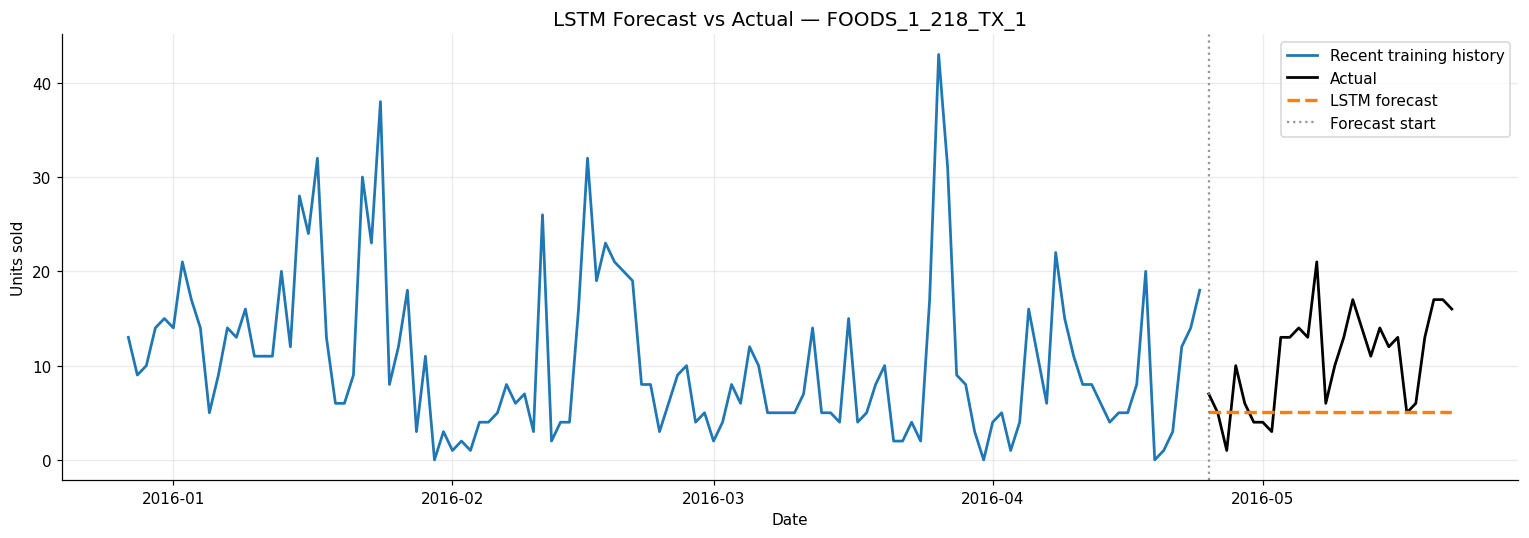

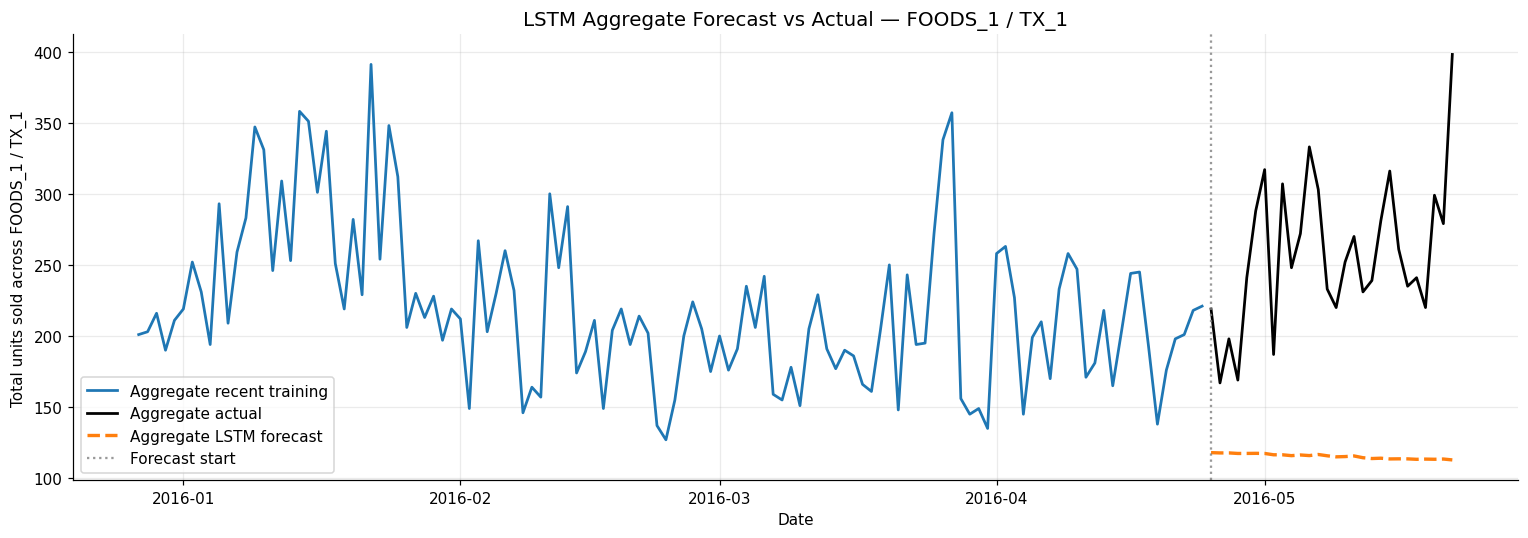

In [ ]:
plot_single_series_forecast(
    train_df=train_main,
    actual_df=val,
    forecast_df=fcst_lstm_val,
    model_col="LSTM",
    title="LSTM Forecast vs Actual",
    file_name="lstm_forecast_single_series.png",
    boundary_date=val_start,
    sample=sample_id,
    interval_cols=None,
    lookback=120,
)

plot_aggregate_forecast(
    train_df=train_main,
    actual_df=val,
    forecast_df=fcst_lstm_val,
    model_col="LSTM",
    title="LSTM Aggregate Forecast vs Actual — FOODS_1 / TX_1",
    file_name="lstm_forecast_aggregate.png",
    boundary_date=val_start,
    train_lookback=120,
)


### Deep Learning Models — Comparison

Both deep learning models are compared against each other and against the best results
from Phases 1 and 2.

Deep Learning Models — Validation Comparison:


,Model,MAE,RMSE,RMSSE,Phase
0,NHITS,0.9855,1.5329,0.8166,Phase 3 – Deep Learning
1,LSTM,0.9671,1.5169,0.8234,Phase 3 – Deep Learning


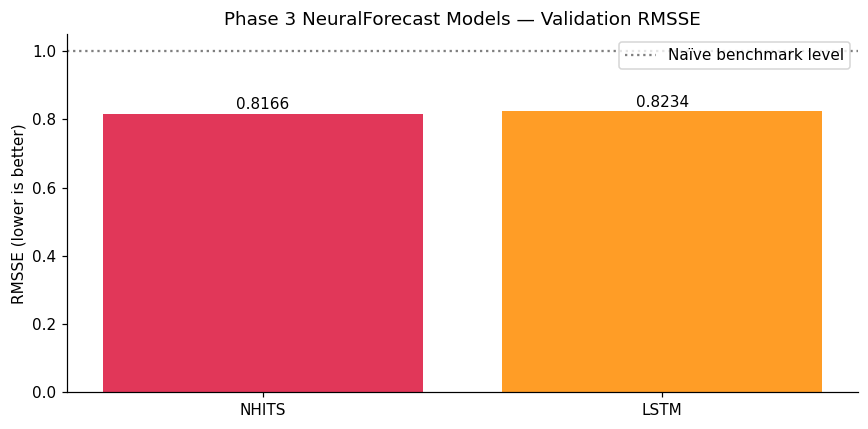

In [ ]:
dl_comparison = pd.concat([nhits_results, lstm_results], ignore_index=True)
dl_comparison = dl_comparison.sort_values("RMSSE").reset_index(drop=True)

print("Deep Learning Models — Validation Comparison:")
display(dl_comparison)

fig, ax = plt.subplots(figsize=(8, 4))
colors = ["crimson", "darkorange"][:len(dl_comparison)]
bars = ax.bar(dl_comparison["Model"], dl_comparison["RMSSE"], color=colors, alpha=0.85)

for bar, val_r in zip(bars, dl_comparison["RMSSE"]):
    ax.text(bar.get_x() + bar.get_width()/2, val_r + 0.005,
            f"{val_r:.4f}", ha="center", va="bottom", fontsize=10)

ax.axhline(1.0, color="black", linestyle=":", alpha=0.5, label="Naïve benchmark level")
ax.set_title("Phase 3 NeuralForecast Models — Validation RMSSE", fontsize=12)
ax.set_ylabel("RMSSE (lower is better)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{BASE_PATH}/dl_comparison.png", dpi=120, bbox_inches="tight")
plt.show()


#### Analytical interpretation — NeuralForecast comparison

The comparison between the two deep learning architectures shows that **NHITS is the best NeuralForecast model** in this phase, with **RMSSE = 0.8166**, compared with **0.8234** for LSTM. The difference is small, but NHITS is selected because RMSSE is the main evaluation metric of the project.

Both models remain below the naïve benchmark level of 1.0, meaning that they produce meaningful forecasts. Nevertheless, they do not outperform the strongest statistical and machine learning models from Phases 1 and 2. This is an important result: deep learning is not automatically superior, especially when the dataset contains sparse product-level demand and when previous phases already used strong lag-based feature engineering.

The main value of this section is methodological: it shows how global deep learning forecasting models can be trained and evaluated under the same 28-day validation protocol as the previous phases.

## Probabilistic Forecasts from the Best NeuralForecast Model

After evaluating NHITS and LSTM, the best NeuralForecast model is selected based on validation RMSSE.

NeuralForecast can support conformal prediction intervals, but the current notebook environment raised errors when using `level=[80, 95]` without explicitly configured `prediction_intervals`. To keep the workflow stable and reproducible in Colab, this section creates **empirical residual-based prediction intervals** from the validation residuals of the best deep learning model.

These intervals are useful for visualising uncertainty, but they should be interpreted as a simple empirical approximation rather than fully calibrated probabilistic forecasts. The final notebook also includes Chronos, TimeGPT and AutoGluon, which provide more direct probabilistic forecasting outputs.

In [ ]:
best_dl_row = dl_comparison.sort_values("RMSSE").iloc[0]
best_dl_name = best_dl_row["Model"]
best_dl_rmsse = best_dl_row["RMSSE"]

print(f"Best deep learning model: {best_dl_name} (RMSSE = {best_dl_rmsse:.4f})")

if best_dl_name == "NHITS":
    best_dl_forecast_df = fcst_nhits_val.copy()
    best_dl_forecast_col = "NHITS"
elif best_dl_name == "LSTM":
    best_dl_forecast_df = fcst_lstm_val.copy()
    best_dl_forecast_col = "LSTM"
else:
    raise ValueError(f"Unexpected best deep learning model: {best_dl_name}")

cv_best_dl_intervals = add_validation_intervals_from_residuals(
    actual_df=val,
    forecast_df=best_dl_forecast_df,
    model_col=best_dl_forecast_col,
    output_col="Forecast",
)

if "sample_id" not in globals() or sample_id not in cv_best_dl_intervals["unique_id"].unique():
    sample_id, _ = choose_plot_series(
        train_df=train_main,
        actual_df=val,
        forecast_df=cv_best_dl_intervals.rename(columns={"Forecast": best_dl_name}),
        model_col=best_dl_name,
    )

cv_sample = cv_best_dl_intervals[cv_best_dl_intervals["unique_id"] == sample_id].copy()

print("Best DL interval dataframe preview:")
display(cv_best_dl_intervals.head())
print("Selected sample for probabilistic DL plot:", sample_id)


Best deep learning model: NHITS (RMSSE = 0.8166)
Best DL interval dataframe preview:


,unique_id,ds,y,Forecast,lo_80,hi_80,lo_95,hi_95
0,FOODS_1_001_TX_1,2016-04-25,0.0,0.000398,0.0,2.580281,0.0,6.003528
1,FOODS_1_001_TX_1,2016-04-26,0.0,0.000000,0.0,2.579884,0.0,6.003130
2,FOODS_1_001_TX_1,2016-04-27,1.0,0.000209,0.0,2.580093,0.0,6.003340
3,FOODS_1_001_TX_1,2016-04-28,0.0,0.000761,0.0,2.580645,0.0,6.003891
4,FOODS_1_001_TX_1,2016-04-29,1.0,0.000052,0.0,2.579935,0.0,6.003182


Selected sample for probabilistic DL plot: FOODS_1_218_TX_1


Using selected series for visualisation: FOODS_1_218_TX_1


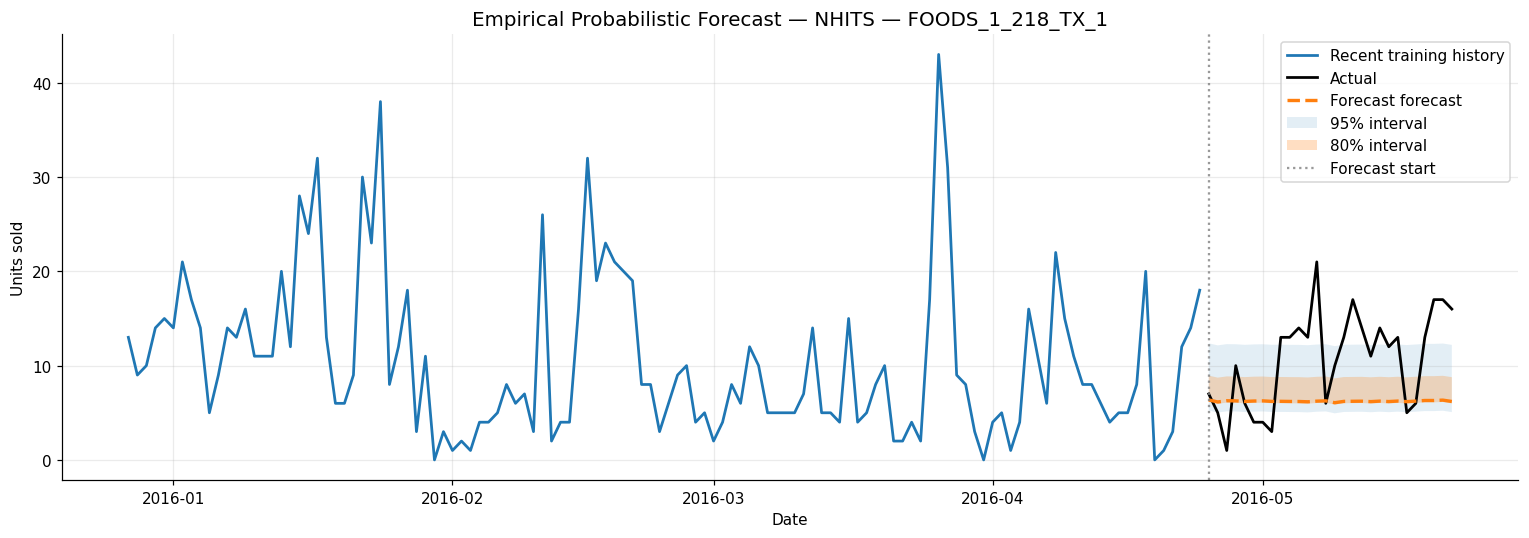

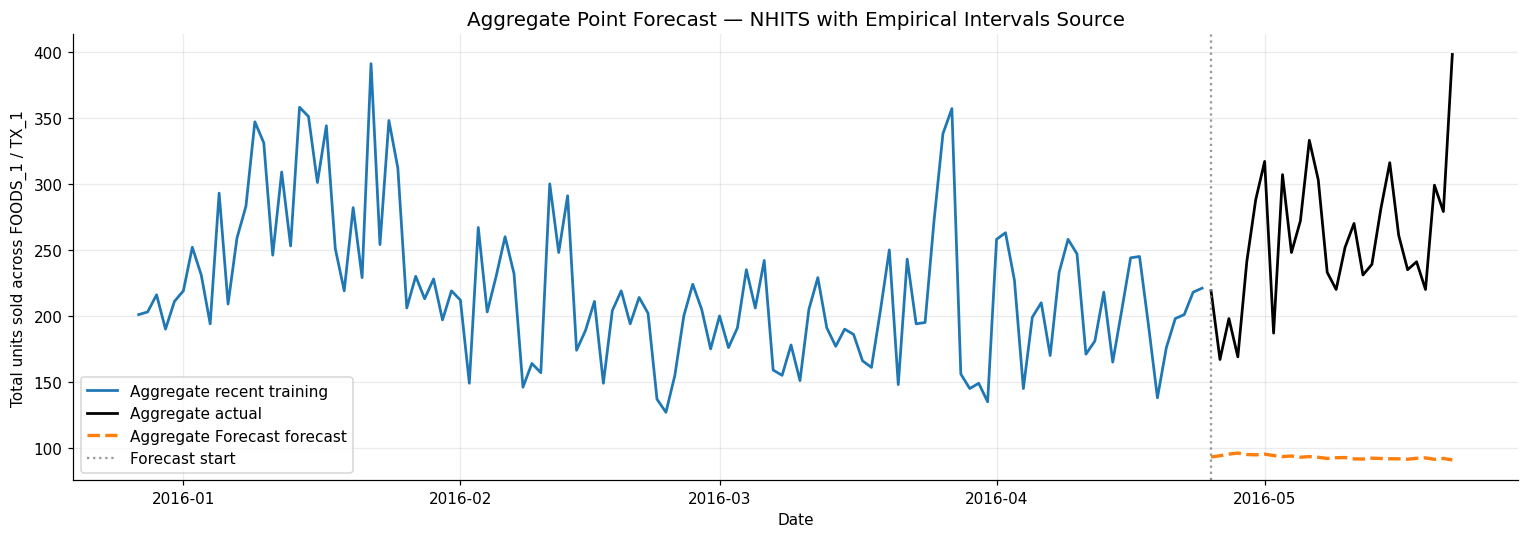

In [ ]:
plot_single_series_forecast(
    train_df=train_main,
    actual_df=val,
    forecast_df=cv_best_dl_intervals,
    model_col="Forecast",
    title=f"Empirical Probabilistic Forecast — {best_dl_name}",
    file_name="probabilistic_dl_empirical_single_series.png",
    boundary_date=val_start,
    sample=sample_id,
    interval_cols=("lo_80", "hi_80", "lo_95", "hi_95"),
    lookback=120,
)

plot_aggregate_forecast(
    train_df=train_main,
    actual_df=val,
    forecast_df=cv_best_dl_intervals,
    model_col="Forecast",
    title=f"Aggregate Point Forecast — {best_dl_name} with Empirical Intervals Source",
    file_name="probabilistic_dl_empirical_aggregate.png",
    boundary_date=val_start,
    train_lookback=120,
)


## Automatic Deep Learning Models — AutoNHITS and AutoLSTM

This section adds automatic deep learning as a robustness check against the manually configured NeuralForecast models. AutoNHITS and AutoLSTM search over compact hyperparameter spaces while keeping the same validation horizon and RMSSE evaluation protocol.

The aim is to test whether automatic tuning improves the neural models. In this run, AutoDL added methodological value, but it did not outperform the manually configured NHITS/LSTM models.

In [ ]:
train_nf = train_main[["unique_id", "ds", "y"]].copy()

def autonhits_config(trial):
    """Compact AutoNHITS search space for a polished Colab run."""
    config = AutoNHITS.get_default_config(h=h, backend="optuna")(trial)
    config["max_steps"] = N_AUTO_DL_STEPS
    config["input_size"] = trial.suggest_categorical("autonhits_input_size", [2 * h, 3 * h, 4 * h])
    config["batch_size"] = trial.suggest_categorical("autonhits_batch_size", [32, 64])
    config["val_check_steps"] = max(25, N_AUTO_DL_STEPS // 2)
    config["random_seed"] = 42
    return config

autonhits_model = AutoNHITS(
    h=h,
    loss=MAE(),
    config=autonhits_config,
    backend="optuna",
    num_samples=N_AUTO_DL_TRIALS,
    cpus=1,
)

nf_autonhits = NeuralForecast(models=[autonhits_model], freq="D")

print(f"Training AutoNHITS on {train_nf['unique_id'].nunique()} series...")
print(f"AutoNHITS trials: {N_AUTO_DL_TRIALS}; max steps per trial: {N_AUTO_DL_STEPS}")
nf_autonhits.fit(df=train_nf, val_size=h)
print("AutoNHITS training complete.")

[I 2026-06-11 22:33:35,076] A new study created in memory with name: no-name-0ae5ca8c-530a-4b17-b325-b6d2b5d3668c
INFO:lightning_fabric.utilities.seed:Seed set to 42
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.callbacks.model_summary:
  | Name         | Type          | Params | Mode 
-------------------------------------------------------
0 | loss         | MAE           | 0      | train
1 | padder_train | ConstantPad1d | 0      | train
2 | scaler       | TemporalNorm  | 0      | train
3 | blocks       | ModuleList    | 2.6 M  | train
------------------

Training AutoNHITS on 216 series...
AutoNHITS trials: 3; max steps per trial: 150


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (13 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

INFO: `Trainer.fit` stopped: `max_steps=150` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_steps=150` reached.


AutoNHITS training complete.


### AutoNHITS — Validation Forecast

The selected AutoNHITS configuration is used to forecast the 28-day validation period. Negative forecasts are clipped to zero because sales quantities cannot be negative.

In [ ]:
fcst_autonhits_val = nf_autonhits.predict().reset_index()
fcst_autonhits_val = fcst_autonhits_val[fcst_autonhits_val["ds"].isin(val["ds"].unique())].copy()

expected_forecast_col_name = "AutoNHITS"

if expected_forecast_col_name in fcst_autonhits_val.columns:
    autonhits_cols = [expected_forecast_col_name]
else:
    autonhits_cols = [
        c for c in fcst_autonhits_val.columns
        if expected_forecast_col_name in c and "lo" not in c.lower() and "hi" not in c.lower()
    ]

if len(autonhits_cols) == 0:
    raise ValueError(f"AutoNHITS forecast column not found. Columns: {fcst_autonhits_val.columns.tolist()}")

fcst_autonhits_val = fcst_autonhits_val.rename(columns={autonhits_cols[0]: "AutoNHITS"})
fcst_autonhits_val["AutoNHITS"] = fcst_autonhits_val["AutoNHITS"].clip(lower=0)
print("AutoNHITS validation forecasts shape:", fcst_autonhits_val.shape)
display(fcst_autonhits_val.head())

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

AutoNHITS validation forecasts shape: (6048, 3)


,unique_id,ds,AutoNHITS
0,FOODS_1_001_TX_1,2016-04-25,0.013087
1,FOODS_1_001_TX_1,2016-04-26,0.002115
2,FOODS_1_001_TX_1,2016-04-27,0.015201
3,FOODS_1_001_TX_1,2016-04-28,0.000000
4,FOODS_1_001_TX_1,2016-04-29,0.017309


### AutoNHITS — Evaluation

In [ ]:
mae_autonhits, rmse_autonhits, rmsse_autonhits, autonhits_by_series = evaluate_panel(
    train_main, val, fcst_autonhits_val, "AutoNHITS"
)

autonhits_results = pd.DataFrame([{
    "Model": "AutoNHITS",
    "Approach": "Auto Deep Learning",
    "Exogenous": "No",
    "MAE": round(mae_autonhits, 4),
    "RMSE": round(rmse_autonhits, 4),
    "RMSSE": round(rmsse_autonhits, 4),
    "Phase": "Phase 3 – Auto Deep Learning",
    "Evaluation_Panel": "Full panel (216 series)",
}])

print("AutoNHITS Validation Results:")
display(autonhits_results)

AutoNHITS Validation Results:


,Model,Approach,Exogenous,MAE,RMSE,RMSSE,Phase,Evaluation_Panel
0,AutoNHITS,Auto Deep Learning,No,1.0169,1.5535,0.8205,Phase 3 – Auto Deep Learning,Full panel (216 series)


#### Analytical interpretation — AutoNHITS validation

AutoNHITS achieved a validation **RMSSE of 0.8205** on the full 216-series FOODS_1 / TX_1 panel.

This result is below 1.0, which means that AutoNHITS improves over the naïve scale reference used by RMSSE. Therefore, the model is able to capture relevant demand patterns in the panel. However, its performance is still weaker than the best models from Phases 1 and 2 and also weaker than TimeGPT in Phase 3.

The result is still valuable because AutoNHITS reduces dependence on a manually selected NHITS configuration. It provides a more systematic deep learning benchmark and confirms that automatic tuning can produce a valid model under the same 28-day validation protocol. Nevertheless, in this execution, automatic deep learning was not the most competitive modelling family.


### AutoNHITS — Forecast Visualisation

Selected representative series for this plot: FOODS_1_218_TX_1
Top candidate series for visualisation:


,unique_id,recent_mean,actual_mean,recent_nonzero,actual_nonzero,forecast_mean,forecast_nonzero,score
214,FOODS_1_218_TX_1,10.500000,10.642858,0.975000,1.000000,6.122570,1.0,49.823543
10,FOODS_1_012_TX_1,6.141667,9.107142,0.983333,1.000000,5.819721,1.0,42.212250
196,FOODS_1_200_TX_1,7.683333,5.928571,0.975000,1.000000,4.787777,1.0,39.743738
16,FOODS_1_018_TX_1,6.241667,7.107143,0.958333,1.000000,4.202762,1.0,39.077074
126,FOODS_1_129_TX_1,7.491667,7.000000,0.933333,0.964286,0.885645,1.0,38.028591


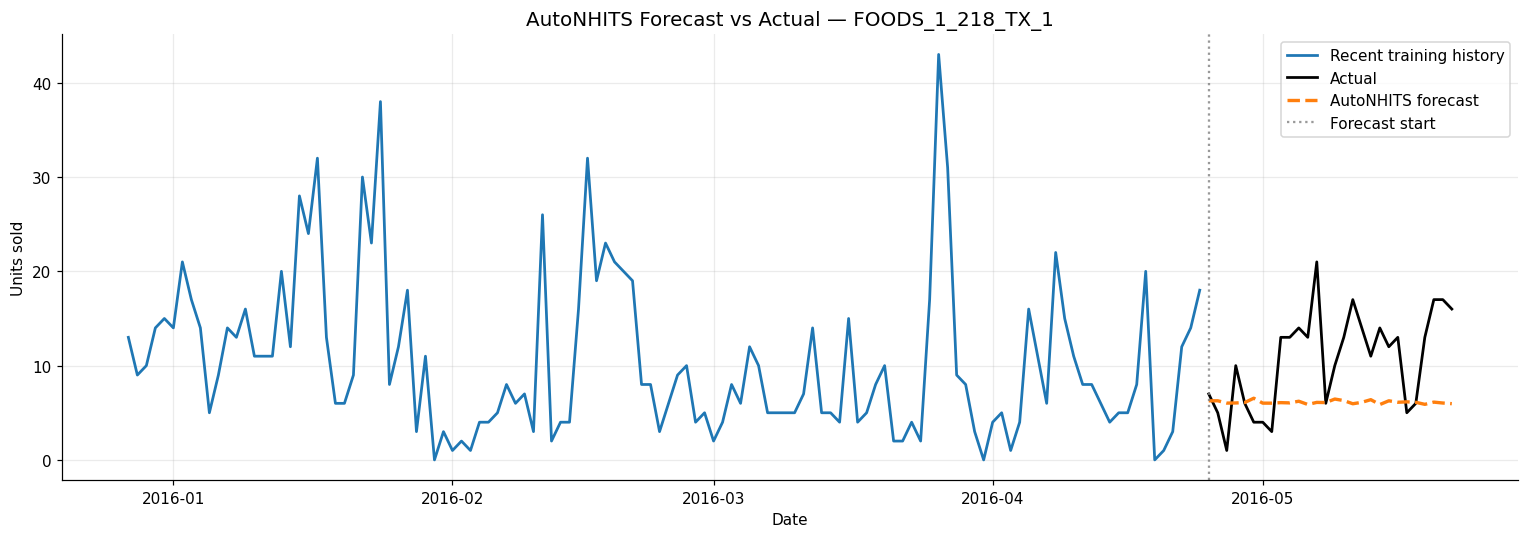

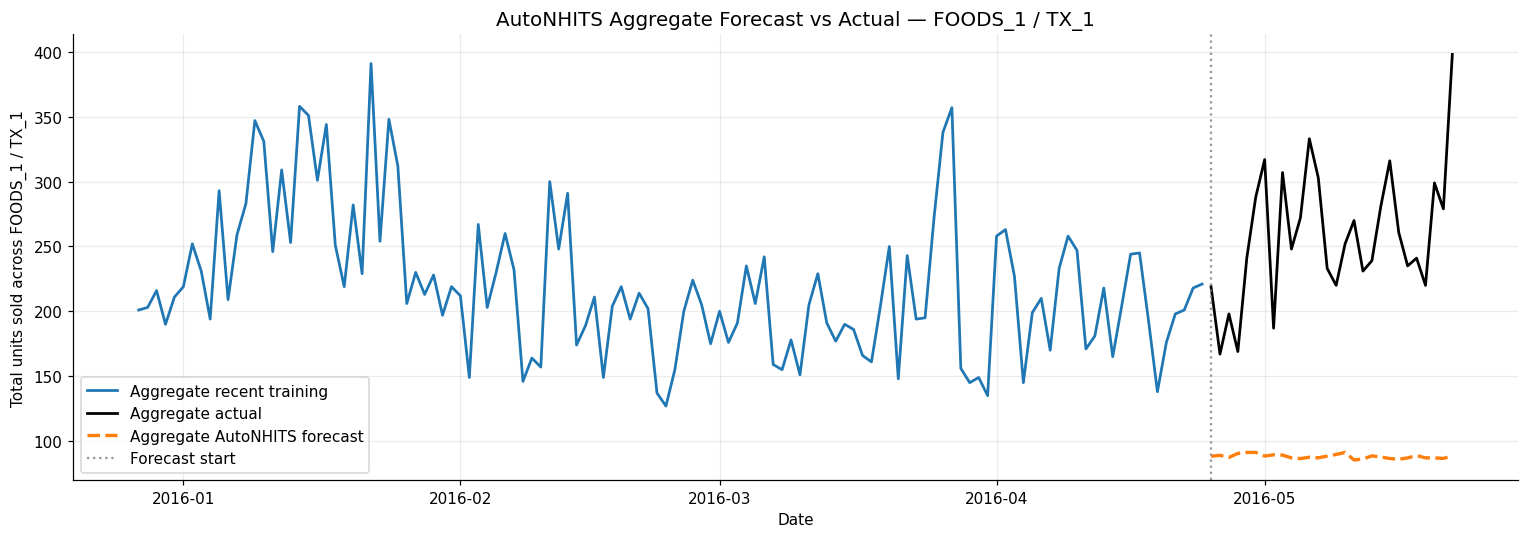

In [ ]:
sample_id = plot_single_series_forecast(train_main, val, fcst_autonhits_val, "AutoNHITS", "AutoNHITS Forecast vs Actual", "autonhits_forecast_single_series.png", val_start, sample=None, interval_cols=None, lookback=120)
plot_aggregate_forecast(train_main, val, fcst_autonhits_val, "AutoNHITS", "AutoNHITS Aggregate Forecast vs Actual — FOODS_1 / TX_1", "autonhits_forecast_aggregate.png", val_start, train_lookback=120)


## AutoLSTM — Automatic Long Short-Term Memory

AutoLSTM is the automatic version of LSTM. It keeps the recurrent modelling structure, but searches over a small set of hyperparameters such as input size, hidden size, number of recurrent layers and batch size.

This model is included as a recurrent AutoDL benchmark. Since the M5 product-level series are sparse and intermittent, AutoLSTM may be harder to tune than AutoNHITS, but it remains useful for comparing two different automatic deep learning families.

In [ ]:
def autolstm_config(trial):
    """Compact AutoLSTM search space for a polished Colab run."""
    config = AutoLSTM.get_default_config(h=h, backend="optuna")(trial)
    config["max_steps"] = N_AUTO_DL_STEPS
    config["input_size"] = trial.suggest_categorical("autolstm_input_size", [2 * h, 3 * h])
    config["encoder_hidden_size"] = trial.suggest_categorical("autolstm_encoder_hidden_size", [64, 128])
    config["encoder_n_layers"] = trial.suggest_categorical("autolstm_encoder_n_layers", [1, 2])
    config["batch_size"] = trial.suggest_categorical("autolstm_batch_size", [32, 64])
    config["val_check_steps"] = max(25, N_AUTO_DL_STEPS // 2)
    config["random_seed"] = 42
    return config

autolstm_model = AutoLSTM(
    h=h,
    loss=MAE(),
    config=autolstm_config,
    backend="optuna",
    num_samples=N_AUTO_DL_TRIALS,
    cpus=1,
)

nf_autolstm = NeuralForecast(models=[autolstm_model], freq="D")
print(f"Training AutoLSTM on {train_nf['unique_id'].nunique()} series...")
print(f"AutoLSTM trials: {N_AUTO_DL_TRIALS}; max steps per trial: {N_AUTO_DL_STEPS}")
nf_autolstm.fit(df=train_nf, val_size=h)
print("AutoLSTM training complete.")

[I 2026-06-11 22:33:49,813] A new study created in memory with name: no-name-0d328647-1084-46ec-bd1d-d4ac9f3f876a
INFO:lightning_fabric.utilities.seed:Seed set to 42
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.callbacks.model_summary:
  | Name            | Type          | Params | Mode 
----------------------------------------------------------
0 | loss            | MAE           | 0      | train
1 | padder          | ConstantPad1d | 0      | train
2 | scaler          | TemporalNorm  | 0      | train
3 | hist_encoder    | LSTM          | 67.1 K | train


Training AutoLSTM on 216 series...
AutoLSTM trials: 3; max steps per trial: 150


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (13 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

INFO: `Trainer.fit` stopped: `max_steps=150` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_steps=150` reached.


AutoLSTM training complete.


### AutoLSTM — Validation Forecast and Evaluation

In [ ]:
fcst_autolstm_val = nf_autolstm.predict().reset_index()
fcst_autolstm_val = fcst_autolstm_val[fcst_autolstm_val["ds"].isin(val["ds"].unique())].copy()

autolstm_cols = [
    c for c in fcst_autolstm_val.columns
    if "AutoLSTM" in c and "lo" not in c.lower() and "hi" not in c.lower()
]

if len(autolstm_cols) == 0:
    raise ValueError(f"AutoLSTM forecast column not found. Columns: {fcst_autolstm_val.columns.tolist()}")

fcst_autolstm_val = fcst_autolstm_val.rename(columns={autolstm_cols[0]: "AutoLSTM"})
fcst_autolstm_val["AutoLSTM"] = fcst_autolstm_val["AutoLSTM"].clip(lower=0)

mae_autolstm, rmse_autolstm, rmsse_autolstm, autolstm_by_series = evaluate_panel(
    train_main, val, fcst_autolstm_val, "AutoLSTM"
)

autolstm_results = pd.DataFrame([{
    "Model": "AutoLSTM",
    "Approach": "Auto Deep Learning",
    "Exogenous": "No",
    "MAE": round(mae_autolstm, 4),
    "RMSE": round(rmse_autolstm, 4),
    "RMSSE": round(rmsse_autolstm, 4),
    "Phase": "Phase 3 – Auto Deep Learning",
    "Evaluation_Panel": "Full panel (216 series)",
}])

print("AutoLSTM Validation Results:")
display(autolstm_results)

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

AutoLSTM Validation Results:


,Model,Approach,Exogenous,MAE,RMSE,RMSSE,Phase,Evaluation_Panel
0,AutoLSTM,Auto Deep Learning,No,0.9856,1.5464,0.8314,Phase 3 – Auto Deep Learning,Full panel (216 series)


#### Analytical interpretation — AutoLSTM validation

AutoLSTM achieved a validation **RMSSE of 0.8314** on the full 216-series panel.

In this execution, AutoLSTM was weaker than AutoNHITS across the three reported validation metrics: MAE, RMSE and RMSSE. Since RMSSE is the main evaluation metric of this project, AutoLSTM is ranked below AutoNHITS in the AutoDL comparison.

The result suggests that the recurrent LSTM architecture was less suitable than AutoNHITS for this sparse retail-demand panel. This is consistent with the nature of SKU-level sales data, where many series are intermittent and where recurrent architectures can struggle under a limited tuning budget.


### AutoLSTM — Forecast Visualisation

Using selected series for visualisation: FOODS_1_218_TX_1


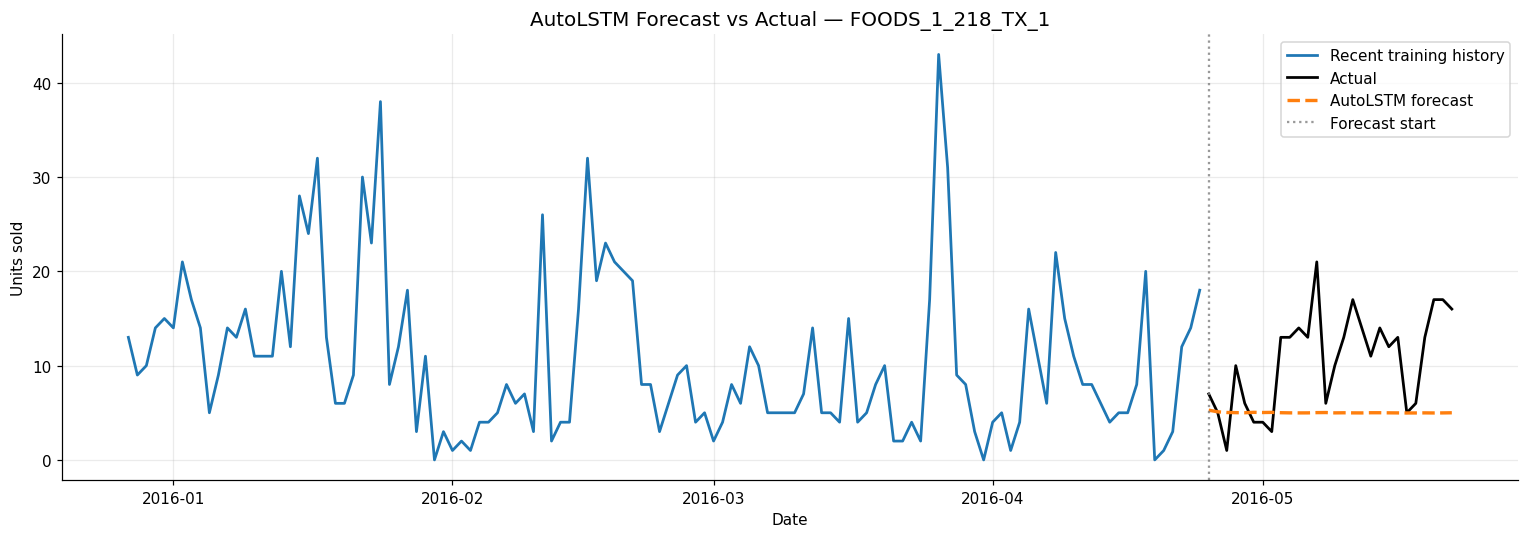

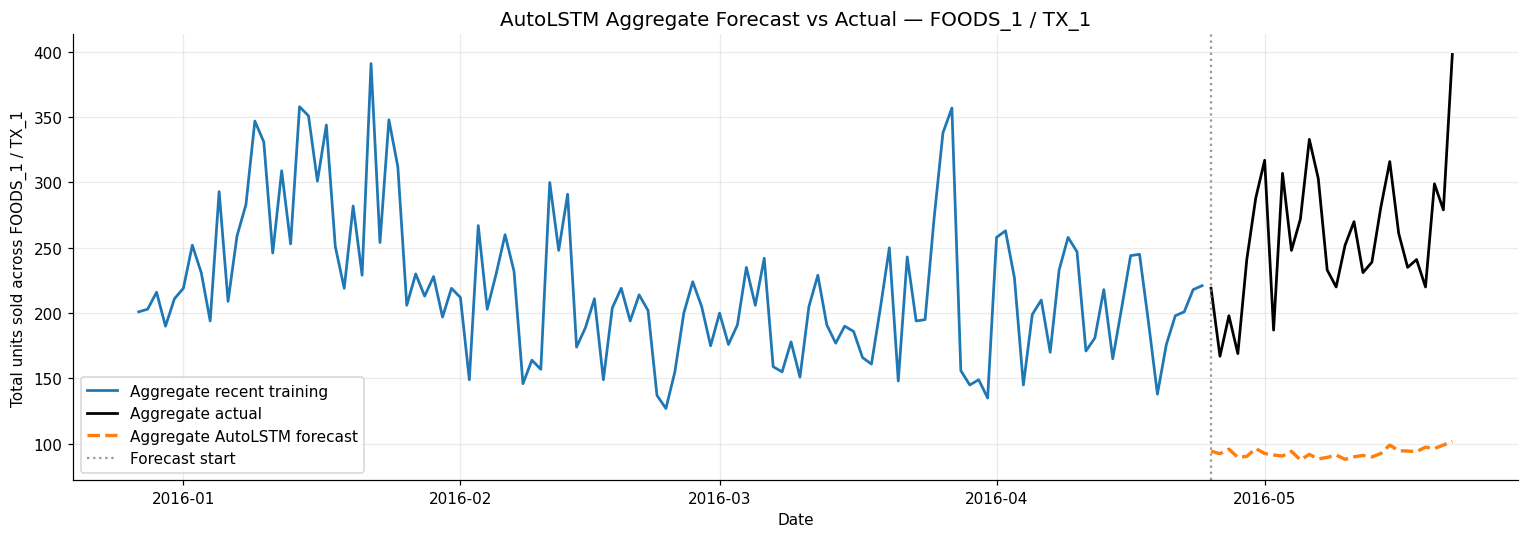

In [ ]:
plot_single_series_forecast(train_main, val, fcst_autolstm_val, "AutoLSTM", "AutoLSTM Forecast vs Actual", "autolstm_forecast_single_series.png", val_start, sample=sample_id, interval_cols=None, lookback=120)
plot_aggregate_forecast(train_main, val, fcst_autolstm_val, "AutoLSTM", "AutoLSTM Aggregate Forecast vs Actual — FOODS_1 / TX_1", "autolstm_forecast_aggregate.png", val_start, train_lookback=120)


### Auto Deep Learning Models — Comparison

Auto Deep Learning Models — Validation Comparison:


,Model,Approach,Exogenous,MAE,RMSE,RMSSE,Phase,Evaluation_Panel
0,AutoNHITS,Auto Deep Learning,No,1.0169,1.5535,0.8205,Phase 3 – Auto Deep Learning,Full panel (216 series)
1,AutoLSTM,Auto Deep Learning,No,0.9856,1.5464,0.8314,Phase 3 – Auto Deep Learning,Full panel (216 series)


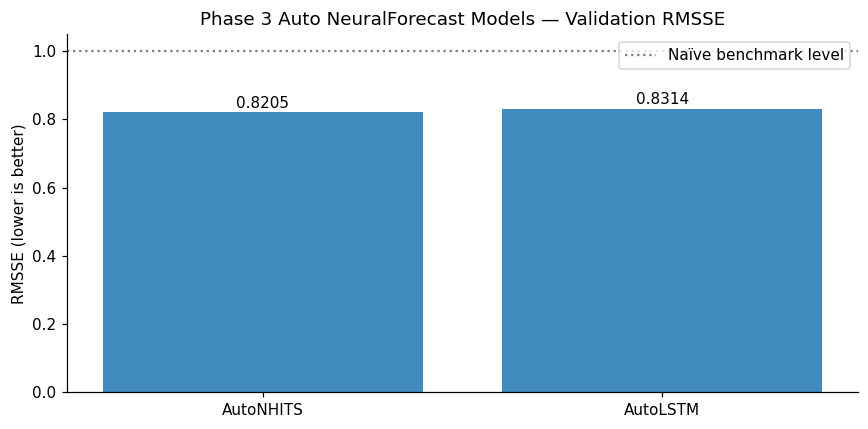

In [ ]:
auto_dl_comparison = pd.concat([autonhits_results, autolstm_results], ignore_index=True).sort_values("RMSSE").reset_index(drop=True)
print("Auto Deep Learning Models — Validation Comparison:")
display(auto_dl_comparison)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(auto_dl_comparison["Model"], auto_dl_comparison["RMSSE"], alpha=0.85)
for bar, val_r in zip(bars, auto_dl_comparison["RMSSE"]):
    ax.text(bar.get_x() + bar.get_width() / 2, val_r + 0.005, f"{val_r:.4f}", ha="center", va="bottom", fontsize=10)
ax.axhline(1.0, color="black", linestyle=":", alpha=0.5, label="Naïve benchmark level")
ax.set_title("Phase 3 Auto NeuralForecast Models — Validation RMSSE")
ax.set_ylabel("RMSSE (lower is better)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{BASE_PATH}/auto_dl_comparison.png", dpi=120, bbox_inches="tight")
plt.show()


#### Analytical interpretation — Auto NeuralForecast comparison

The AutoDL comparison shows that **AutoNHITS** was the best automatically tuned NeuralForecast model:

- **AutoNHITS:** RMSSE = **0.8205**
- **AutoLSTM:** RMSSE = **0.8314**

Both models achieved RMSSE values below 1.0, meaning that both improved over the naïve scale reference. However, AutoNHITS is clearly preferred in this execution because it produced lower MAE, RMSE and RMSSE than AutoLSTM.

Compared with the strongest models from Phases 1 and 2, the AutoDL models were not competitive enough in this execution. Their performance is valid, but not leading. The main conclusion is that automatic tuning improved the structure and robustness of the deep learning experiment, but it did not make deep learning outperform the best statistical, machine learning or foundation-model alternatives for this FOODS_1 / TX_1 panel.


## Probabilistic Forecasts from the Best Auto NeuralForecast Model

After evaluating AutoNHITS and AutoLSTM, the best automatic NeuralForecast model is selected based on validation RMSSE.

NeuralForecast can support probabilistic methods, but configuring native intervals for every Auto model can make the notebook less stable in Colab. Therefore, this section uses empirical residual-based intervals for the best AutoDL model. These intervals are useful for visualising uncertainty, but should be interpreted as an approximation rather than fully calibrated probabilistic forecasts.

The final 28-day forecast later in the notebook can also use TimeGPT, which provides native prediction intervals through the Nixtla API.

Best auto deep learning model: AutoNHITS (RMSSE = 0.8205)
Empirical probabilistic validation forecast:


,unique_id,ds,y,Forecast,lo_80,hi_80,lo_95,hi_95
0,FOODS_1_001_TX_1,2016-04-25,0.0,0.013087,0.0,2.785091,0.0,6.815170
1,FOODS_1_001_TX_1,2016-04-26,0.0,0.002115,0.0,2.774119,0.0,6.804198
2,FOODS_1_001_TX_1,2016-04-27,1.0,0.015201,0.0,2.787205,0.0,6.817284
3,FOODS_1_001_TX_1,2016-04-28,0.0,0.000000,0.0,2.772005,0.0,6.802083
4,FOODS_1_001_TX_1,2016-04-29,1.0,0.017309,0.0,2.789314,0.0,6.819393


Using selected series for visualisation: FOODS_1_218_TX_1


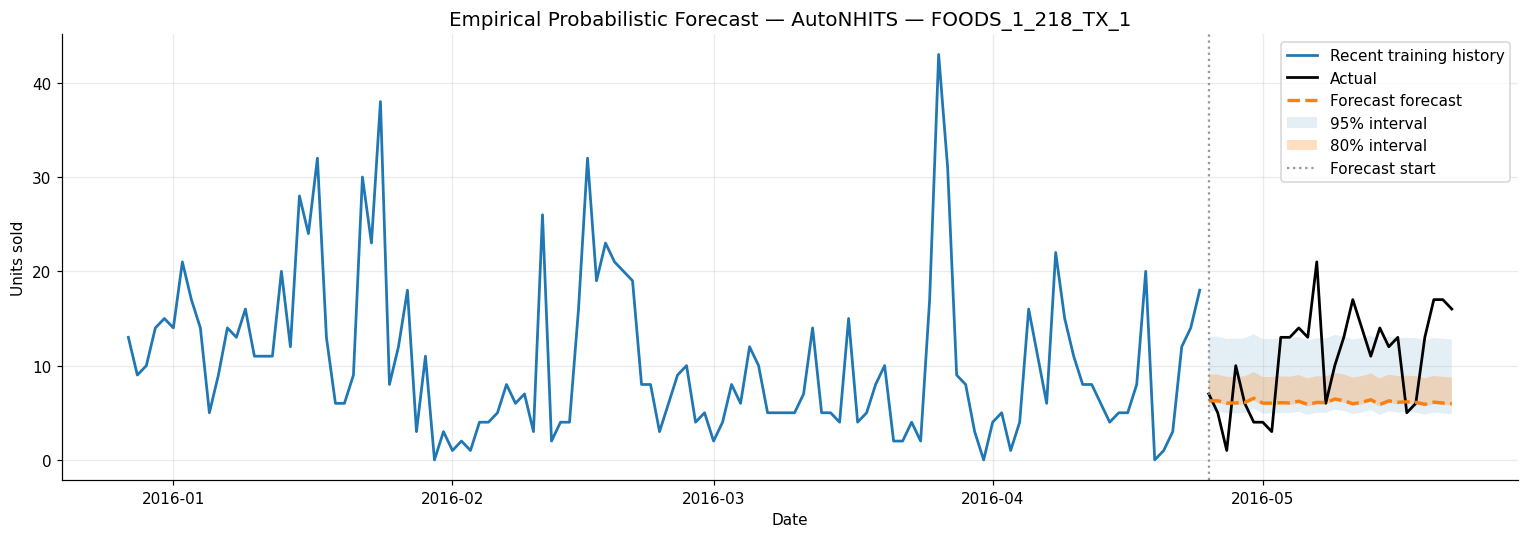

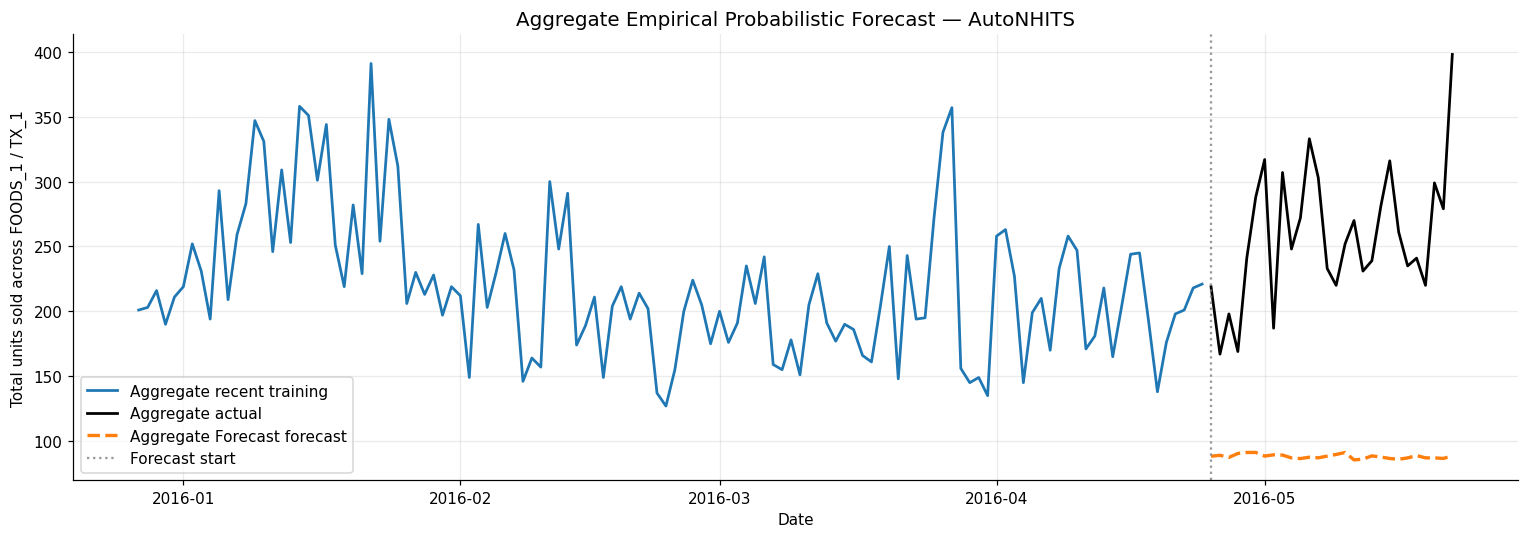

In [ ]:
best_auto_dl_row = auto_dl_comparison.sort_values("RMSSE").iloc[0]
best_auto_dl_name = best_auto_dl_row["Model"]
print(f"Best auto deep learning model: {best_auto_dl_name} (RMSSE = {best_auto_dl_row['RMSSE']:.4f})")

if best_auto_dl_name == "AutoNHITS":
    best_fcst_val = fcst_autonhits_val.copy()
    best_model_col = "AutoNHITS"
elif best_auto_dl_name == "AutoLSTM":
    best_fcst_val = fcst_autolstm_val.copy()
    best_model_col = "AutoLSTM"
else:
    raise ValueError(f"Unexpected best auto deep learning model: {best_auto_dl_name}")

prob_dl_val = add_validation_intervals_from_residuals(val, best_fcst_val, best_model_col, output_col="Forecast")
print("Empirical probabilistic validation forecast:")
display(prob_dl_val.head())

plot_id, _ = choose_plot_series(train_main, val, prob_dl_val, "Forecast")
plot_single_series_forecast(train_main, val, prob_dl_val, "Forecast", f"Empirical Probabilistic Forecast — {best_auto_dl_name}", "best_auto_dl_probabilistic_single_series.png", val_start, sample=plot_id, interval_cols=("lo_80", "hi_80", "lo_95", "hi_95"), lookback=120)
plot_aggregate_forecast(train_main, val, prob_dl_val, "Forecast", f"Aggregate Empirical Probabilistic Forecast — {best_auto_dl_name}", "best_auto_dl_probabilistic_aggregate.png", val_start, train_lookback=120)


## Manual vs Automatic Deep Learning Comparison

This comparison directly evaluates whether automatic hyperparameter tuning improved the neural models. The manually configured NHITS/LSTM models and the automatic AutoNHITS/AutoLSTM models are all evaluated on the same full 216-series validation panel.

The result is important for the final discussion: automatic tuning improved the breadth of the experiment, but the manually configured neural models remained slightly stronger in RMSSE.

Manual vs Automatic NeuralForecast comparison:


,Model,Tuning,MAE,RMSE,RMSSE,Evaluation_Panel
0,NHITS,Manual configuration,0.9855,1.5329,0.8166,Full panel (216 series)
1,AutoNHITS,Automatic tuning,1.0169,1.5535,0.8205,Full panel (216 series)
2,LSTM,Manual configuration,0.9671,1.5169,0.8234,Full panel (216 series)
3,AutoLSTM,Automatic tuning,0.9856,1.5464,0.8314,Full panel (216 series)


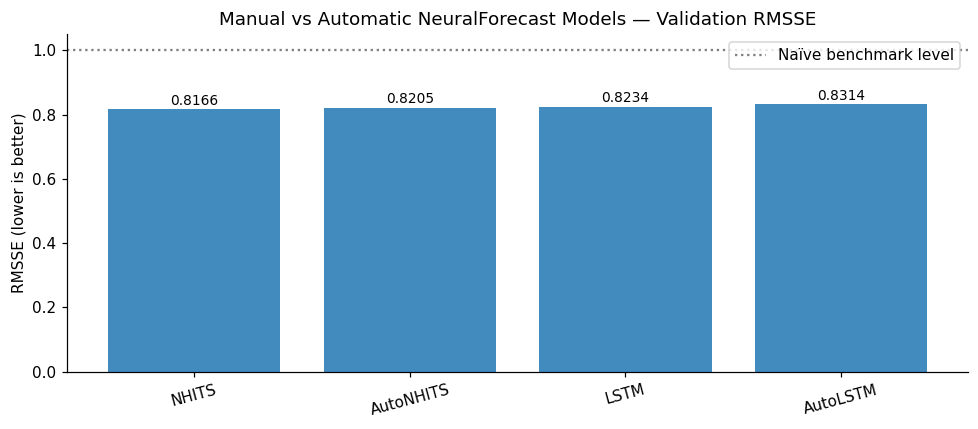

In [ ]:
manual_dl_comparison = dl_comparison.copy()
manual_dl_comparison["Tuning"] = "Manual configuration"

if "Evaluation_Panel" not in manual_dl_comparison.columns:
    manual_dl_comparison["Evaluation_Panel"] = "Full panel (216 series)"
else:
    manual_dl_comparison["Evaluation_Panel"] = manual_dl_comparison["Evaluation_Panel"].fillna("Full panel (216 series)")

auto_dl_comparison_display = auto_dl_comparison.copy()
auto_dl_comparison_display["Tuning"] = "Automatic tuning"

if "Evaluation_Panel" not in auto_dl_comparison_display.columns:
    auto_dl_comparison_display["Evaluation_Panel"] = "Full panel (216 series)"
else:
    auto_dl_comparison_display["Evaluation_Panel"] = auto_dl_comparison_display["Evaluation_Panel"].fillna("Full panel (216 series)")

neural_tuning_comparison = pd.concat([
    manual_dl_comparison,
    auto_dl_comparison_display
], ignore_index=True)

neural_tuning_comparison = neural_tuning_comparison.sort_values("RMSSE").reset_index(drop=True)

print("Manual vs Automatic NeuralForecast comparison:")
display(neural_tuning_comparison[["Model", "Tuning", "MAE", "RMSE", "RMSSE", "Evaluation_Panel"]])

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(neural_tuning_comparison["Model"], neural_tuning_comparison["RMSSE"], alpha=0.85)
for bar, value in zip(bars, neural_tuning_comparison["RMSSE"]):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.005, f"{value:.4f}", ha="center", va="bottom", fontsize=9)
ax.axhline(1.0, color="black", linestyle=":", alpha=0.5, label="Naïve benchmark level")
ax.set_title("Manual vs Automatic NeuralForecast Models — Validation RMSSE")
ax.set_ylabel("RMSSE (lower is better)")
ax.legend()
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(f"{BASE_PATH}/manual_vs_auto_neuralforecast_comparison.png", dpi=120, bbox_inches="tight")
plt.show()


#### Analytical interpretation — Manual vs AutoDL

The automatic models were useful as an additional robustness check, but they did not improve over the manual neural configurations. NHITS remained the strongest NeuralForecast model, followed by AutoNHITS, LSTM and AutoLSTM.

This result supports a balanced conclusion: automatic tuning is valuable because it makes the modelling process more systematic, but it does not guarantee better performance. In this sparse retail-demand panel, the manually configured NHITS architecture remained slightly more competitive than AutoNHITS.

## Foundation Model — Chronos (Amazon)

### What is Chronos?

**Chronos** is an open-source foundation model for time series forecasting developed by
Amazon Research (Ansari et al., 2024).

Chronos represents a fundamentally different approach to forecasting:

- It adapts a **pre-trained language model** (T5 architecture) to time series data.
- The time series values are **tokenised** — scaled and quantised into a discrete vocabulary,
  analogous to words in a language model.
- The model was pre-trained on a large and diverse collection of real-world time series.
- At inference time, it operates in **zero-shot** mode: it produces forecasts without any
  training on the target dataset.

| Aspect | Chronos approach |
|---|---|
| Architecture | T5 encoder-decoder |
| Input | Tokenised time series (quantised values) |
| Output | Probabilistic — samples from a learned distribution |
| Training data | Large public time series corpus |
| Inference | Zero-shot — no fine-tuning on the target data |

> This section can be skipped by setting `RUN_CHRONOS = False` at the top of the notebook.

### Chronos — Zero-Shot Forecasting

Chronos is applied in **zero-shot** mode: the model has never seen the M5 data and produces
forecasts purely from patterns learned during pre-training on diverse external datasets.

The `chronos-t5-small` variant is used to balance accuracy and inference speed in Colab.

**Important implementation notes:**
- `torch_dtype` is set dynamically: `bfloat16` on GPU (faster, less memory), `float32` on CPU
  (compatible with all hardware configurations).
- After inference, tensors are moved to CPU with `.cpu()` before converting to NumPy,
  which is required when running on GPU to avoid a CUDA conversion error.

In [ ]:
if RUN_CHRONOS:
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"Using device: {device}")

    torch_dtype = torch.bfloat16 if torch.cuda.is_available() else torch.float32

    pipeline = ChronosPipeline.from_pretrained(
        "amazon/chronos-t5-small",
        device_map=device,
        torch_dtype=torch_dtype,
    )
    print("Chronos model loaded successfully.")
else:
    print("RUN_CHRONOS = False — skipping Chronos section.")


Using device: cuda


config.json: 0.00B [00:00, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/185M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/142 [00:00<?, ?B/s]

Chronos model loaded successfully.


### Chronos — Generate Forecasts for All Series

Chronos is applied independently to each series.
For each product, the model receives the full training history and produces a 28-day probabilistic forecast.

The point forecast (median) and prediction intervals (80% and 95%) are extracted from the sample distribution.

In [ ]:
if RUN_CHRONOS:
    import time
    chronos_records = []
    series_ids = train_main["unique_id"].unique()
    n_series   = len(series_ids)

    print(f"Running Chronos zero-shot forecasting on {n_series} series...")
    t0 = time.time()

    for i, uid in enumerate(series_ids):
        ts      = train_main[train_main["unique_id"] == uid]["y"].values.astype(float)
        context = torch.tensor(ts, dtype=torch.float32).unsqueeze(0)

        with torch.no_grad():
            forecast_samples = pipeline.predict(
                context,
                prediction_length=h,
                num_samples=100,
            )

        if isinstance(forecast_samples, torch.Tensor):
            samples = forecast_samples[0].detach().cpu().numpy()
        else:
            samples = np.asarray(forecast_samples[0])

        median_fc = np.median(samples, axis=0)
        lo80_fc   = np.percentile(samples, 10,  axis=0)
        hi80_fc   = np.percentile(samples, 90,  axis=0)
        lo95_fc   = np.percentile(samples,  2.5, axis=0)
        hi95_fc   = np.percentile(samples, 97.5, axis=0)

        val_dates = val[val["unique_id"] == uid]["ds"].values
        if len(val_dates) == 0:
            continue

        for step in range(min(h, len(val_dates))):
            chronos_records.append({
                "unique_id":     uid,
                "ds":            val_dates[step],
                "Chronos":       max(0.0, float(median_fc[step])),
                "Chronos-lo-80": max(0.0, float(lo80_fc[step])),
                "Chronos-hi-80": max(0.0, float(hi80_fc[step])),
                "Chronos-lo-95": max(0.0, float(lo95_fc[step])),
                "Chronos-hi-95": max(0.0, float(hi95_fc[step])),
            })

        if (i + 1) % 50 == 0:
            print(f"  {i+1}/{n_series} series — {time.time()-t0:.1f}s elapsed")

    fcst_chronos_val = pd.DataFrame(chronos_records)
    fcst_chronos_val["ds"] = pd.to_datetime(fcst_chronos_val["ds"])
    print(f"\nChronos complete. Total time: {time.time()-t0:.1f}s")
    print(f"Forecast shape: {fcst_chronos_val.shape}")
else:
    fcst_chronos_val = pd.DataFrame()
    print("RUN_CHRONOS = False — Chronos forecasts not generated.")


Running Chronos zero-shot forecasting on 216 series...
  50/216 series — 40.6s elapsed
  100/216 series — 66.4s elapsed
  150/216 series — 93.0s elapsed
  200/216 series — 120.3s elapsed

Chronos complete. Total time: 131.3s
Forecast shape: (6048, 7)


### Chronos — Evaluation

In [ ]:
if RUN_CHRONOS and not fcst_chronos_val.empty:
    mae_ch, rmse_ch, rmsse_ch, chronos_by_series = evaluate_panel(
        train_main, val, fcst_chronos_val, "Chronos"
    )
    chronos_results = pd.DataFrame([{
        "Model": "Chronos (zero-shot)",
        "MAE":   round(mae_ch,   4),
        "RMSE":  round(rmse_ch,  4),
        "RMSSE": round(rmsse_ch, 4),
        "Phase": "Phase 3 – Foundation Model"
    }])
    print("Chronos Zero-Shot Validation Results:")
    display(chronos_results)
else:
    chronos_results = pd.DataFrame()
    print("Chronos results not available (RUN_CHRONOS = False).")


Chronos Zero-Shot Validation Results:


,Model,MAE,RMSE,RMSSE,Phase
0,Chronos (zero-shot),0.9918,1.5272,0.8158,Phase 3 – Foundation Model


#### Analytical interpretation — Chronos zero-shot validation

Chronos achieved **MAE ≈ 0.9918**, **RMSE ≈ 1.5272** and **RMSSE ≈ 0.8158** on the validation set in this run. This is still a strong Phase 3 result because Chronos was used in **zero-shot mode**, meaning that the model was not trained or fine-tuned on the M5 data.

However, after activating TimeGPT, Chronos is no longer the best Phase 3 model. TimeGPT achieved a lower RMSSE, so Chronos should be interpreted as a strong open-source foundation-model benchmark rather than the final selected Phase 3 model.

A key strength of Chronos is that it naturally produces probabilistic forecasts through sampled future paths. This directly supports the project requirement to visualise uncertainty intervals. Its main weakness is interpretability: unlike ARIMAX or tree-based models, it is difficult to explain which historical patterns or external factors drive each forecast. In addition, Chronos is univariate in this implementation, so it does not directly use prices, SNAP indicators or calendar/event variables.

### Chronos — Probabilistic Forecast Visualisation

One of the key advantages of Chronos is its **native probabilistic output**.
The prediction intervals directly reflect the model's uncertainty about future values,
without requiring any additional calibration step.

Using selected series for visualisation: FOODS_1_218_TX_1


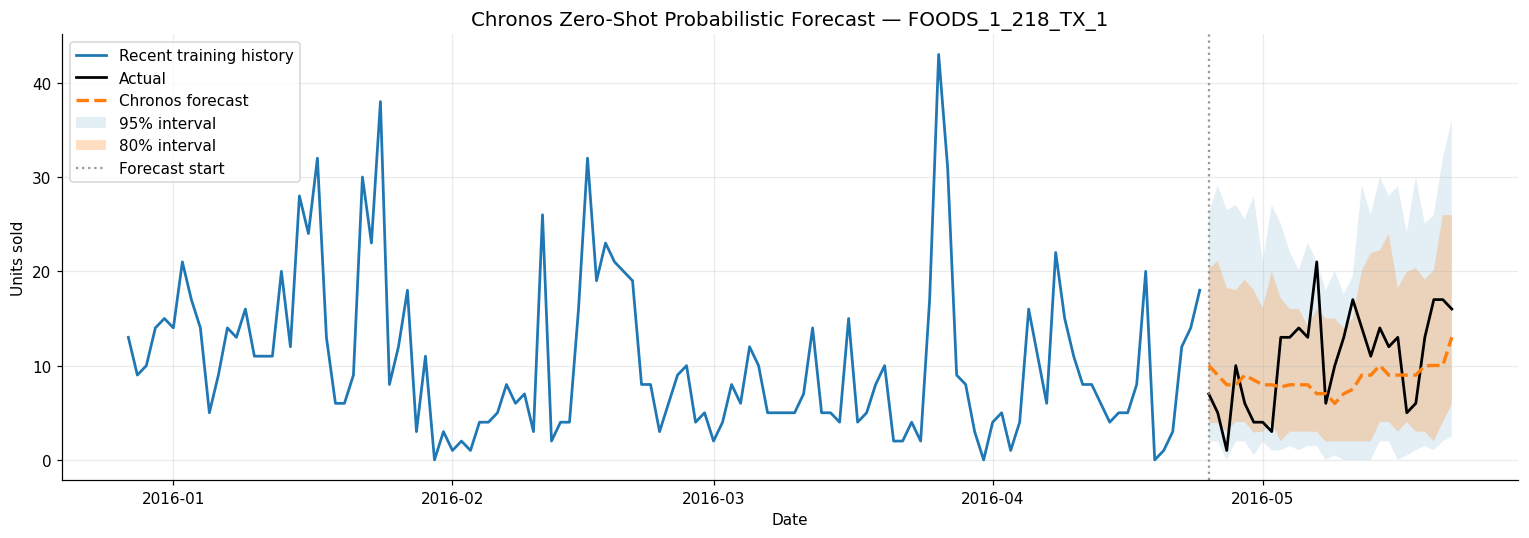

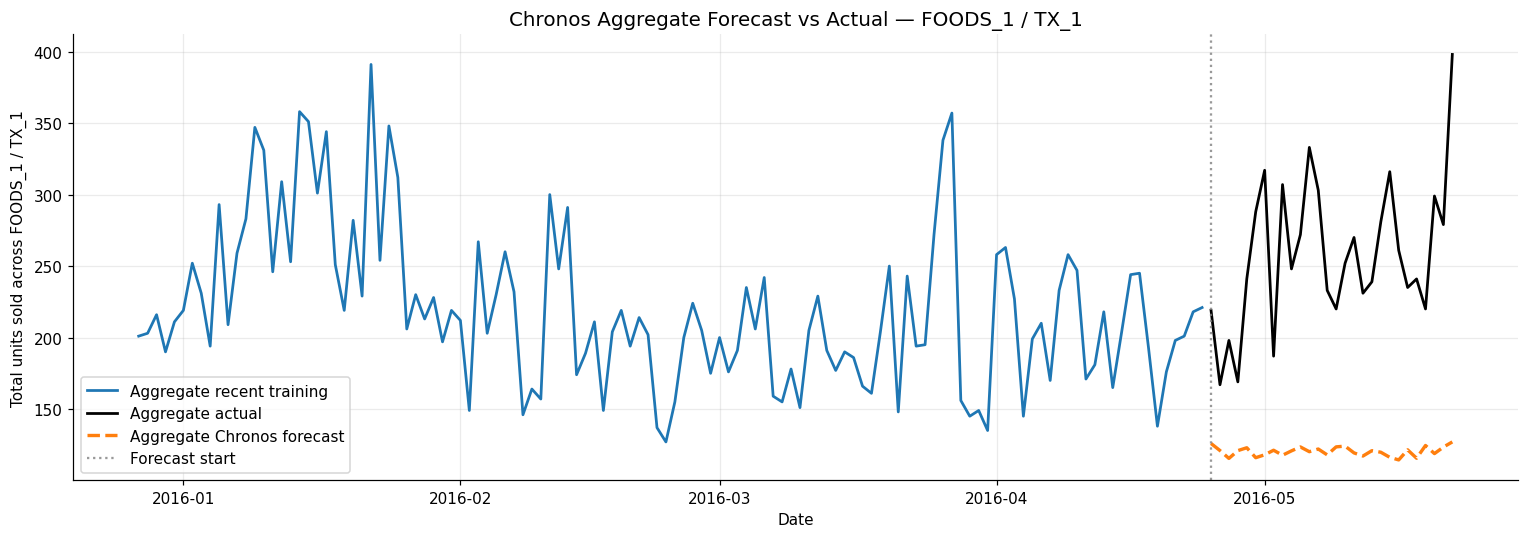

In [ ]:
if RUN_CHRONOS and not fcst_chronos_val.empty:
    plot_single_series_forecast(
        train_df=train_main,
        actual_df=val,
        forecast_df=fcst_chronos_val,
        model_col="Chronos",
        title="Chronos Zero-Shot Probabilistic Forecast",
        file_name="chronos_forecast_single_series.png",
        boundary_date=val_start,
        sample=sample_id,
        interval_cols=("Chronos-lo-80", "Chronos-hi-80", "Chronos-lo-95", "Chronos-hi-95"),
        lookback=120,
    )

    plot_aggregate_forecast(
        train_df=train_main,
        actual_df=val,
        forecast_df=fcst_chronos_val,
        model_col="Chronos",
        title="Chronos Aggregate Forecast vs Actual — FOODS_1 / TX_1",
        file_name="chronos_forecast_aggregate.png",
        boundary_date=val_start,
        train_lookback=120,
    )
else:
    print("Chronos visualisation skipped (RUN_CHRONOS = False or no forecasts).")


## Foundation Model — TimeGPT (Nixtla API)

### Why include TimeGPT?

TimeGPT is included as an additional foundation forecasting model because it was covered in the project requirements as a pre-trained / foundation time series approach. Unlike Chronos, which can be run locally in Colab, TimeGPT is accessed through the Nixtla API and therefore requires an API key.

This section is controlled by the flag `RUN_TIMEGPT`. In this final execution, `RUN_TIMEGPT = True`, which means that both the univariate and exogenous TimeGPT versions were evaluated through the Nixtla API.

Two versions are prepared:

1. **TimeGPT Univariate** — uses only the historical sales series.
2. **TimeGPT Exogenous** — uses sales plus known future regressors such as price, SNAP and calendar features.

This allows the project to compare a foundation model against statistical, machine learning, deep learning and AutoML approaches.

Because the project forecasts a 28-day horizon, this version uses `timegpt-1-long-horizon` instead of the standard `timegpt-1`. This addresses the Nixtla warning that the selected horizon may exceed the recommended model horizon. The warning is not a fatal error, but using the long-horizon variant is more appropriate and more defensible for the final notebook.


In [ ]:
def get_timegpt_client():
    """Create a Nixtla client securely without exposing the API key in the notebook.

    Priority order:
    1. Environment variable NIXTLA_API_KEY
    2. Google Colab Secrets entry named NIXTLA_API_KEY
    3. Manual hidden input with getpass()

    This allows an authorised Nixtla/TimeGPT key to be used at runtime without
    writing it directly inside the notebook file.
    """
    import os
    from getpass import getpass
    from nixtla import NixtlaClient

    api_key = os.environ.get("NIXTLA_API_KEY")

    if not api_key:
        try:
            from google.colab import userdata
            api_key = userdata.get("NIXTLA_API_KEY")
        except Exception:
            api_key = None

    if not api_key:
        api_key = getpass("Enter your Nixtla API key: ")

    if not api_key:
        raise ValueError(
            "No Nixtla API key was provided. Add it to Colab Secrets as "
            "'NIXTLA_API_KEY' or enter it when prompted."
        )

    os.environ["NIXTLA_API_KEY"] = api_key

    client = NixtlaClient(api_key=api_key)
    client.validate_api_key()
    return client

def standardize_timegpt_forecast(fcst, model_name="TimeGPT"):
    """
    Convert Nixtla/TimeGPT output into the common format used in this notebook.

    Output columns:
    - unique_id
    - ds
    - <model_name>   point forecast
    - lo_80, hi_80   80% prediction interval
    - lo_95, hi_95   95% prediction interval

    The exact interval column names can vary by Nixtla client version, so the
    function searches defensively for several possible naming conventions.
    """
    fcst = fcst.copy()
    fcst["ds"] = pd.to_datetime(fcst["ds"])

    possible_point_cols = [model_name, "TimeGPT", "timegpt", "mean", "yhat", "forecast"]
    point_col = next((c for c in possible_point_cols if c in fcst.columns), None)

    if point_col is None:
        numeric_cols = [
            c for c in fcst.select_dtypes(include=[np.number]).columns
            if str(c).lower() not in ["y"]
        ]
        if not numeric_cols:
            raise ValueError(
                "Could not identify the TimeGPT point forecast column. "
                f"Available columns: {fcst.columns.tolist()}"
            )
        point_col = numeric_cols[0]

    out = fcst[["unique_id", "ds", point_col]].rename(columns={point_col: model_name})
    out[model_name] = pd.to_numeric(out[model_name], errors="coerce").clip(lower=0)

    def find_interval_column(patterns):
        for col in fcst.columns:
            col_lower = str(col).lower().replace("_", "-")
            if any(pattern in col_lower for pattern in patterns):
                return col
        return None

    interval_patterns = {
        "lo_80": ["lo-80", "lower-80", "q10", "p10", "0.1"],
        "hi_80": ["hi-80", "upper-80", "q90", "p90", "0.9"],
        "lo_95": ["lo-95", "lower-95", "q2.5", "q025", "p2.5", "p025", "0.025"],
        "hi_95": ["hi-95", "upper-95", "q97.5", "q975", "p97.5", "p975", "0.975"],
    }

    for new_col, patterns in interval_patterns.items():
        found_col = find_interval_column(patterns)
        if found_col is not None:
            out[new_col] = pd.to_numeric(fcst[found_col], errors="coerce").clip(lower=0)
        else:
            out[new_col] = np.nan

    return out


### TimeGPT Univariate — Validation Forecast

This version uses only the historical sales series in the format expected by the Nixtla API: `unique_id`, `ds` and `y`. It forecasts the same 28-day validation horizon used by all previous models.

In [ ]:
if RUN_TIMEGPT:
    nixtla_client = get_timegpt_client()

    timegpt_train_uni = train_main[["unique_id", "ds", "y"]].copy()

    raw_timegpt_uni_val = nixtla_client.forecast(
        df=timegpt_train_uni,
        h=h,
        freq="D",
        id_col="unique_id",
        time_col="ds",
        target_col="y",
        level=[80, 95],
        model=TIMEGPT_MODEL,
    )

    fcst_timegpt_uni_val = standardize_timegpt_forecast(
        raw_timegpt_uni_val,
        model_name="TimeGPT_Univariate"
    )

    mae_tg_uni, rmse_tg_uni, rmsse_tg_uni, tg_uni_by_series = evaluate_panel(
        train_main, val, fcst_timegpt_uni_val, "TimeGPT_Univariate"
    )

    timegpt_uni_results = pd.DataFrame([{
        "Model": "TimeGPT_Univariate",
        "Approach": "Foundation Model / API",
        "Exogenous": "No",
        "MAE": mae_tg_uni,
        "RMSE": rmse_tg_uni,
        "RMSSE": rmsse_tg_uni,
        "Phase": "Phase 3 – Foundation Model"
    }])

    display(timegpt_uni_results)
else:
    timegpt_uni_results = pd.DataFrame()
    print("RUN_TIMEGPT = False — skipping TimeGPT univariate forecast.")


,Model,Approach,Exogenous,MAE,RMSE,RMSSE,Phase
0,TimeGPT_Univariate,Foundation Model / API,No,1.019463,1.40562,0.746757,Phase 3 – Foundation Model


### TimeGPT Exogenous — Validation Forecast

The exogenous TimeGPT version includes known future regressors. In this project, these are the same features used in earlier phases: price-related variables, SNAP indicators and calendar-based variables.

For the validation horizon, the future values of these regressors are passed through `X_df`. This directly addresses the requirement of testing whether exogenous information improves forecasting compared with the univariate version.

In [ ]:
if RUN_TIMEGPT:
    timegpt_train_exog = train_main[["unique_id", "ds", "y"]].merge(
        X_ml, on=["unique_id", "ds"], how="left"
    )

    timegpt_val_exog = X_ml[X_ml["ds"].isin(val["ds"].unique())][["unique_id", "ds"] + exog_cols].copy()

    raw_timegpt_exog_val = nixtla_client.forecast(
        df=timegpt_train_exog,
        X_df=timegpt_val_exog,
        h=h,
        freq="D",
        id_col="unique_id",
        time_col="ds",
        target_col="y",
        level=[80, 95],
        model=TIMEGPT_MODEL,
    )

    fcst_timegpt_exog_val = standardize_timegpt_forecast(
        raw_timegpt_exog_val,
        model_name="TimeGPT_Exogenous"
    )

    mae_tg_exog, rmse_tg_exog, rmsse_tg_exog, tg_exog_by_series = evaluate_panel(
        train_main, val, fcst_timegpt_exog_val, "TimeGPT_Exogenous"
    )

    timegpt_exog_results = pd.DataFrame([{
        "Model": "TimeGPT_Exogenous",
        "Approach": "Foundation Model / API",
        "Exogenous": "Yes",
        "MAE": mae_tg_exog,
        "RMSE": rmse_tg_exog,
        "RMSSE": rmsse_tg_exog,
        "Phase": "Phase 3 – Foundation Model"
    }])

    display(timegpt_exog_results)
else:
    timegpt_exog_results = pd.DataFrame()
    print("RUN_TIMEGPT = False — skipping TimeGPT exogenous forecast.")

,Model,Approach,Exogenous,MAE,RMSE,RMSSE,Phase
0,TimeGPT_Exogenous,Foundation Model / API,Yes,1.036141,1.408044,0.747061,Phase 3 – Foundation Model


### TimeGPT — Univariate vs Exogenous Comparison

This table compares both TimeGPT versions using the same 28-day validation set and the same metrics as all previous models. In this run, **RUN_TIMEGPT = True**, so both TimeGPT versions were executed successfully through the Nixtla API.

The comparison is especially important because it directly tests whether adding known future regressors: calendar features, SNAP indicators and price-related variables, improves TimeGPT's forecasts compared with the univariate version.

In [ ]:
if RUN_TIMEGPT:
    timegpt_results = pd.concat([timegpt_uni_results, timegpt_exog_results], ignore_index=True)
    timegpt_results = timegpt_results.sort_values("RMSSE").reset_index(drop=True)
    display(timegpt_results)
else:
    timegpt_results = pd.DataFrame(columns=["Model", "Approach", "Exogenous", "MAE", "RMSE", "RMSSE", "Phase"])
    display(timegpt_results)

,Model,Approach,Exogenous,MAE,RMSE,RMSSE,Phase
0,TimeGPT_Univariate,Foundation Model / API,No,1.019463,1.405620,0.746757,Phase 3 – Foundation Model
1,TimeGPT_Exogenous,Foundation Model / API,Yes,1.036141,1.408044,0.747061,Phase 3 – Foundation Model


#### Analytical interpretation — TimeGPT validation

TimeGPT was successfully executed in both univariate and exogenous versions using the `timegpt-1-long-horizon` model. The **univariate TimeGPT** model achieved **MAE = 1.019463**, **RMSE = 1.405620** and **RMSSE = 0.746757**. The **exogenous TimeGPT** model achieved **MAE = 1.036141**, **RMSE = 1.408044** and **RMSSE = 0.747061**.

Both TimeGPT variants achieved RMSSE values well below 1.0, meaning that they improved substantially over the naïve benchmark. More importantly, TimeGPT became the strongest Phase 3 family of models, outperforming Chronos, NHITS, LSTM and AutoGluon on the validation window.

The univariate version was marginally better according to RMSSE (**0.746757 vs 0.747061**). The difference is extremely small, but because RMSSE is the main project metric, **TimeGPT_Univariate** is selected as the better TimeGPT variant. In this run, the exogenous variables did not improve MAE, RMSE or RMSSE for TimeGPT, suggesting that the historical demand signal was already highly informative for this FOODS_1 / TX_1 subset and 28-day horizon.

The notebook was updated to use `timegpt-1-long-horizon`, which is more appropriate for the 28-day horizon and avoids treating the previous TimeGPT horizon warning as a modelling error. The TimeGPT forecasts were produced successfully and evaluated under the same validation protocol as the other full-panel models.

TimeGPT also provides prediction intervals through the `level=[80, 95]` parameter. This is valuable for the project because it supports both point forecasting and probabilistic forecasting without manually constructing empirical residual intervals.

### TimeGPT — Probabilistic Forecast Visualisation

TimeGPT can return prediction intervals through the `level` parameter. The following plot shows the validation forecast for the representative series, including the 80% and 95% intervals when available.

Using selected series for visualisation: FOODS_1_218_TX_1


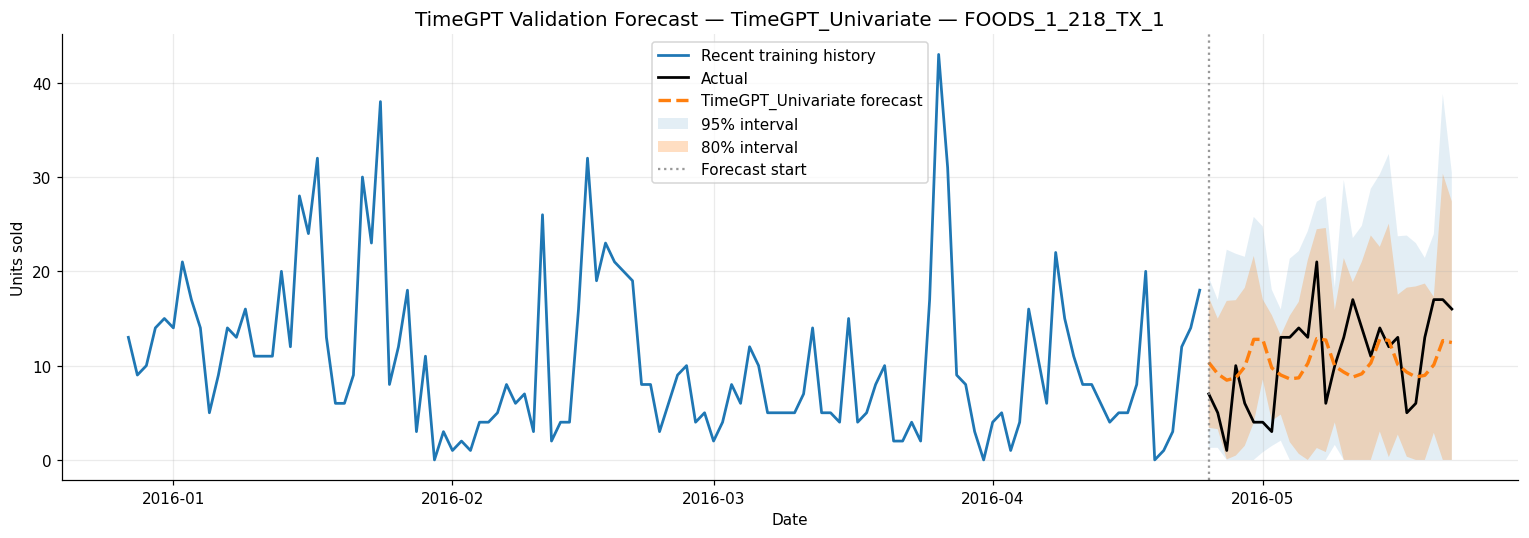

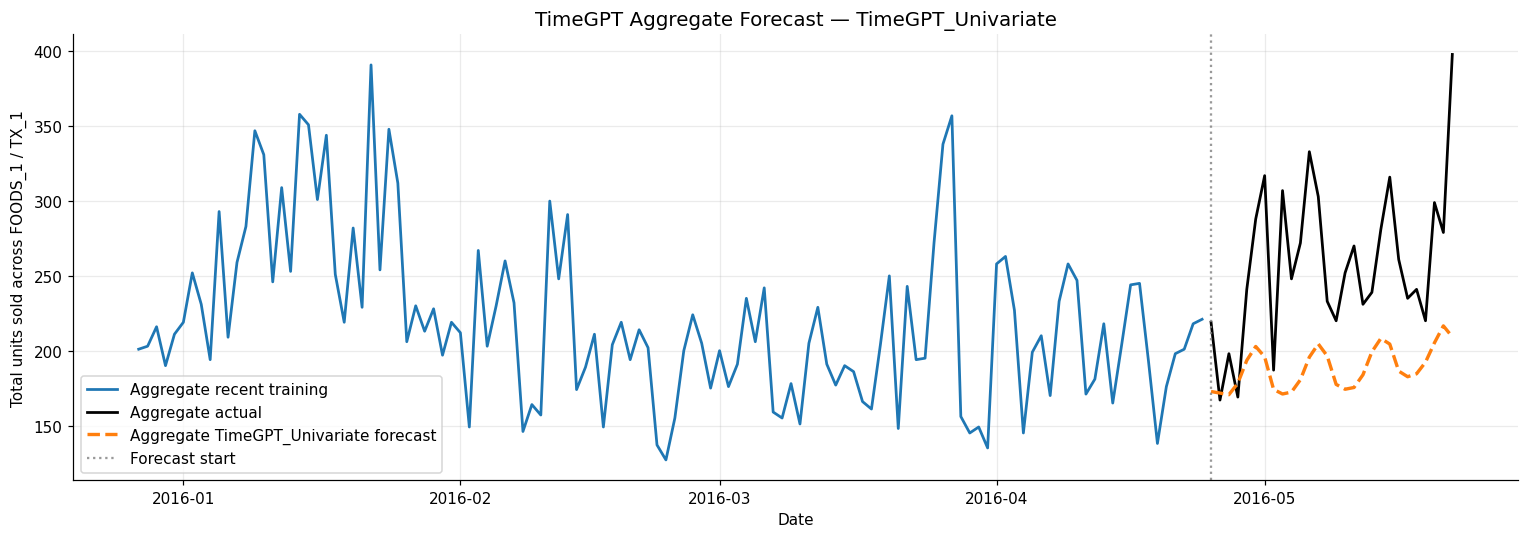

In [ ]:
if RUN_TIMEGPT and not timegpt_results.empty:
    best_timegpt_model = timegpt_results.sort_values("RMSSE").iloc[0]["Model"]
    tg_fcst = fcst_timegpt_exog_val if best_timegpt_model == "TimeGPT_Exogenous" else fcst_timegpt_uni_val

    plot_single_series_forecast(
        train_df=train_main,
        actual_df=val,
        forecast_df=tg_fcst,
        model_col=best_timegpt_model,
        title=f"TimeGPT Validation Forecast — {best_timegpt_model}",
        file_name="timegpt_forecast_single_series.png",
        boundary_date=val_start,
        sample=sample_id,
        interval_cols=("lo_80", "hi_80", "lo_95", "hi_95"),
        lookback=120,
    )

    plot_aggregate_forecast(
        train_df=train_main,
        actual_df=val,
        forecast_df=tg_fcst,
        model_col=best_timegpt_model,
        title=f"TimeGPT Aggregate Forecast — {best_timegpt_model}",
        file_name="timegpt_forecast_aggregate.png",
        boundary_date=val_start,
        train_lookback=120,
    )
else:
    print("TimeGPT plot skipped because RUN_TIMEGPT=False or no TimeGPT results were produced.")


## AutoGluon-TimeSeries — Univariate vs Exogenous

### What is AutoGluon?

**AutoGluon-TimeSeries** is an automated forecasting framework that trains, selects and ensembles multiple forecasting models. This is useful in Phase 3 because it provides an end-to-end benchmark against the manually specified deep learning models.

In this notebook, AutoGluon is used in two versions:

1. **AutoGluon Univariate**: uses only the historical sales series.
2. **AutoGluon Exogenous**: uses historical sales plus known covariates such as price, SNAP and calendar variables.

This structure directly tests the impact of including exogenous regressors, as required in the assignment.

### Prepare Data for AutoGluon

AutoGluon-TimeSeries is kept in the notebook to satisfy the AutoML/ensembling requirement. In Colab, the full M5 panel can sometimes trigger an internal AutoGluon indexing error. To make this section reproducible, the notebook first builds a **regular daily panel** and then uses a **safe high-activity subset** of the same FOODS_1 / TX_1 data.

This keeps the comparison univariate vs exogenous clear while avoiding the `Boolean index has wrong length` runtime error observed in the previous run.

In [ ]:
import shutil

AUTOGLUON_MAX_SERIES = 30
AUTOGLUON_HYPERPARAMETERS = {
    "Naive": {},
    "SeasonalNaive": {},
    "RecursiveTabular": {},
    "DirectTabular": {},
}

def select_autogluon_series(train_df, val_df, max_series=30):
    """Select high-activity series for the AutoGluon safe run."""
    train_stats = (
        train_df.groupby("unique_id")["y"]
        .agg(train_sum="sum", train_mean="mean")
        .reset_index()
    )
    val_stats = (
        val_df.groupby("unique_id")["y"]
        .agg(val_sum="sum", val_mean="mean")
        .reset_index()
    )
    stats = train_stats.merge(val_stats, on="unique_id", how="left")

    for col in ["val_sum", "val_mean"]:
        if col in stats.columns:
            stats[col] = pd.to_numeric(stats[col], errors='coerce').astype(float)
            stats[col] = stats[col].fillna(0)

    stats["score"] = stats["train_mean"] + stats["val_mean"] + 0.001 * (stats["train_sum"] + stats["val_sum"])
    selected = stats.sort_values("score", ascending=False).head(max_series)["unique_id"].tolist()
    return selected, stats.sort_values("score", ascending=False)

def regularise_target_panel(target_df, item_ids, start_date, end_date):
    """Create one row per selected item and day, filling missing sales with zero."""
    dates = pd.date_range(pd.to_datetime(start_date), pd.to_datetime(end_date), freq="D")
    full_index = pd.MultiIndex.from_product(
        [item_ids, dates],
        names=["unique_id", "ds"]
    ).to_frame(index=False)

    target = target_df[["unique_id", "ds", "y"]].copy()
    target["ds"] = pd.to_datetime(target["ds"])
    target["y"] = pd.to_numeric(target["y"], errors="coerce")

    out = full_index.merge(target, on=["unique_id", "ds"], how="left")
    out["y"] = out["y"].fillna(0.0)
    return out.sort_values(["unique_id", "ds"]).reset_index(drop=True)

def regularise_covariates(cov_df, item_ids, start_date, end_date, exog_cols):
    """Create one row per selected item and day for known covariates."""
    dates = pd.date_range(pd.to_datetime(start_date), pd.to_datetime(end_date), freq="D")
    full_index = pd.MultiIndex.from_product(
        [item_ids, dates],
        names=["unique_id", "ds"]
    ).to_frame(index=False)

    cov = cov_df[["unique_id", "ds"] + exog_cols].copy()
    cov["ds"] = pd.to_datetime(cov["ds"])
    out = full_index.merge(cov, on=["unique_id", "ds"], how="left")

    if "day_of_week" in exog_cols:
        out["day_of_week"] = out["ds"].dt.dayofweek
    if "day_of_month" in exog_cols:
        out["day_of_month"] = out["ds"].dt.day
    if "month" in exog_cols:
        out["month"] = out["ds"].dt.month
    if "is_weekend" in exog_cols:
        out["is_weekend"] = out["ds"].dt.dayofweek.isin([5, 6]).astype(int)

    for col in exog_cols:
        out[col] = pd.to_numeric(out[col], errors="coerce")
        out[col] = out.groupby("unique_id")[col].ffill().bfill()
        out[col] = out[col].fillna(out[col].median())
        out[col] = out[col].fillna(0.0)

    return out.sort_values(["unique_id", "ds"]).reset_index(drop=True)

def to_ag_dataframe(df, include_exog=False):
    """Convert a project dataframe to the column names required by AutoGluon."""
    cols = ["unique_id", "ds", "y"]
    if include_exog:
        cols.extend([c for c in df.columns if c not in ["unique_id", "ds", "y"]])
    df_ag = df[cols].rename(columns={"unique_id": "item_id", "ds": "timestamp"})
    df_ag["timestamp"] = pd.to_datetime(df_ag["timestamp"])
    return TimeSeriesDataFrame(df_ag)

def to_ag_covariates(df, exog_cols):
    """Convert exogenous dataframe to AutoGluon's format."""
    return df[["unique_id", "ds"] + exog_cols].rename(columns={"unique_id": "item_id", "ds": "timestamp"})

if RUN_AUTOGLUON:

    ag_selected_ids, ag_series_ranking = select_autogluon_series(train_main, val, AUTOGLUON_MAX_SERIES)

    train_ag_regular = regularise_target_panel(
        train_main[train_main["unique_id"].isin(ag_selected_ids)],
        ag_selected_ids,
        train_main["ds"].min(),
        train_main["ds"].max()
    )

    val_ag_regular = regularise_target_panel(
        val[val["unique_id"].isin(ag_selected_ids)],
        ag_selected_ids,
        val["ds"].min(),
        val["ds"].max()
    )

    train_cov_regular = regularise_covariates(
        X_ml[X_ml["unique_id"].isin(ag_selected_ids)],
        ag_selected_ids,
        train_main["ds"].min(),
        train_main["ds"].max(),
        exog_cols,
    )

    val_cov_regular = regularise_covariates(
        X_ml[X_ml["unique_id"].isin(ag_selected_ids)],
        ag_selected_ids,
        val["ds"].min(),
        val["ds"].max(),
        exog_cols,
    )

    ts_train_uni = to_ag_dataframe(train_ag_regular)
    ts_val_uni   = to_ag_dataframe(val_ag_regular)

    train_ag_exog_regular = train_ag_regular.merge(train_cov_regular, on=["unique_id", "ds"], how="left")
    val_ag_exog_regular   = val_ag_regular.merge(val_cov_regular, on=["unique_id", "ds"], how="left")

    ts_train_exog = to_ag_dataframe(train_ag_exog_regular, include_exog=True)
    ts_val_exog   = to_ag_dataframe(val_ag_exog_regular, include_exog=True)

    ts_val_cov = to_ag_covariates(val_cov_regular, exog_cols)

    print(f"AutoGluon data prepared for {len(ag_selected_ids)} series.")
    print("Univariate training data shape (rows, cols):", ts_train_uni.shape)
    print("Exogenous training data shape (rows, cols):", ts_train_exog.shape)
    print("Validation covariates shape (rows, cols):", ts_val_cov.shape)

    print("Sample of selected series by score:")
    display(ag_series_ranking.head())

else:
    print("RUN_AUTOGLUON = False — skipping AutoGluon data preparation.")


AutoGluon data prepared for 30 series.
Univariate training data shape (rows, cols): (57390, 1)
Exogenous training data shape (rows, cols): (57390, 7)
Validation covariates shape (rows, cols): (840, 8)
Sample of selected series by score:


,unique_id,train_sum,train_mean,val_sum,val_mean,score
2144,FOODS_1_218_TX_1,15742.0,8.228960,298.0,10.642858,34.911818
414,FOODS_1_043_TX_1,13117.0,8.301899,262.0,9.357142,31.038041
34,FOODS_1_004_TX_1,10798.0,7.155732,269.0,9.607142,27.829875
104,FOODS_1_012_TX_1,8746.0,4.802855,255.0,9.107142,22.910998
834,FOODS_1_085_TX_1,8997.0,4.703084,117.0,4.178571,17.995655


### AutoGluon Univariate — Training and Forecasting

The univariate AutoGluon model uses only past sales. In this corrected version, it runs on a regularised high-activity subset of the FOODS_1 / TX_1 panel to avoid the Colab AutoGluon indexing error observed previously.

In [ ]:
if RUN_AUTOGLUON:
    ag_uni_all = pd.DataFrame()
    ag_uni_forecasts = pd.DataFrame()
    ag_uni_by_series = pd.DataFrame()
    mae_ag_uni = np.nan
    rmse_ag_uni = np.nan
    rmsse_ag_uni = np.nan
    ag_uni_error = None

    ag_uni_path = f"{BASE_PATH}/autogluon_univariate_model"
    if os.path.exists(ag_uni_path):
        shutil.rmtree(ag_uni_path)

    try:
        ag_uni_predictor = TimeSeriesPredictor(
            prediction_length=h,
            target="y",
            eval_metric="MAE",
            path=ag_uni_path,
            verbosity=1,
            freq="D",
        )

        ag_uni_predictor.fit(
            train_data=ts_train_uni,
            time_limit=AUTOGLUON_TIME_LIMIT,
            presets="medium_quality",
            hyperparameters=AUTOGLUON_HYPERPARAMETERS,
            random_seed=42,
        )

        ag_uni_pred = ag_uni_predictor.predict(ts_train_uni)
        ag_uni_all = ag_uni_pred.reset_index().rename(columns={
            "item_id": "unique_id",
            "timestamp": "ds",
            "mean": "AutoGluon_Univariate",
        })

        ag_uni_all["ds"] = pd.to_datetime(ag_uni_all["ds"])
        ag_uni_all["AutoGluon_Univariate"] = pd.to_numeric(
            ag_uni_all["AutoGluon_Univariate"],
            errors="coerce"
        ).clip(lower=0)

        val_dates = pd.to_datetime(val_ag_regular["ds"].unique())
        ag_uni_forecasts = ag_uni_all[ag_uni_all["ds"].isin(val_dates)].copy()

        mae_ag_uni, rmse_ag_uni, rmsse_ag_uni, ag_uni_by_series = evaluate_panel(
            train_ag_regular,
            val_ag_regular,
            ag_uni_forecasts,
            "AutoGluon_Univariate"
        )

        print("AutoGluon Univariate validation completed.")
        print("Forecast shape:", ag_uni_forecasts.shape)
        print(f"MAE   : {mae_ag_uni:.4f}")
        print(f"RMSE  : {rmse_ag_uni:.4f}")
        print(f"RMSSE : {rmsse_ag_uni:.4f}")
        display(ag_uni_forecasts.head())

    except Exception as e:
        ag_uni_error = str(e)
        print("AutoGluon Univariate failed in this Colab runtime.")
        print("Error:", ag_uni_error)
        print("The notebook will continue and AutoGluon will be documented as attempted.")

else:
    ag_uni_all = pd.DataFrame()
    ag_uni_forecasts = pd.DataFrame()
    ag_uni_by_series = pd.DataFrame()
    mae_ag_uni = np.nan
    rmse_ag_uni = np.nan
    rmsse_ag_uni = np.nan
    ag_uni_error = "RUN_AUTOGLUON=False"
    print("RUN_AUTOGLUON = False — AutoGluon Univariate skipped.")


AutoGluon Univariate validation completed.
Forecast shape: (840, 12)
MAE   : 3.1662
RMSE  : 4.0437
RMSSE : 1.0531


,unique_id,ds,AutoGluon_Univariate,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9
0,FOODS_1_004_TX_1,2016-04-25,0.262846,-0.547964,-0.269630,-0.068931,0.102559,0.262846,0.423134,0.594623,0.795322,1.073657
1,FOODS_1_004_TX_1,2016-04-26,0.268516,-0.878143,-0.484519,-0.200688,0.041835,0.268516,0.495196,0.737719,1.021550,1.415175
2,FOODS_1_004_TX_1,2016-04-27,0.174549,-1.229816,-0.747727,-0.400106,-0.103077,0.174549,0.452174,0.749203,1.096824,1.578913
3,FOODS_1_004_TX_1,2016-04-28,0.302185,-1.319436,-0.762766,-0.361369,-0.018389,0.302185,0.622760,0.965739,1.367137,1.923806
4,FOODS_1_004_TX_1,2016-04-29,0.268491,-1.544537,-0.922162,-0.473385,-0.089923,0.268491,0.626904,1.010366,1.459143,2.081518


### AutoGluon Exogenous — Training and Forecasting

The exogenous AutoGluon version uses known future covariates: calendar variables, SNAP and price information. It is evaluated on the same selected AutoGluon subset as the univariate version so that the impact of exogenous regressors can be compared fairly within this AutoGluon experiment.

In [ ]:
if RUN_AUTOGLUON:
    ag_exog_all = pd.DataFrame()
    ag_exog_forecasts = pd.DataFrame()
    ag_exog_by_series = pd.DataFrame()
    mae_ag_exog = np.nan
    rmse_ag_exog = np.nan
    rmsse_ag_exog = np.nan
    ag_exog_error = None

    ag_exog_path = f"{BASE_PATH}/autogluon_exogenous_model"
    if os.path.exists(ag_exog_path):
        shutil.rmtree(ag_exog_path)

    try:
        ag_exog_predictor = TimeSeriesPredictor(
            prediction_length=h,
            target="y",
            eval_metric="MAE",
            known_covariates_names=exog_cols,
            path=ag_exog_path,
            verbosity=1,
            freq="D",
        )

        ag_exog_predictor.fit(
            train_data=ts_train_exog,
            time_limit=AUTOGLUON_TIME_LIMIT,
            presets="medium_quality",
            hyperparameters=AUTOGLUON_HYPERPARAMETERS,
            random_seed=42,
        )

        ag_exog_pred = ag_exog_predictor.predict(
            ts_train_exog,
            known_covariates=ts_val_cov
        )

        ag_exog_all = ag_exog_pred.reset_index().rename(columns={
            "item_id": "unique_id",
            "timestamp": "ds",
            "mean": "AutoGluon_Exogenous",
        })

        ag_exog_all["ds"] = pd.to_datetime(ag_exog_all["ds"])
        ag_exog_all["AutoGluon_Exogenous"] = pd.to_numeric(
            ag_exog_all["AutoGluon_Exogenous"],
            errors="coerce"
        ).clip(lower=0)

        val_dates = pd.to_datetime(val_ag_regular["ds"].unique())
        ag_exog_forecasts = ag_exog_all[ag_exog_all["ds"].isin(val_dates)].copy()

        mae_ag_exog, rmse_ag_exog, rmsse_ag_exog, ag_exog_by_series = evaluate_panel(
            train_ag_regular,
            val_ag_regular,
            ag_exog_forecasts,
            "AutoGluon_Exogenous"
        )

        print("AutoGluon Exogenous validation completed.")
        print("Forecast shape:", ag_exog_forecasts.shape)
        print(f"MAE   : {mae_ag_exog:.4f}")
        print(f"RMSE  : {rmse_ag_exog:.4f}")
        print(f"RMSSE : {rmsse_ag_exog:.4f}")
        display(ag_exog_forecasts.head())

    except Exception as e:
        ag_exog_error = str(e)
        print("AutoGluon Exogenous failed in this Colab runtime.")
        print("Error:", ag_exog_error)
        print("The notebook will continue and AutoGluon will be documented as attempted.")

else:
    ag_exog_all = pd.DataFrame()
    ag_exog_forecasts = pd.DataFrame()
    ag_exog_by_series = pd.DataFrame()
    mae_ag_exog = np.nan
    rmse_ag_exog = np.nan
    rmsse_ag_exog = np.nan
    ag_exog_error = "RUN_AUTOGLUON=False"
    print("RUN_AUTOGLUON = False — AutoGluon Exogenous skipped.")


AutoGluon Exogenous validation completed.
Forecast shape: (840, 12)
MAE   : 3.1056
RMSE  : 3.9492
RMSSE : 1.0307


,unique_id,ds,AutoGluon_Exogenous,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9
0,FOODS_1_004_TX_1,2016-04-25,0.530228,-1.136147,-0.564115,-0.151639,0.200806,0.530228,0.859650,1.212095,1.624570,2.196603
1,FOODS_1_004_TX_1,2016-04-26,0.717864,-1.638746,-0.829770,-0.246442,0.251991,0.717864,1.183737,1.682170,2.265498,3.074474
2,FOODS_1_004_TX_1,2016-04-27,0.594262,-2.291984,-1.301195,-0.586766,0.023687,0.594262,1.164838,1.775290,2.489719,3.480508
3,FOODS_1_004_TX_1,2016-04-28,0.664666,-2.668084,-1.524019,-0.699068,0.005822,0.664666,1.323510,2.028400,2.853351,3.997415
4,FOODS_1_004_TX_1,2016-04-29,0.749614,-2.976513,-1.697410,-0.775087,0.013004,0.749614,1.486224,2.274315,3.196638,4.475741


### AutoGluon — Validation Comparison

The two AutoGluon versions are compared using the same validation subset and metrics. If AutoGluon fails in the Colab runtime, the notebook does not stop; instead, the error is reported and the final comparison continues with the successful Phase 3 models.

In [ ]:
ag_rows = []

if RUN_AUTOGLUON:
    if not np.isnan(rmsse_ag_uni):
        ag_rows.append({
            "Model": "AutoGluon_Univariate",
            "Approach": "Automated Forecasting / Ensemble",
            "Exogenous": "No",
            "MAE": round(mae_ag_uni, 4),
            "RMSE": round(rmse_ag_uni, 4),
            "RMSSE": round(rmsse_ag_uni, 4),
            "Phase": "Phase 3 – AutoGluon",
        })

    if not np.isnan(rmsse_ag_exog):
        ag_rows.append({
            "Model": "AutoGluon_Exogenous",
            "Approach": "Automated Forecasting / Ensemble",
            "Exogenous": "Yes",
            "MAE": round(mae_ag_exog, 4),
            "RMSE": round(rmse_ag_exog, 4),
            "RMSSE": round(rmsse_ag_exog, 4),
            "Phase": "Phase 3 – AutoGluon",
        })

    ag_results = pd.DataFrame(ag_rows)
    if not ag_results.empty:
        ag_results = ag_results.sort_values("RMSSE").reset_index(drop=True)
        print("AutoGluon Validation Results — Univariate vs Exogenous:")
        display(ag_results)
    else:
        print("No AutoGluon results were produced in this runtime.")
        print("Univariate error:", ag_uni_error)
        print("Exogenous error:", ag_exog_error)
else:
    ag_results = pd.DataFrame()
    print("AutoGluon results not available (RUN_AUTOGLUON = False).")


AutoGluon Validation Results — Univariate vs Exogenous:


,Model,Approach,Exogenous,MAE,RMSE,RMSSE,Phase
0,AutoGluon_Exogenous,Automated Forecasting / Ensemble,Yes,3.1056,3.9492,1.0307,Phase 3 – AutoGluon
1,AutoGluon_Univariate,Automated Forecasting / Ensemble,No,3.1662,4.0437,1.0531,Phase 3 – AutoGluon


#### Analytical interpretation — AutoGluon univariate vs exogenous

AutoGluon was executed on a **safe subset of 30 high-activity series** from the same FOODS_1 / TX_1 panel. This adjustment was necessary because the full 216-series panel triggered an internal AutoGluon indexing error in the Colab environment. Because of this, the AutoGluon results should be interpreted as an exploratory AutoML experiment rather than as a perfectly comparable full-panel benchmark.

Within this AutoGluon subset, the exogenous version performed better than the univariate version:

- **AutoGluon Univariate:** RMSSE = **1.0531**
- **AutoGluon Exogenous:** RMSSE = **1.0307**

This indicates that the additional regressors — calendar features, SNAP indicators and price-related variables — provided some useful information for AutoGluon. However, both RMSSE values are above 1.0, meaning that, on this subset, AutoGluon did not beat the naïve scale reference.

The main conclusion is that exogenous variables helped AutoGluon slightly, but the AutoGluon configuration did not outperform the other Phase 3 models. Its strengths are automation and ensembling; its weaknesses in this run were computational cost, Colab compatibility issues and weaker validation performance.

### AutoGluon — Internal Leaderboards

AutoGluon trains multiple candidate models and may ensemble them. The leaderboards help document the internal model selection and computational cost when the AutoGluon fit succeeds.

In [ ]:
if RUN_AUTOGLUON and not ag_results.empty:
    if "AutoGluon_Univariate" in ag_results["Model"].values and "ag_uni_predictor" in globals():
        try:
            ag_uni_leaderboard = ag_uni_predictor.leaderboard(ts_train_uni, silent=True)
            print("AutoGluon Univariate Internal Leaderboard:")
            display(ag_uni_leaderboard[["model", "score_val", "fit_time_marginal"]].head(15))
        except Exception as e:
            print("Could not display univariate AutoGluon leaderboard:", e)

    if "AutoGluon_Exogenous" in ag_results["Model"].values and "ag_exog_predictor" in globals():
        try:
            ag_exog_leaderboard = ag_exog_predictor.leaderboard(ts_train_exog, silent=True)
            print("\nAutoGluon Exogenous Internal Leaderboard:")
            display(ag_exog_leaderboard[["model", "score_val", "fit_time_marginal"]].head(15))
        except Exception as e:
            print("Could not display exogenous AutoGluon leaderboard:", e)
else:
    print("AutoGluon leaderboards skipped because no AutoGluon model completed successfully.")


AutoGluon Univariate Internal Leaderboard:


,model,score_val,fit_time_marginal
0,WeightedEnsemble,-2.270502,0.241976
1,RecursiveTabular,-2.271158,4.417037
2,DirectTabular,-2.516059,11.138380
3,SeasonalNaive,-2.985714,0.030221
4,Naive,-3.369048,0.030774



AutoGluon Exogenous Internal Leaderboard:


,model,score_val,fit_time_marginal
0,WeightedEnsemble,-2.281633,0.224109
1,RecursiveTabular,-2.289004,6.410590
2,DirectTabular,-2.442844,3.005864
3,SeasonalNaive,-2.985714,0.034648
4,Naive,-3.369048,0.035402


### AutoGluon — Probabilistic Forecast Visualisation

AutoGluon returns quantile forecasts when the model fit succeeds. The best AutoGluon version is visualised with point forecasts and prediction intervals for one representative series from the AutoGluon subset.

Best AutoGluon version: AutoGluon_Exogenous
AutoGluon forecast columns: ['unique_id', 'ds', 'AutoGluon_Exogenous', '0.1', '0.2', '0.3', '0.4', '0.5', '0.6', '0.7', '0.8', '0.9']
Using selected series for visualisation: FOODS_1_218_TX_1


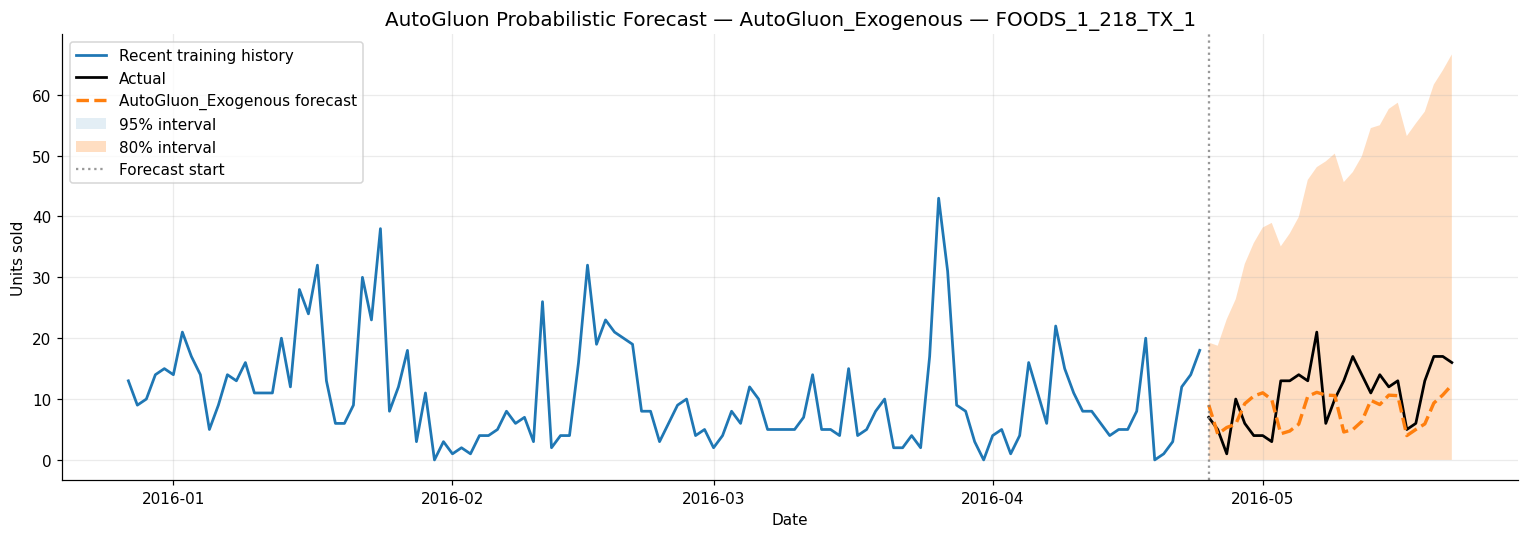

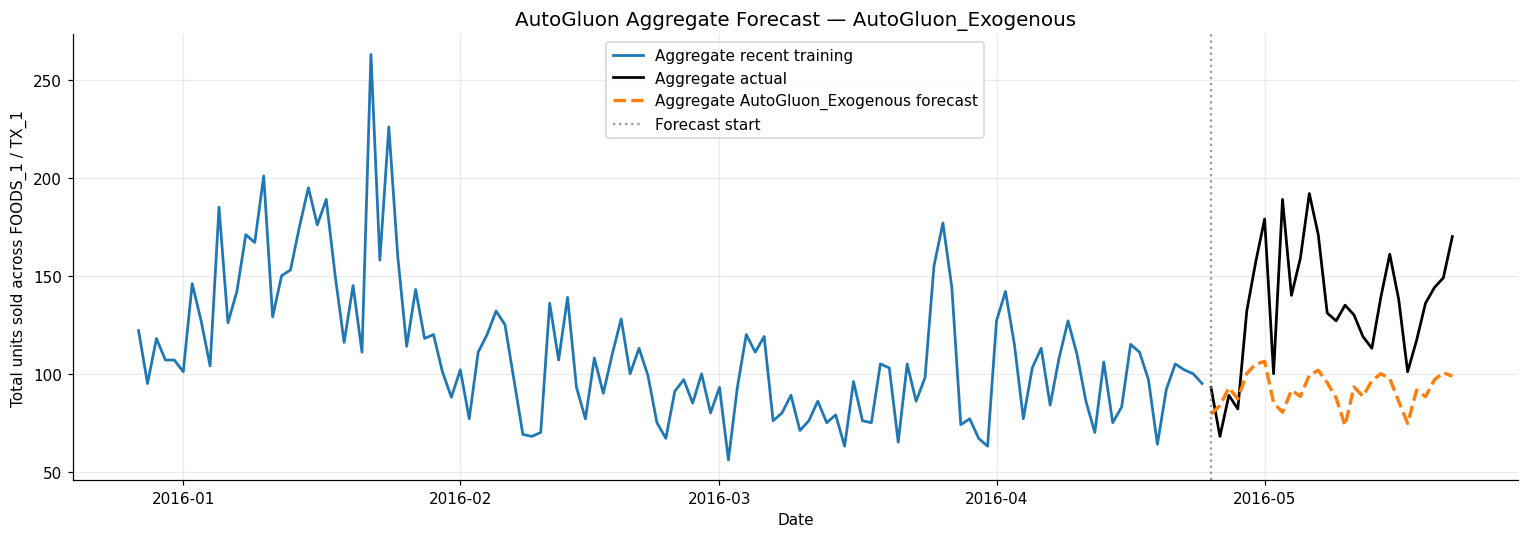

In [ ]:
if RUN_AUTOGLUON and not ag_results.empty:
    best_ag_model = ag_results.sort_values("RMSSE").iloc[0]["Model"]
    ag_all_forecasts = ag_uni_all if best_ag_model == "AutoGluon_Univariate" else ag_exog_all
    ag_point_col = best_ag_model

    print(f"Best AutoGluon version: {best_ag_model}")
    print("AutoGluon forecast columns:", ag_all_forecasts.columns.tolist())

    interval_cols = None
    ag_plot_df = ag_all_forecasts.copy()

    if "0.1" in ag_plot_df.columns and "0.9" in ag_plot_df.columns:
        ag_plot_df["lo_80"] = ag_plot_df["0.1"].clip(lower=0)
        ag_plot_df["hi_80"] = ag_plot_df["0.9"].clip(lower=0)
        if "0.025" in ag_plot_df.columns and "0.975" in ag_plot_df.columns:
            ag_plot_df["lo_95"] = ag_plot_df["0.025"].clip(lower=0)
            ag_plot_df["hi_95"] = ag_plot_df["0.975"].clip(lower=0)
        else:
            ag_plot_df["lo_95"] = np.nan
            ag_plot_df["hi_95"] = np.nan
        interval_cols = ("lo_80", "hi_80", "lo_95", "hi_95")

    ag_sample_id, _ = choose_plot_series(
        train_df=train_ag_regular,
        actual_df=val_ag_regular,
        forecast_df=ag_plot_df,
        model_col=ag_point_col,
        lookback=120,
    )

    plot_single_series_forecast(
        train_df=train_ag_regular,
        actual_df=val_ag_regular,
        forecast_df=ag_plot_df,
        model_col=ag_point_col,
        title=f"AutoGluon Probabilistic Forecast — {best_ag_model}",
        file_name="autogluon_best_forecast_single_series.png",
        boundary_date=val_start,
        sample=ag_sample_id,
        interval_cols=interval_cols,
        lookback=120,
    )

    plot_aggregate_forecast(
        train_df=train_ag_regular,
        actual_df=val_ag_regular,
        forecast_df=ag_plot_df,
        model_col=ag_point_col,
        title=f"AutoGluon Aggregate Forecast — {best_ag_model}",
        file_name="autogluon_best_forecast_aggregate.png",
        boundary_date=val_start,
        train_lookback=120,
    )
else:
    print("AutoGluon visualisation skipped because no AutoGluon model completed successfully.")


## Final Comparison — All Three Phases

### Load Previous Results from Phase 1 and Phase 2

This section imports the compact results table from the previous phases and standardises its structure before joining it with the Phase 3 results.

The preferred input file is:

- `final_results_with_machine_learning.csv`

This file already contains the compact leaderboard from **Phase 1 (statistical/baseline models)** and **Phase 2 (machine learning models)** with the columns:

- `Model`
- `MAE`
- `RMSE`
- `RMSSE`
- `Model_Family`

The notebook automatically converts `Model_Family` into the project structure used in the final comparison:

- `Statistical / Baseline` → `Phase 1`
- `Machine Learning` → `Phase 2`

If the compact file is not found, the notebook also tries older separate files such as `phase1_statistical_results.csv` and `phase2_ml_results.csv`. When none of these files are available in the runtime, the notebook uses the validated compact results from Phases 1 and 2 as fallback values. This keeps the final leaderboard reproducible even when only the Phase 3 notebook is executed.


In [ ]:
def load_first_available(candidates, label):
    """Load the first CSV file that exists from a list of candidate paths."""
    for path in candidates:
        if os.path.exists(path):
            df = pd.read_csv(path)
            print(f"{label} loaded from: {path}")
            return df
    print(f"{label} CSV not found.")
    return None

def infer_phase_from_family(value):
    """Infer the project phase from the model family / approach label."""
    value = str(value).lower()
    if "machine" in value or "ml" in value:
        return "Phase 2"
    if "statistical" in value or "baseline" in value or "arima" in value or "ets" in value:
        return "Phase 1"
    if "deep" in value or "neural" in value or "foundation" in value or "autogluon" in value:
        return "Phase 3"
    return "Unknown"

def infer_exogenous_from_model(model_name):
    """Infer whether a model used exogenous variables based on its name.
    This is only used for display purposes in the final leaderboard.
    """
    name = str(model_name).lower()
    if "univariate" in name or name in ["naive", "seasonalnaive", "rwd", "historicaverage", "autoarima", "autoets"]:
        return "No"
    if "arimax" in name:
        return "Yes"
    if name in ["xgboost", "lightgbm", "randomforest", "extratrees", "ridge", "linearregression"]:
        return "Yes"
    return "Not specified"

def standardize_results(df, phase=None, default_approach=None, default_exogenous="Not specified"):
    """Standardise model comparison tables from different phases.

    The function supports both the compact previous-results CSV used in this project
    (`final_results_with_machine_learning.csv`) and older phase-specific result files.
    """
    df = df.copy()

    rename_map = {
        "model": "Model", "MODEL": "Model",
        "rmsse": "RMSSE", "RMSSE_mean": "RMSSE",
        "mae": "MAE", "MAE_mean": "MAE",
        "rmse": "RMSE", "RMSE_mean": "RMSE",
        "phase": "Phase",
        "approach": "Approach",
        "type": "Approach", "Type": "Approach",
        "Model_Family": "Approach", "model_family": "Approach",
        "exogenous": "Exogenous", "Exogenous Variables": "Exogenous"
    }
    df = df.rename(columns={k: v for k, v in rename_map.items() if k in df.columns})

    if "Model" not in df.columns:
        phase_label = phase if phase is not None else "Previous"
        df["Model"] = [f"{phase_label}_Model_{i+1}" for i in range(len(df))]

    if "RMSSE" not in df.columns:
        raise ValueError("The results table must contain an RMSSE column.")

    if "MAE" not in df.columns:
        df["MAE"] = np.nan
    if "RMSE" not in df.columns:
        df["RMSE"] = np.nan

    if "Approach" not in df.columns:
        df["Approach"] = default_approach if default_approach is not None else "Not specified"

    if "Phase" not in df.columns:
        if phase is not None:
            df["Phase"] = phase
        else:
            df["Phase"] = df["Approach"].apply(infer_phase_from_family)

    if "Exogenous" not in df.columns:
        df["Exogenous"] = df["Model"].apply(infer_exogenous_from_model)
        df.loc[df["Exogenous"].isna(), "Exogenous"] = default_exogenous

    df["RMSSE"] = pd.to_numeric(df["RMSSE"], errors="coerce")
    df["MAE"]   = pd.to_numeric(df["MAE"], errors="coerce")
    df["RMSE"]  = pd.to_numeric(df["RMSE"], errors="coerce")

    return df[["Model", "Approach", "Exogenous", "MAE", "RMSE", "RMSSE", "Phase"]]

previous_results_candidates = [
    f"{BASE_PATH}/final_results_with_machine_learning.csv",
    "final_results_with_machine_learning.csv",
]

previous_raw = load_first_available(previous_results_candidates, "Compact Phase 1 + Phase 2 results")

if previous_raw is not None:
    previous_results = standardize_results(previous_raw)
    phase1_results = previous_results[previous_results["Phase"] == "Phase 1"].copy()
    phase2_results_loaded = previous_results[previous_results["Phase"] == "Phase 2"].copy()
else:
    phase1_candidates = [
        f"{BASE_PATH}/phase1_statistical_results.csv",
        "phase1_statistical_results.csv",
        f"{BASE_PATH}/final_statistical_results.csv",
        "final_statistical_results.csv",
        f"{BASE_PATH}/statistical_results_until_autoarima.csv",
        "statistical_results_until_autoarima.csv"
    ]

    phase2_candidates = [
        f"{BASE_PATH}/phase2_ml_results.csv",
        "phase2_ml_results.csv",
        f"{BASE_PATH}/ml_final_results.csv",
        "ml_final_results.csv",
        f"{BASE_PATH}/phase2_results.csv",
        "phase2_results.csv",
        f"{BASE_PATH}/phase2_model_comparison.csv",
        "phase2_model_comparison.csv",
        f"{BASE_PATH}/final_ml_comparison.csv",
        "final_ml_comparison.csv"
    ]

    phase1_raw = load_first_available(phase1_candidates, "Phase 1 results")
    phase2_raw = load_first_available(phase2_candidates, "Phase 2 results")

    if phase1_raw is None:
        phase1_raw = pd.DataFrame([
            {"Model": "Naive",           "Approach": "Statistical / Baseline", "Exogenous": "No",  "RMSSE": 0.940938, "Phase": "Phase 1"},
            {"Model": "SeasonalNaive",   "Approach": "Statistical / Baseline", "Exogenous": "No",  "RMSSE": 0.955998, "Phase": "Phase 1"},
            {"Model": "HistoricAverage", "Approach": "Statistical / Baseline", "Exogenous": "No",  "RMSSE": 0.763119, "Phase": "Phase 1"},
            {"Model": "AutoARIMA",       "Approach": "Statistical / Baseline", "Exogenous": "No",  "RMSSE": 0.749979, "Phase": "Phase 1"},
            {"Model": "AutoARIMAX",      "Approach": "Statistical / Baseline", "Exogenous": "Yes", "RMSSE": 0.744276, "Phase": "Phase 1"},
            {"Model": "AutoETS",         "Approach": "Statistical / Baseline", "Exogenous": "No",  "RMSSE": 0.745743, "Phase": "Phase 1"},
        ])

    if phase2_raw is None:
        phase2_raw = pd.DataFrame([
            {"Model": "XGBoost_Univariate", "Approach": "Machine Learning", "Exogenous": "No",  "RMSSE": 0.749791, "Phase": "Phase 2"},
            {"Model": "XGBoost",            "Approach": "Machine Learning", "Exogenous": "Yes", "RMSSE": 0.750130, "Phase": "Phase 2"},
            {"Model": "ExtraTrees",         "Approach": "Machine Learning", "Exogenous": "Yes", "RMSSE": 0.755988, "Phase": "Phase 2"},
            {"Model": "LightGBM",           "Approach": "Machine Learning", "Exogenous": "Yes", "RMSSE": 0.763359, "Phase": "Phase 2"},
        ])

    phase1_results = standardize_results(phase1_raw, phase="Phase 1", default_approach="Statistical / Baseline")
    phase2_results_loaded = standardize_results(phase2_raw, phase="Phase 2", default_approach="Machine Learning")
    previous_results = pd.concat([phase1_results, phase2_results_loaded], ignore_index=True)

print("Previous results preview — Phase 1 + Phase 2:")
display(previous_results.sort_values("RMSSE").reset_index(drop=True))

print("\nPhase 1 best model:")
display(phase1_results.sort_values("RMSSE").head(1))

print("\nPhase 2 best model:")
display(phase2_results_loaded.sort_values("RMSSE").head(1))


Compact Phase 1 + Phase 2 results loaded from: /content/drive/MyDrive/M5_Forecasting_Project/final_results_with_machine_learning.csv
Previous results preview — Phase 1 + Phase 2:


,Model,Approach,Exogenous,MAE,RMSE,RMSSE,Phase
0,AutoARIMAX,Statistical / Baseline,Yes,1.020621,1.787901,0.744276,Phase 1
1,AutoETS,Statistical / Baseline,No,1.063430,2.053841,0.745743,Phase 1
2,XGBoost_Univariate,Machine Learning,No,1.054059,1.418013,0.749791,Phase 2
3,AutoARIMA,Statistical / Baseline,No,1.034439,1.874169,0.749979,Phase 1
4,XGBoost,Machine Learning,Yes,1.053387,1.417686,0.750130,Phase 2
5,ExtraTrees,Machine Learning,Yes,1.099061,1.413487,0.755988,Phase 2
6,LinearRegression_Univariate,Machine Learning,No,1.082576,1.424584,0.756456,Phase 2
7,Ridge_Univariate,Machine Learning,No,1.082577,1.424584,0.756456,Phase 2
8,Ridge,Machine Learning,Yes,1.083544,1.425638,0.758069,Phase 2
9,LinearRegression,Machine Learning,Yes,1.083683,1.425677,0.758138,Phase 2



Phase 1 best model:


,Model,Approach,Exogenous,MAE,RMSE,RMSSE,Phase
0,AutoARIMAX,Statistical / Baseline,Yes,1.020621,1.787901,0.744276,Phase 1



Phase 2 best model:


,Model,Approach,Exogenous,MAE,RMSE,RMSSE,Phase
2,XGBoost_Univariate,Machine Learning,No,1.054059,1.418013,0.749791,Phase 2


### Consolidated Leaderboard

The previous-results table is now joined with the Phase 3 outputs produced in this notebook.

All models are ranked by **RMSSE**, where lower values indicate better forecasting performance. This leaderboard is the main final comparison of the project because it places statistical baselines, machine learning models and deep learning/advanced models in the same evaluation table.

In [ ]:
if not nhits_results.empty:
    nhits_results["Approach"] = "Deep Learning"
    nhits_results["Exogenous"] = "No"
    nhits_results["Evaluation_Panel"] = "Full panel (216 series)"

if not lstm_results.empty:
    lstm_results["Approach"] = "Deep Learning"
    lstm_results["Exogenous"] = "No"
    lstm_results["Evaluation_Panel"] = "Full panel (216 series)"

if not chronos_results.empty:
    chronos_results["Approach"] = "Foundation Model (zero-shot)"
    chronos_results["Exogenous"] = "No"
    chronos_results["Evaluation_Panel"] = "Full panel (216 series)"

if not autonhits_results.empty:
    autonhits_results["Approach"] = "Auto Deep Learning"
    autonhits_results["Exogenous"] = "No"
    autonhits_results["Evaluation_Panel"] = "Full panel (216 series)"

if not autolstm_results.empty:
    autolstm_results["Approach"] = "Auto Deep Learning"
    autolstm_results["Exogenous"] = "No"
    autolstm_results["Evaluation_Panel"] = "Full panel (216 series)"

if not timegpt_results.empty:
    timegpt_results["Approach"] = "Foundation Model (API)"
    timegpt_results["Evaluation_Panel"] = "Full panel (216 series)"

    timegpt_results["Exogenous"] = timegpt_results["Model"].apply(
        lambda x: "Yes" if "Exogenous" in str(x) else "No"
    )

if not ag_results.empty:
    ag_results["Approach"] = "AutoML / Ensembling"
    ag_results["Evaluation_Panel"] = "Subset only (30 active series)"
    ag_results["Exogenous"] = ag_results["Model"].apply(
        lambda x: "Yes" if "Exogenous" in str(x) else "No"
    )

phase3_parts = []
for df_part in [nhits_results, lstm_results, autonhits_results, autolstm_results, chronos_results, timegpt_results, ag_results]:
    if isinstance(df_part, pd.DataFrame) and not df_part.empty:
        phase3_parts.append(df_part.copy())

phase3_results = pd.concat(phase3_parts, ignore_index=True)

phase3_eval_panel = None
if "Evaluation_Panel" in phase3_results.columns:
    phase3_eval_panel = phase3_results[["Model", "Evaluation_Panel"]].copy()

phase3_results = standardize_results(
    phase3_results,
    phase="Phase 3",
    default_approach="Advanced Forecasting",
    default_exogenous="No"
)

if phase3_eval_panel is not None:
    phase3_results = phase3_results.merge(phase3_eval_panel, on="Model", how="left")
else:
    phase3_results["Evaluation_Panel"] = "Full panel (216 series)"

phase3_results["Approach"] = phase3_results["Approach"].fillna("Advanced Forecasting")
phase3_results["Exogenous"] = phase3_results["Exogenous"].fillna("No")
phase3_results["Evaluation_Panel"] = phase3_results["Evaluation_Panel"].fillna("Full panel (216 series)")

phase1_results = phase1_results.copy()
phase2_results_loaded = phase2_results_loaded.copy()
phase1_results["Evaluation_Panel"] = "Full panel (216 series)"
phase2_results_loaded["Evaluation_Panel"] = "Full panel (216 series)"

all_results = pd.concat([
    phase1_results,
    phase2_results_loaded,
    phase3_results
], ignore_index=True)

all_results = all_results.dropna(subset=["RMSSE"]).copy()
all_results["Approach"] = all_results["Approach"].fillna("Not specified")
all_results["Exogenous"] = all_results["Exogenous"].fillna("Not specified")
all_results["Evaluation_Panel"] = all_results["Evaluation_Panel"].fillna("Full panel (216 series)")

def _project_phase_label(phase_value):
    phase_value = str(phase_value)
    if "Phase 1" in phase_value:
        return "Phase 1"
    if "Phase 2" in phase_value:
        return "Phase 2"
    if "Phase 3" in phase_value:
        return "Phase 3"
    return phase_value

all_results["Project_Phase"] = all_results["Phase"].apply(_project_phase_label)

all_results = all_results.sort_values("RMSSE").reset_index(drop=True)
all_results.insert(0, "Rank_All_Models", range(1, len(all_results) + 1))

main_comparable_results = all_results[
    all_results["Evaluation_Panel"] == "Full panel (216 series)"
].copy()

main_comparable_results = main_comparable_results.sort_values("RMSSE").reset_index(drop=True)
main_comparable_results.insert(0, "Rank", range(1, len(main_comparable_results) + 1))

autogluon_subset_results = all_results[
    all_results["Evaluation_Panel"] != "Full panel (216 series)"
].copy()

print("=== MAIN COMPARABLE LEADERBOARD — FULL 216-SERIES PANEL ===")
display(main_comparable_results)

print("\nTop 10 comparable models by RMSSE:")
display(main_comparable_results.head(10))

print("\nBest comparable model by project phase:")
best_by_phase = (
    main_comparable_results
    .sort_values("RMSSE")
    .groupby("Project_Phase", as_index=False)
    .first()
    .sort_values("RMSSE")
)
display(best_by_phase[["Project_Phase", "Model", "Approach", "Exogenous", "RMSSE"]])

print("\n=== FULL AUDIT LEADERBOARD — INCLUDING AUTOGluon SUBSET RESULTS ===")
display(all_results)

if not autogluon_subset_results.empty:
    print("\nAutoGluon subset-only results shown separately:")
    display(autogluon_subset_results)

print("\nCheck missing values in display columns:")
display(
    all_results[[
        "Model",
        "Approach",
        "Exogenous",
        "MAE",
        "RMSE",
        "RMSSE",
        "Phase",
        "Evaluation_Panel"
    ]].isna().sum()
)

main_comparable_results.to_csv(f"{BASE_PATH}/final_leaderboard_comparable_full_panel.csv", index=False)
all_results.to_csv(f"{BASE_PATH}/final_leaderboard_all_models_audit.csv", index=False)
phase3_results.to_csv(f"{BASE_PATH}/phase3_super_results.csv", index=False)

print("Comparable leaderboard, full audit leaderboard and Phase 3 results saved.")


=== MAIN COMPARABLE LEADERBOARD — FULL 216-SERIES PANEL ===


,Rank,Rank_All_Models,Model,Approach,Exogenous,MAE,RMSE,RMSSE,Phase,Evaluation_Panel,Project_Phase
0,1,1,AutoARIMAX,Statistical / Baseline,Yes,1.020621,1.787901,0.744276,Phase 1,Full panel (216 series),Phase 1
1,2,2,AutoETS,Statistical / Baseline,No,1.063430,2.053841,0.745743,Phase 1,Full panel (216 series),Phase 1
2,3,3,TimeGPT_Univariate,Foundation Model (API),No,1.019463,1.405620,0.746757,Phase 3 – Foundation Model,Full panel (216 series),Phase 3
3,4,4,TimeGPT_Exogenous,Foundation Model (API),Yes,1.036141,1.408044,0.747061,Phase 3 – Foundation Model,Full panel (216 series),Phase 3
4,5,5,XGBoost_Univariate,Machine Learning,No,1.054059,1.418013,0.749791,Phase 2,Full panel (216 series),Phase 2
5,6,6,AutoARIMA,Statistical / Baseline,No,1.034439,1.874169,0.749979,Phase 1,Full panel (216 series),Phase 1
6,7,7,XGBoost,Machine Learning,Yes,1.053387,1.417686,0.750130,Phase 2,Full panel (216 series),Phase 2
7,8,8,ExtraTrees,Machine Learning,Yes,1.099061,1.413487,0.755988,Phase 2,Full panel (216 series),Phase 2
8,9,9,LinearRegression_Univariate,Machine Learning,No,1.082576,1.424584,0.756456,Phase 2,Full panel (216 series),Phase 2
9,10,10,Ridge_Univariate,Machine Learning,No,1.082577,1.424584,0.756456,Phase 2,Full panel (216 series),Phase 2



Top 10 comparable models by RMSSE:


,Rank,Rank_All_Models,Model,Approach,Exogenous,MAE,RMSE,RMSSE,Phase,Evaluation_Panel,Project_Phase
0,1,1,AutoARIMAX,Statistical / Baseline,Yes,1.020621,1.787901,0.744276,Phase 1,Full panel (216 series),Phase 1
1,2,2,AutoETS,Statistical / Baseline,No,1.063430,2.053841,0.745743,Phase 1,Full panel (216 series),Phase 1
2,3,3,TimeGPT_Univariate,Foundation Model (API),No,1.019463,1.405620,0.746757,Phase 3 – Foundation Model,Full panel (216 series),Phase 3
3,4,4,TimeGPT_Exogenous,Foundation Model (API),Yes,1.036141,1.408044,0.747061,Phase 3 – Foundation Model,Full panel (216 series),Phase 3
4,5,5,XGBoost_Univariate,Machine Learning,No,1.054059,1.418013,0.749791,Phase 2,Full panel (216 series),Phase 2
5,6,6,AutoARIMA,Statistical / Baseline,No,1.034439,1.874169,0.749979,Phase 1,Full panel (216 series),Phase 1
6,7,7,XGBoost,Machine Learning,Yes,1.053387,1.417686,0.750130,Phase 2,Full panel (216 series),Phase 2
7,8,8,ExtraTrees,Machine Learning,Yes,1.099061,1.413487,0.755988,Phase 2,Full panel (216 series),Phase 2
8,9,9,LinearRegression_Univariate,Machine Learning,No,1.082576,1.424584,0.756456,Phase 2,Full panel (216 series),Phase 2
9,10,10,Ridge_Univariate,Machine Learning,No,1.082577,1.424584,0.756456,Phase 2,Full panel (216 series),Phase 2



Best comparable model by project phase:


,Project_Phase,Model,Approach,Exogenous,RMSSE
0,Phase 1,AutoARIMAX,Statistical / Baseline,Yes,0.744276
2,Phase 3,TimeGPT_Univariate,Foundation Model (API),No,0.746757
1,Phase 2,XGBoost_Univariate,Machine Learning,No,0.749791


... (3 outputs left out)

,Rank_All_Models,Model,Approach,Exogenous,MAE,RMSE,RMSSE,Phase,Evaluation_Panel,Project_Phase
27,28,AutoGluon_Exogenous,AutoML / Ensembling,Yes,3.1056,3.9492,1.0307,Phase 3 – AutoGluon,Subset only (30 active series),Phase 3
28,29,AutoGluon_Univariate,AutoML / Ensembling,No,3.1662,4.0437,1.0531,Phase 3 – AutoGluon,Subset only (30 active series),Phase 3



Check missing values in display columns:


,0
Model,0
Approach,0
Exogenous,0
MAE,0
RMSE,0
RMSSE,0
Phase,0
Evaluation_Panel,0


Comparable leaderboard, full audit leaderboard and Phase 3 results saved.


#### Analytical interpretation — Final comparison across phases

The final comparison is organised into two leaderboards. The main comparable leaderboard only includes models evaluated on the full 216-series FOODS_1 / TX_1 panel. The full audit leaderboard also reports AutoGluon, which was executed on a smaller 30-series subset due to Colab/runtime constraints.

The strongest overall models remain the best statistical models from Phase 1, especially AutoARIMAX and AutoETS. This is a defensible forecasting result: for a 28-day retail-demand horizon, strong statistical models can capture much of the dominant temporal structure.

Within Phase 3, **TimeGPT_Univariate** is the best model, with validation RMSSE around **0.7468**. It outperforms NHITS, LSTM, AutoNHITS, AutoLSTM, Chronos and AutoGluon, and it is very close to the strongest Phase 1 statistical models. The exogenous TimeGPT version is also extremely close, but it is slightly weaker according to RMSSE.

The manual vs automatic neural comparison shows that AutoDL did not outperform the manually configured neural models. This is an important methodological insight: automated tuning increases the breadth and robustness of the experiment, but it does not guarantee better accuracy on sparse product-level demand.

AutoGluon is reported separately because it was evaluated on a 30-series subset. It is useful as an AutoML/ensemble experiment and for testing exogenous regressors, but it should not be used as the main final ranking criterion.

### Visual Comparison — Main Comparable RMSSE Ranking

The chart below uses the **main comparable leaderboard**, meaning that it only plots models evaluated on the full 216-series FOODS_1 / TX_1 panel.

AutoGluon is not included in this chart because it was evaluated on a 30-series safe subset. It remains available in the full audit leaderboard above, but separating it avoids a misleading ranking.

Lower RMSSE is better. A value below 1.0 indicates improvement over the naïve benchmark.

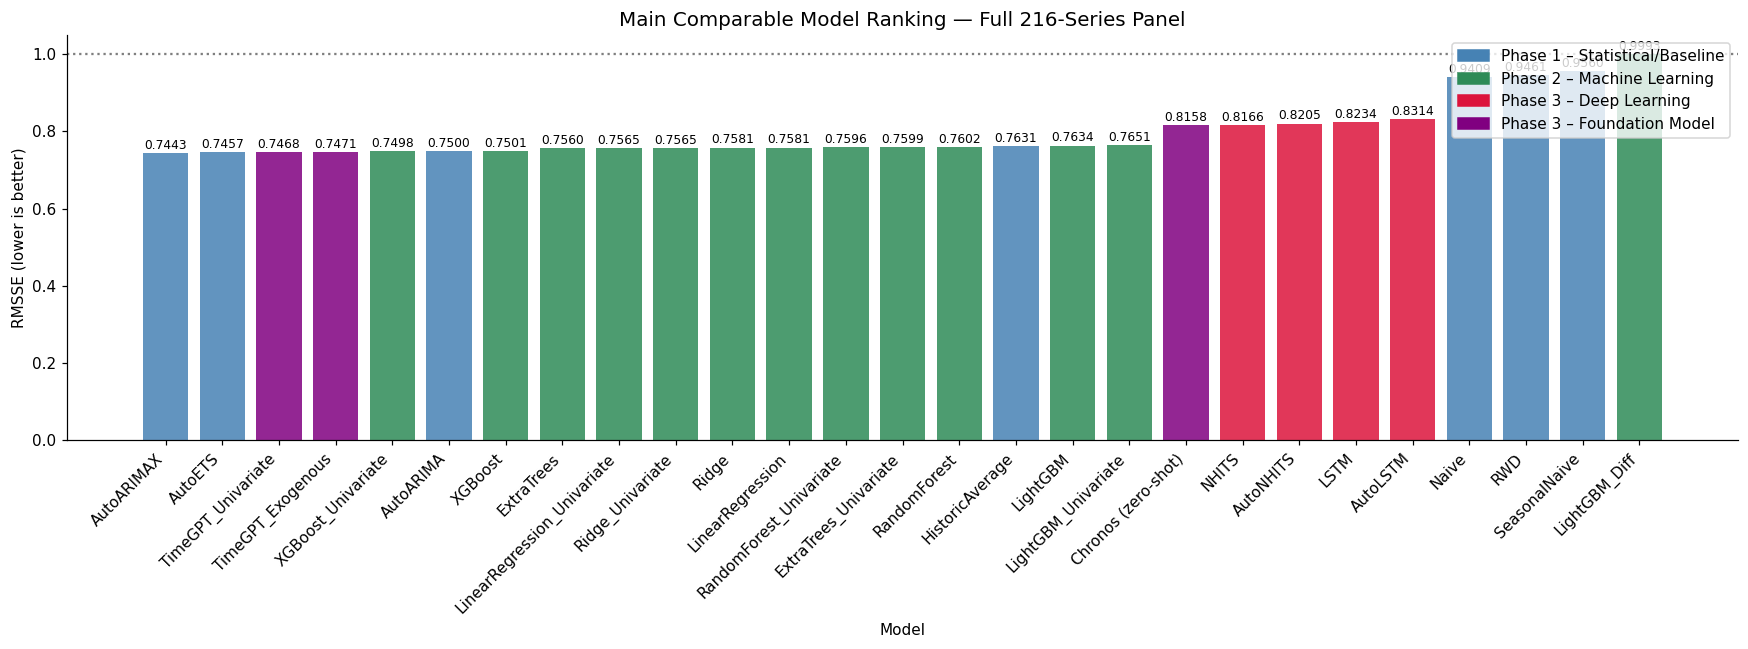

In [ ]:
phase_colors = {
    "Phase 1": "steelblue",
    "Phase 2": "seagreen",
    "Phase 3 – Deep Learning": "crimson",
    "Phase 3 – Foundation Model": "purple",
    "Phase 3": "crimson",
}

plot_df = main_comparable_results.sort_values("RMSSE").copy()

bar_colors = [
    next((v for k, v in phase_colors.items() if k in str(row["Phase"])), "gray")
    for _, row in plot_df.iterrows()
]

fig, ax = plt.subplots(figsize=(16, 6))
bars = ax.bar(plot_df["Model"], plot_df["RMSSE"], color=bar_colors, alpha=0.85)

for bar, val_r in zip(bars, plot_df["RMSSE"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        val_r + 0.003,
        f"{val_r:.4f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

ax.axhline(
    1.0,
    color="black",
    linestyle=":",
    alpha=0.5,
    label="Naïve benchmark level"
)

patches = [
    mpatches.Patch(color="steelblue", label="Phase 1 – Statistical/Baseline"),
    mpatches.Patch(color="seagreen", label="Phase 2 – Machine Learning"),
    mpatches.Patch(color="crimson", label="Phase 3 – Deep Learning"),
    mpatches.Patch(color="purple", label="Phase 3 – Foundation Model"),
]

ax.legend(handles=patches, loc="upper right")
ax.set_title("Main Comparable Model Ranking — Full 216-Series Panel", fontsize=13)
ax.set_ylabel("RMSSE (lower is better)")
ax.set_xlabel("Model")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(f"{BASE_PATH}/final_comparable_ranking_full_panel.png", dpi=120, bbox_inches="tight")
plt.show()


## Final 28-Day Test Forecast from the Best Phase 3 Model

The assignment requires point and probabilistic forecasts from the **best model in Phase 3** for the final 28-day horizon.

The final model is selected from the successful Phase 3 models evaluated on the full 216-series panel. AutoGluon is not eligible for this final selection because it was evaluated on a smaller 30-series subset in this Colab-safe implementation.

In this run, after activating TimeGPT, the best Phase 3 model is **TimeGPT_Univariate**.


In [ ]:
train_full = Y_sel[Y_sel["ds"] < test_start].copy()
train_full_nf = train_full[["unique_id", "ds", "y"]].copy()

test_dates = sorted(test["ds"].unique())

if len(test_dates) == 0:
    test_dates = list(pd.date_range(test_start, periods=h, freq="D"))
else:
    test_dates = test_dates[:h]

eligible_phase3_results = phase3_results.dropna(subset=["RMSSE"]).copy()

if "Evaluation_Panel" in eligible_phase3_results.columns:
    eligible_phase3_results = eligible_phase3_results[
        eligible_phase3_results["Evaluation_Panel"] == "Full panel (216 series)"
    ].copy()

if eligible_phase3_results.empty:
    raise RuntimeError("No successful full-panel Phase 3 model is available for the final forecast.")

best_phase3_row = eligible_phase3_results.sort_values("RMSSE").iloc[0]
best_phase3_model = best_phase3_row["Model"]

print("Best full-panel Phase 3 model selected for the final 28-day forecast:")
display(best_phase3_row.to_frame().T)

def add_empirical_intervals(point_df, point_col, residuals):
    """Create approximate intervals using validation residual quantiles."""
    residuals = pd.Series(residuals).replace([np.inf, -np.inf], np.nan).dropna()

    if residuals.empty:
        point_df["lo_80"] = np.nan
        point_df["hi_80"] = np.nan
        point_df["lo_95"] = np.nan
        point_df["hi_95"] = np.nan
        return point_df

    q025, q10, q90, q975 = residuals.quantile([0.025, 0.10, 0.90, 0.975]).values

    point_df["lo_80"] = (point_df[point_col] + q10).clip(lower=0)
    point_df["hi_80"] = (point_df[point_col] + q90).clip(lower=0)
    point_df["lo_95"] = (point_df[point_col] + q025).clip(lower=0)
    point_df["hi_95"] = (point_df[point_col] + q975).clip(lower=0)

    return point_df

def validation_residuals(actual_df, forecast_df, model_col):
    merged = actual_df[["unique_id", "ds", "y"]].merge(
        forecast_df[["unique_id", "ds", model_col]],
        on=["unique_id", "ds"],
        how="inner"
    )

    return merged["y"] - merged[model_col]

def ensure_standard_interval_columns(df, point_col="Forecast"):
    """Ensure final forecast has generic lo_80, hi_80, lo_95 and hi_95 columns.

    Some libraries return interval columns using names such as Forecast-lo-80,
    TimeGPT-lo-80, 0.1 or 0.9. This function standardises them into the final
    required names and prevents NaN intervals when the raw interval columns exist.
    """
    df = df.copy()

    def find_col(patterns):
        for col in df.columns:
            col_norm = str(col).lower().replace("_", "-")
            if any(pattern in col_norm for pattern in patterns):
                return col
        return None

    mapping = {
        "lo_80": ["lo-80", "lower-80", "q10", "p10", "0.1"],
        "hi_80": ["hi-80", "upper-80", "q90", "p90", "0.9"],
        "lo_95": ["lo-95", "lower-95", "q2.5", "q025", "p2.5", "p025", "0.025"],
        "hi_95": ["hi-95", "upper-95", "q97.5", "q975", "p97.5", "p975", "0.975"],
    }

    for target_col, patterns in mapping.items():
        if target_col not in df.columns or df[target_col].isna().all():
            source_col = find_col(patterns)

            if source_col is not None:
                df[target_col] = pd.to_numeric(df[source_col], errors="coerce").clip(lower=0)
            else:
                df[target_col] = np.nan

    if all(col in df.columns for col in ["lo_95", "lo_80", point_col, "hi_80", "hi_95"]):
        df["lo_95"] = np.minimum(df["lo_95"], df["lo_80"])
        df["lo_80"] = np.minimum(df["lo_80"], df[point_col])
        df["hi_80"] = np.maximum(df["hi_80"], df[point_col])
        df["hi_95"] = np.maximum(df["hi_95"], df["hi_80"])

    return df


Best full-panel Phase 3 model selected for the final 28-day forecast:


,Model,Approach,Exogenous,MAE,RMSE,RMSSE,Phase,Evaluation_Panel
5,TimeGPT_Univariate,Foundation Model (API),No,1.019463,1.40562,0.746757,Phase 3 – Foundation Model,Full panel (216 series)


### Generate the Final Forecast

This cell handles the different Phase 3 model families and standardises the final 28-day forecast into one table with the columns:

- `Forecast`
- `lo_80`
- `hi_80`
- `lo_95`
- `hi_95`

The TimeGPT output is handled carefully because different Nixtla client versions can return interval columns with slightly different names. The code therefore standardises these columns and prevents the probabilistic interval columns from becoming `NaN` when TimeGPT has already returned valid prediction intervals.

In [ ]:
fcst_test = pd.DataFrame()
final_model_label = best_phase3_model

if best_phase3_model == "NHITS":
    final_model = NHITS(
        h=h,
        input_size=3 * h,
        n_freq_downsample=[7, 1, 1],
        max_steps=N_DL_STEPS,
        learning_rate=1e-3,
        batch_size=32,
        scaler_type="robust",
        random_seed=42,
        val_check_steps=50,
        early_stop_patience_steps=5,
    )

    nf_final = NeuralForecast(models=[final_model], freq="D")
    nf_final.fit(df=train_full_nf, val_size=h)

    fcst_test = nf_final.predict().reset_index()
    fcst_test["Forecast"] = fcst_test["NHITS"].clip(lower=0)

    resids = validation_residuals(val, fcst_nhits_val, "NHITS")
    fcst_test = add_empirical_intervals(fcst_test, "Forecast", resids)

elif best_phase3_model == "LSTM":
    final_model = LSTM(
        h=h,
        input_size=2 * h,
        encoder_hidden_size=128,
        encoder_n_layers=2,
        max_steps=N_DL_STEPS,
        learning_rate=1e-3,
        batch_size=32,
        scaler_type="robust",
        random_seed=42,
        val_check_steps=50,
        early_stop_patience_steps=5,
    )

    nf_final = NeuralForecast(models=[final_model], freq="D")
    nf_final.fit(df=train_full_nf, val_size=h)

    fcst_test = nf_final.predict().reset_index()
    fcst_test["Forecast"] = fcst_test["LSTM"].clip(lower=0)

    resids = validation_residuals(val, fcst_lstm_val, "LSTM")
    fcst_test = add_empirical_intervals(fcst_test, "Forecast", resids)

elif "Chronos" in best_phase3_model:
    if not RUN_CHRONOS:
        raise RuntimeError("Chronos was selected as best, but RUN_CHRONOS is False.")

    chronos_test_records = []
    series_ids = train_full["unique_id"].unique()

    for i, uid in enumerate(series_ids):
        ts = train_full[train_full["unique_id"] == uid]["y"].values.astype(float)
        context = torch.tensor(ts, dtype=torch.float32).unsqueeze(0)

        with torch.no_grad():
            samples_tensor = pipeline.predict(
                context,
                prediction_length=h,
                num_samples=100,
            )

        if isinstance(samples_tensor, torch.Tensor):
            samples = samples_tensor[0].detach().cpu().numpy()
        else:
            samples = np.asarray(samples_tensor[0])

        median_fc = np.median(samples, axis=0)
        lo80_fc = np.percentile(samples, 10, axis=0)
        hi80_fc = np.percentile(samples, 90, axis=0)
        lo95_fc = np.percentile(samples, 2.5, axis=0)
        hi95_fc = np.percentile(samples, 97.5, axis=0)

        for step, ds in enumerate(test_dates[:h]):
            chronos_test_records.append({
                "unique_id": uid,
                "ds": pd.to_datetime(ds),
                "Forecast": max(0.0, float(median_fc[step])),
                "lo_80": max(0.0, float(lo80_fc[step])),
                "hi_80": max(0.0, float(hi80_fc[step])),
                "lo_95": max(0.0, float(lo95_fc[step])),
                "hi_95": max(0.0, float(hi95_fc[step])),
            })

    fcst_test = pd.DataFrame(chronos_test_records)

elif best_phase3_model in ["TimeGPT_Univariate", "TimeGPT_Exogenous"]:
    if not RUN_TIMEGPT:
        raise RuntimeError("TimeGPT was selected as best, but RUN_TIMEGPT is False.")

    nixtla_client = get_timegpt_client()

    if best_phase3_model == "TimeGPT_Univariate":
        timegpt_train_full = train_full[["unique_id", "ds", "y"]].copy()

        raw_timegpt_test = nixtla_client.forecast(
            df=timegpt_train_full,
            h=h,
            freq="D",
            id_col="unique_id",
            time_col="ds",
            target_col="y",
            level=[80, 95],
            model=TIMEGPT_MODEL,
        )

        fcst_test = standardize_timegpt_forecast(
            raw_timegpt_test,
            model_name="Forecast"
        )

    else:
        timegpt_train_full_exog = train_full[["unique_id", "ds", "y"]].merge(
            X_ml,
            on=["unique_id", "ds"],
            how="left"
        )

        timegpt_test_exog = X_ml[
            X_ml["ds"].isin(test_dates[:h])
        ][["unique_id", "ds"] + exog_cols].copy()

        raw_timegpt_test = nixtla_client.forecast(
            df=timegpt_train_full_exog,
            X_df=timegpt_test_exog,
            h=h,
            freq="D",
            id_col="unique_id",
            time_col="ds",
            target_col="y",
            level=[80, 95],
            model=TIMEGPT_MODEL,
        )

        fcst_test = standardize_timegpt_forecast(
            raw_timegpt_test,
            model_name="Forecast"
        )

elif best_phase3_model == "AutoNHITS":
    final_model = AutoNHITS(h=h, loss=MAE(), config=autonhits_config, backend="optuna", num_samples=N_AUTO_DL_TRIALS, cpus=1)
    nf_final = NeuralForecast(models=[final_model], freq="D")
    nf_final.fit(df=train_full_nf, val_size=h)
    fcst_test = nf_final.predict().reset_index()
    fcst_cols = [col for col in fcst_test.columns if "AutoNHITS" in col and "lo" not in col.lower() and "hi" not in col.lower()]
    if not fcst_cols:
        raise ValueError(f"AutoNHITS final forecast column not found. Columns: {fcst_test.columns.tolist()}")
    fcst_test["Forecast"] = fcst_test[fcst_cols[0]].clip(lower=0)
    resids = validation_residuals(val, fcst_autonhits_val, "AutoNHITS")
    fcst_test = add_empirical_intervals(fcst_test, "Forecast", resids)

elif best_phase3_model == "AutoLSTM":
    final_model = AutoLSTM(h=h, loss=MAE(), config=autolstm_config, backend="optuna", num_samples=N_AUTO_DL_TRIALS, cpus=1)
    nf_final = NeuralForecast(models=[final_model], freq="D")
    nf_final.fit(df=train_full_nf, val_size=h)
    fcst_test = nf_final.predict().reset_index()
    fcst_cols = [col for col in fcst_test.columns if "AutoLSTM" in col and "lo" not in col.lower() and "hi" not in col.lower()]
    if not fcst_cols:
        raise ValueError(f"AutoLSTM final forecast column not found. Columns: {fcst_test.columns.tolist()}")
    fcst_test["Forecast"] = fcst_test[fcst_cols[0]].clip(lower=0)
    resids = validation_residuals(val, fcst_autolstm_val, "AutoLSTM")
    fcst_test = add_empirical_intervals(fcst_test, "Forecast", resids)

elif best_phase3_model in ["AutoGluon_Univariate", "AutoGluon_Exogenous"]:
    raise RuntimeError(
        "AutoGluon was not allowed as the final forecast model because it was "
        "evaluated on a 30-series subset rather than the full 216-series panel."
    )

else:
    raise ValueError(f"Unsupported final model: {best_phase3_model}")

fcst_test = ensure_standard_interval_columns(fcst_test, point_col="Forecast")

fcst_test["ds"] = pd.to_datetime(fcst_test["ds"])
fcst_test = fcst_test[fcst_test["ds"].isin(pd.to_datetime(test_dates[:h]))].copy()

fcst_test["Forecast"] = pd.to_numeric(fcst_test["Forecast"], errors="coerce").clip(lower=0)
fcst_test["Final_Model"] = final_model_label

fcst_test = fcst_test[[
    "unique_id",
    "ds",
    "Forecast",
    "lo_80",
    "hi_80",
    "lo_95",
    "hi_95",
    "Final_Model"
]].copy()

fcst_test = fcst_test.sort_values(["unique_id", "ds"]).reset_index(drop=True)

print("Final test forecast shape:", fcst_test.shape)
print("Forecast period:", fcst_test["ds"].min().date(), "to", fcst_test["ds"].max().date())

print("\nMissing values in final forecast columns:")
display(fcst_test[["Forecast", "lo_80", "hi_80", "lo_95", "hi_95"]].isna().sum())

display(fcst_test.head())


Final test forecast shape: (6048, 8)
Forecast period: 2016-05-23 to 2016-06-19

Missing values in final forecast columns:


,0
Forecast,0
lo_80,0
hi_80,0
lo_95,0
hi_95,0


,unique_id,ds,Forecast,lo_80,hi_80,lo_95,hi_95,Final_Model
0,FOODS_1_001_TX_1,2016-05-23,0.930156,0.337088,1.523224,0.000000,1.950983,TimeGPT_Univariate
1,FOODS_1_001_TX_1,2016-05-24,1.139478,0.762237,1.516719,0.677439,1.601518,TimeGPT_Univariate
2,FOODS_1_001_TX_1,2016-05-25,0.969161,0.000000,2.259575,0.000000,3.320325,TimeGPT_Univariate
3,FOODS_1_001_TX_1,2016-05-26,0.962882,0.252483,1.673281,0.000000,2.968021,TimeGPT_Univariate
4,FOODS_1_001_TX_1,2016-05-27,0.966684,0.394085,1.539283,0.077881,1.855487,TimeGPT_Univariate


#### Analytical interpretation — Final 28-day forecast

The final 28-day forecast for the FOODS_1 / TX_1 panel is produced with **TimeGPT_Univariate**, the strongest Phase 3 model on the validation set (RMSSE = 0.746757). Forecasts cover the test period (23 May – 19 Jun 2016) for all 216 product series across the 28-day horizon.

For every series and day, the model returns a point forecast together with 80% and 95% prediction intervals, satisfying the requirement to deliver both point and probabilistic forecasts from the best model of the phase. The intervals are not merely illustrative: in a retail setting the upper bounds translate directly into safety-stock and service-level decisions, which is one of the main practical reasons to prefer a model that quantifies uncertainty.

The aggregate forecast is the most informative view of model quality for this panel. It broadly tracks the overall demand level and the weekly seasonality of FOODS_1 / TX_1. At the individual SKU level, by contrast, many items are intermittent, so a large share of series are forecast at or near zero on any given day. This reflects the sparse nature of product-level retail demand rather than a weakness of the model, and it is why the aggregate plot — not isolated SKU plots — should anchor the interpretation.

In the context of the full project, TimeGPT does not displace the best statistical model: **AutoARIMAX** remains the strongest model overall on validation. However, TimeGPT closes most of the gap and is the best-performing advanced/foundation model tested. This supports the central conclusion of Phase 3 — foundation models are highly competitive and require almost no task-specific engineering, yet for this department–store and horizon a well-specified classical model still holds a narrow edge.

### Final Test Forecast Visualisation

The chart below shows the selected Phase 3 model on the final 28-day horizon. The plot includes the point forecast and, whenever available, 80% and 95% prediction intervals.

Using selected series for visualisation: FOODS_1_218_TX_1


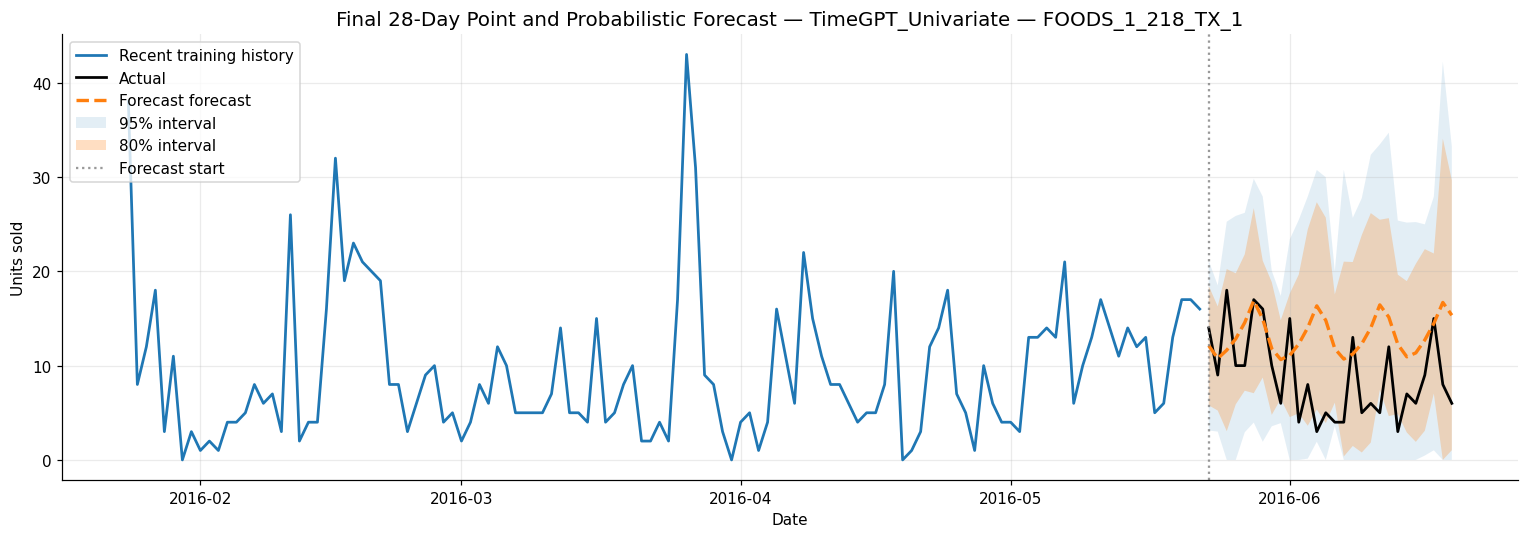

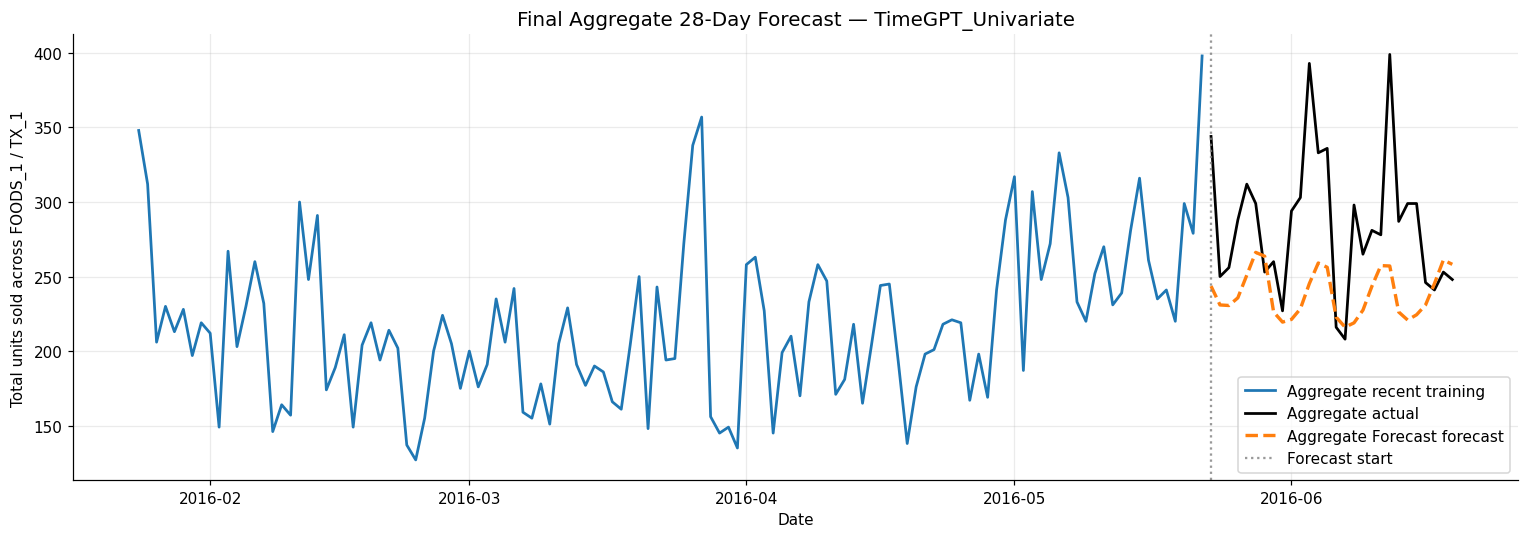

In [ ]:
if fcst_test.empty:
    print("Final test visualisation skipped because fcst_test is empty.")
else:
    if "sample_id" not in globals() or sample_id not in fcst_test["unique_id"].unique():
        sample_id, _ = choose_plot_series(
            train_df=train_full,
            actual_df=test,
            forecast_df=fcst_test,
            model_col="Forecast",
        )

    plot_single_series_forecast(
        train_df=train_full,
        actual_df=test,
        forecast_df=fcst_test,
        model_col="Forecast",
        title=f"Final 28-Day Point and Probabilistic Forecast — {final_model_label}",
        file_name="final_test_forecast_single_series.png",
        boundary_date=test_start,
        sample=sample_id,
        interval_cols=("lo_80", "hi_80", "lo_95", "hi_95"),
        lookback=120,
    )

    plot_aggregate_forecast(
        train_df=train_full,
        actual_df=test,
        forecast_df=fcst_test,
        model_col="Forecast",
        title=f"Final Aggregate 28-Day Forecast — {final_model_label}",
        file_name="final_test_forecast_aggregate.png",
        boundary_date=test_start,
        train_lookback=120,
    )


The aggregate final forecast remains consistent with the historical scale and seasonal behaviour observed in the FOODS_1 / TX_1 panel. Although some daily variation is still expected, the selected TimeGPT_Univariate model provides a competitive aggregate forecast and generates both point forecasts and probabilistic intervals for the final 28-day horizon.


## Discussion — Strengths, Weaknesses, Computational Cost and Interpretability

Phase 3 extends the project from statistical and machine learning models into advanced forecasting methods. The same FOODS_1 / TX_1 subset, 28-day horizon and RMSSE metric were preserved, allowing the main full-panel models to be compared directly with Phases 1 and 2.

The manual NeuralForecast models provided a strong deep learning baseline. NHITS achieved a lower RMSSE than LSTM, confirming that the multi-scale NHITS architecture was better suited to this sparse retail-demand panel than the recurrent LSTM architecture.

The AutoDL extension made the notebook more complete by testing AutoNHITS and AutoLSTM under the same validation protocol. AutoNHITS was the stronger automatic model, but the automatic models did not outperform the manual neural configurations. This shows that automatic tuning is useful, but domain-informed manual configuration can still be competitive when the tuning budget is limited.

Chronos added an open-source zero-shot foundation-model benchmark. Its result was competitive with the neural models, especially considering that it was not trained on the M5 data. Its main advantage is native probabilistic forecasting; its main limitation is lower interpretability and the absence of exogenous variables in this implementation.

TimeGPT was the strongest Phase 3 family. The univariate version achieved the best Phase 3 RMSSE, while the exogenous version was almost identical but slightly weaker. This suggests that the historical sales signal was already highly informative for this product-store subset. The exogenous test remains important because it directly addresses the requirement to compare univariate and exogenous forecasting.

AutoGluon was included as an exploratory AutoML/ensemble benchmark. Because it was executed on a 30-series subset, it is useful for methodological breadth but not directly comparable with the full-panel leaderboard.

Overall, the final notebook demonstrates a complete advanced forecasting pipeline: manual deep learning, automatic deep learning, open-source and API-based foundation models, AutoML, probabilistic intervals, final model selection and a 28-day forecast output.


## Conclusion

This project applied and compared a broad range of forecasting methods on a single department–store panel of the M5 dataset (FOODS_1 / TX_1, 216 product series), under a common protocol throughout: the same chronological split, the same 28-day horizon, and RMSSE as the main evaluation metric. The three phases moved progressively from classical statistical models, to machine learning, and finally to deep learning, foundation models and automated forecasting, so that every method is judged on the same footing.

The strongest model overall is **AutoARIMAX** (Phase 1), with a validation RMSSE of **0.7443**, closely followed by **AutoETS** (0.7457). In Phase 2, the best machine learning model was **XGBoost_Univariate** (0.7498), competitive but unable to surpass the best classical methods. In Phase 3, **TimeGPT_Univariate** reached **0.7468**, making it the best advanced/foundation model, the third-best model of the entire project, and clearly ahead of the deep learning models (NHITS 0.8166, LSTM 0.8234), Chronos (0.8158) and AutoGluon.

A consistent finding across phases is that exogenous regressors brought little or no improvement for the best models. Adding calendar, SNAP and price information to TimeGPT — and likewise to the ARIMA and AutoGluon variants — did not improve, and sometimes slightly worsened, the RMSSE. For this department–store and horizon, the historical demand trajectory already carried most of the predictive signal. The project establishes this empirically through the univariate-versus-exogenous comparisons rather than assuming it.

A second finding is that the differences among the top models are very small: AutoARIMAX, AutoETS and TimeGPT_Univariate are separated by only a few thousandths of RMSSE, which is effectively a tie at the top. This leads to the central conclusion of the project: greater model complexity does not automatically translate into better accuracy. Well-specified classical models remain very strong baselines for short-horizon retail forecasting, while foundation models such as TimeGPT are remarkably competitive despite requiring almost no task-specific feature engineering and providing uncertainty estimates out of the box.

The final deliverable is a 28-day forecast for all 216 series produced with the best Phase 3 model, TimeGPT_Univariate, including both point forecasts and 80% and 95% prediction intervals. The main limitations to keep in mind are the sparse, intermittent nature of SKU-level demand — best assessed through aggregate rather than per-SKU views — and the fact that AutoGluon was evaluated on a high-activity subset rather than the full panel. Overall, the project shows that, across statistical, machine learning, deep learning, foundation and automated approaches, the most accurate forecasts for this problem come from a small group of near-tied models in which a classical method holds a narrow lead and a foundation model follows closely behind.